# Evidence Representation Study

**Research question:** How does evidence geometry affect learning when encoded scalar information is held fixed?

Compare centered, log/WoE and arcsine transforms of the same fitted binary-class evidence using logistic regression, a small MLP and a decision tree. The cases vary signal, estimation support, contamination and historical information; the aim is to understand conditional interactions, not find a universal winner. See [the README](README.md) for recorded findings and methods.

Run the sections in order. The source can be an existing checkout or a repository cloned below; set `REPOSITORY_URL` only when cloning is needed.


## 1. Locate the Study Source

In [2]:
from pathlib import Path
import socket
import subprocess
import sys

print("Host:", socket.gethostname())
print("Python:", sys.version)
print("Interpreter:", sys.executable)

REPOSITORY_URL = "https://github.com/WanruXX/evidence_representation_study.git"
CHECKOUT = Path.cwd() / "evidence_representation_study"
if (Path.cwd() / "encoders.py").is_file() and (Path.cwd() / "tests" / "test_encoders.py").is_file():
    STUDY_ROOT = Path.cwd().resolve()
else:
    if not CHECKOUT.exists():
        if not REPOSITORY_URL:
            raise ValueError("Set REPOSITORY_URL to the published repository URL, or run from an existing checkout")
        subprocess.run(["git", "clone", REPOSITORY_URL, str(CHECKOUT)], check=True)
    STUDY_ROOT = CHECKOUT.resolve()
if not (STUDY_ROOT / "encoders.py").is_file():
    raise RuntimeError(f"Study source not found in {STUDY_ROOT}")
sys.path.insert(0, str(STUDY_ROOT))
print("Source:", STUDY_ROOT)

Host: db946b92b35c
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Interpreter: /usr/bin/python3
Source: /content/evidence_representation_study


## 2. Select the Device

Install the study requirements in the selected kernel before proceeding. PyTorch uses CUDA when available and otherwise CPU. The scikit-learn decision tree always uses CPU.

In [3]:
import torch
from encoders import EncoderConfig

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
for index in range(torch.cuda.device_count()):
    print(index, torch.cuda.get_device_name(index))
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Selected device:", DEVICE)

PyTorch: 2.11.0+cu130
CUDA build: 13.0
CUDA available: True
0 Tesla T4
Selected device: cuda:0


## 3. Configure the Reference Run

`CONFIG` defines the reference additive task: 3,000 samples, six continuous features, stratified 60/20/20 splits and four training-only encoding folds. Section 6 overrides data and encoder settings for each case; the targeted family also has its own training budget.

Each run pairs learner settings across evidence transforms. `standard` scaling uses per-representation out-of-fold training means and standard deviations; `none` retains native scales. Both modes reuse the same estimated probabilities.

In [4]:
from dataclasses import asdict
from experiment import ExperimentConfig, prepare_dataset, run_experiment
from encoders import REPRESENTATIONS, probability_from_evidence

CONFIG = ExperimentConfig(
    seed=42,
    n_samples=3000,
    n_features=6,
    scenario="additive",
    distribution="normal",
    signal_strength=1.5,
    intercept=0.0,
    label_noise=0.05,
    class_prior=0.5,
    n_informative=2,
    rare_fraction=0.05,
    validation_fraction=0.2,
    test_fraction=0.2,
    n_folds=4,
    scaling="standard",
    epochs=60,
    batch_size=256,
    hidden_units=32,
    logistic_lr=0.02,
    mlp_lr=0.001,
    weight_decay=0.0001,
    patience=12,
    tree_max_depth=5,
    tree_min_samples_leaf=20,
)
ENCODER_CONFIG = EncoderConfig(mode="fixed", num_bins=20, alpha=1.0)
print(asdict(CONFIG))
print(asdict(ENCODER_CONFIG))

{'seed': 42, 'n_samples': 3000, 'n_features': 6, 'scenario': 'additive', 'distribution': 'normal', 'signal_strength': 1.5, 'intercept': 0.0, 'label_noise': 0.05, 'class_prior': 0.5, 'n_informative': 2, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
{'mode': 'fixed', 'num_bins': 20, 'num_knots': 257, 'min_bin_count': 20

## 4. Run Implementation Checks

The suite checks encoder invariants, train-only preprocessing, paired initialization and tiny nine-way training runs. CUDA checks are skipped when unavailable. These are implementation checks, not benchmark results.

In [5]:
subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=STUDY_ROOT, check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0)

## 5. Prepare Data and Shared Encodings

Split raw data before fitting. Stratified training folds produce out-of-fold inputs; a separate full-training encoder transforms validation and test rows. All representations transform the same estimated probability tensor. Validation and test labels do not fit encoders or scaling statistics.

In [6]:
data = prepare_dataset(CONFIG, ENCODER_CONFIG, DEVICE)
for split in ("train", "validation", "test"):
    print(split, tuple(data.features[split].shape),
          "positive fraction:", round(float(data.labels[split].float().mean()), 3))
    reference = probability_from_evidence(data.inputs[split]["centered"])
    for representation in REPRESENTATIONS:
        reconstructed = probability_from_evidence(data.inputs[split][representation], representation)
        torch.testing.assert_close(reconstructed, reference, atol=1e-6, rtol=1e-5)
print("PASS: all three representations share probabilities in every split")

train (1800, 6) positive fraction: 0.506
validation (600, 6) positive fraction: 0.505
test (600, 6) positive fraction: 0.505
PASS: all three representations share probabilities in every split


## 6. Data Regimes, Training and Evaluation

The default suite has 26 conditions and fits 792 models: 20 conditions at one seed (360 fits), plus six targeted conditions at three seeds with raw-feature controls (432 fits). `SEEDS`, `TARGET_SEEDS` and `SCALINGS` control repetition. Nine evidence fits run per condition/seed/scaling, or twelve with raw controls. Plots and support diagnostics are shown for the first seed.

Run the helper cell below before selecting case subsections. It resets `RESULTS_BY_CASE`; rerun the cases you want included after rerunning that cell. Each case reports its actual configuration. Both scaling modes share data, split rows and estimated probabilities, with paired neural initialization and batch order. Checkpoints use validation loss; tree settings are fixed.

`Delta LL` is test log loss minus the matched centered-evidence loss; negative favors the row. Compare with the constant historical-prior baseline as well. `Extreme LL` uses test rows with q < 0.05 or q > 0.95 in any generating signal feature under the actual encoding policy. Raw controls use the same mask; empty slices are `n/a`. These are estimated-evidence slices, not oracle rare-component membership.

IID cases use stratified training-only cross-fitting. Forward cases use historical fits with matured labels and excluded warm-up rows. Frozen and updating histories provide different information, while model weights and training-fitted scaling remain fixed during validation/test.

In [7]:
from dataclasses import replace
import statistics
import matplotlib.pyplot as plt
from experiment import evidence_diagnostics, plot_data_shape
from temporal import plot_temporal_shape, plot_temporal_performance

SEEDS = (CONFIG.seed,)
SCALINGS = ("none", "standard")
RESULTS_BY_CASE = {}


def show_results(result):
    baselines = {row["model"]: row for row in result["summary"] if row["representation"] == "centered"}
    print("Constant historical-prior test loss:", f"{result['baselines']['test']['log_loss']:.6f}")
    print(f"{'Model':<9} {'Evidence':<9} {'Epoch':>5} {'Val LL':>10} {'Test LL':>10} {'Delta LL':>11} {'Brier':>9} {'AUC':>9} {'Accuracy':>9} {'Extreme LL':>11} {'N':>5}")
    for row in result["summary"]:
        delta = row["test_log_loss"] - baselines[row["model"]]["test_log_loss"]
        epoch = str(row["best_epoch"]) if row["best_epoch"] is not None else "-"
        extreme_loss = row["test_extreme_log_loss"]
        extreme_text = f"{extreme_loss:.6f}" if extreme_loss is not None else "n/a"
        auc = row["test_roc_auc"]
        auc_text = f"{auc:.6f}" if auc is not None else "n/a"
        print(f"{row['model']:<9} {row['representation']:<9} {epoch:>5} "
              f"{row['validation_log_loss']:>10.6f} {row['test_log_loss']:>10.6f} {delta:>+11.6f} "
              f"{row['test_brier']:>9.6f} {auc_text:>9} {row['test_accuracy']:>9.6f} "
              f"{extreme_text:>11} {row['test_extreme_count']:>5}")


def run_case(name, config, encoder_config, *, seeds=None):
    collected = []
    selected_seeds = SEEDS if seeds is None else seeds
    for seed_index, seed in enumerate(selected_seeds):
        case_config = replace(config, seed=seed)
        prepared = prepare_dataset(case_config, encoder_config, DEVICE)
        if seed_index == 0:
            print("Generating configuration:", asdict(case_config))
            print("Encoder configuration:", asdict(encoder_config))
            print("Split rows:", {split: len(values) for split, values in prepared.labels.items()})
            figure = plot_data_shape(prepared)
            plt.show()
            plt.close(figure)
            diagnostics = evidence_diagnostics(prepared)
            print("OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC")
            for record in diagnostics["splits"]["train"]:
                quantiles = [round(value, 4) for value in record["q_quantiles"].values()]
                correlation = record["centered_log_correlation"]
                correlation_text = f"{correlation:.5f}" if correlation is not None else "constant"
                print(record["feature"], quantiles, f"{record['extreme_fraction']:.4f}",
                      correlation_text, record["q_roc_auc"])
            support = diagnostics["full_training_support"]
            print("Reference bins with a class count below 5:",
                  sum(record["bins_with_class_count_below_5"] for record in support),
                  "/", sum(record["n_bins"] for record in support),
                  "| Empty bins:", sum(record["empty_bins"] for record in support))
            if prepared.protocol.get("kind") == "forward":
                print("Causal reference fit:", prepared.protocol["reference_fit"],
                      "| update:", prepared.protocol["update"], "| window:", prepared.protocol["history_window"])
                print("CDF drift by split (mean feature KS):", {
                    split: statistics.fmean(record["ks_distance"] for record in records)
                    for split, records in prepared.protocol["drift_diagnostics"].items()
                })
                figure = plot_temporal_shape(prepared)
                plt.show()
                plt.close(figure)
        for scaling in SCALINGS:
            print(f"\n{name} | seed={seed} | scaling={scaling}", flush=True)
            paired = replace(prepared, config=replace(case_config, scaling=scaling))
            result = run_experiment(paired)
            collected.append(result)
            show_results(result)
            if seed_index == 0 and prepared.protocol.get("kind") == "forward":
                figure = plot_temporal_performance(result)
                plt.show()
                plt.close(figure)
    RESULTS_BY_CASE[name] = collected
    return collected

### 6.1. Moderate Additive Baseline

With the default configuration, six independent normal features generate labels through sigmoid(1.5 * (z0 - 0.75 * z1)), followed by 5% symmetric label flips. Two features are informative; four are nuisance features. There are 3,000 samples and approximately balanced classes. Twenty smoothed percentile bins estimate each feature's evidence.

This reproduces the original moderate setting and provides a reference for the stronger changes below. Raw feature units differ, but percentile encoding largely removes that rescaling. Edits to CONFIG above also change this baseline.

Generating configuration: {'seed': 42, 'n_samples': 3000, 'n_features': 6, 'scenario': 'additive', 'distribution': 'normal', 'signal_strength': 1.5, 'intercept': 0.0, 'label_noise': 0.05, 'class_prior': 0.5, 'n_informative': 2, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'fixed', 'num

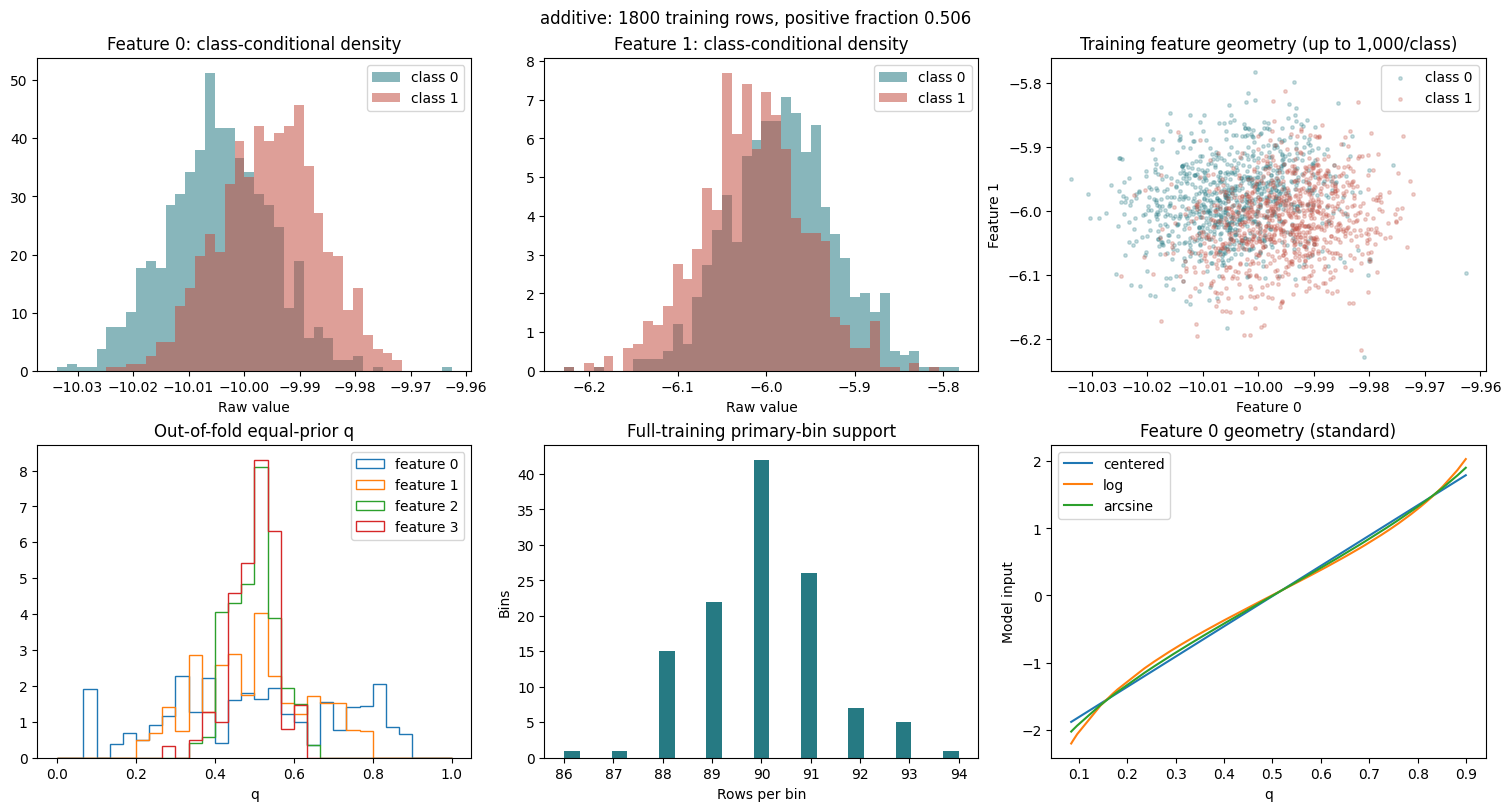

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.0841, 0.0841, 0.495, 0.8993, 0.8993] 0.0000 0.99365 0.7496178540560564
1 [0.2278, 0.2278, 0.5015, 0.7754, 0.7754] 0.0000 0.99942 0.6466261266823065
2 [0.363, 0.363, 0.5022, 0.6519, 0.6519] 0.0000 0.99996 0.49120446968761583
3 [0.2952, 0.2952, 0.5085, 0.6129, 0.6184] 0.0000 0.99984 0.5066113100382764
4 [0.3577, 0.3577, 0.495, 0.6232, 0.6239] 0.0000 0.99997 0.5058124459809853
5 [0.3661, 0.3661, 0.5011, 0.6291, 0.6291] 0.0000 0.99997 0.5129120879120879
Reference bins with a class count below 5: 0 / 120 | Empty bins: 0

moderate_additive | seed=42 | scaling=none
Constant historical-prior test loss: 0.693098
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     44   0.545575   0.535085   +0.000000  0.180837  0.804114  0.721667         n/a     0
mlp       centered     60   0.547254   0.538562   +0.000000  0.181443  

In [8]:
baseline_results = run_case("moderate_additive", CONFIG, ENCODER_CONFIG)

### 6.2. Separated Gaussian Classes

Generate 6,000 samples, four independent informative features and two nuisance features. In latent coordinates, informative features follow N(-1.2, 1) for class 0 and N(+1.2, 1) for class 1, with equal class prevalence and no label flips. Different feature units are applied afterward, identically in both classes.

This produces broader evidence ranges than the moderate additive baseline. With exact class-conditional densities, posterior log odds equal the prior log odds plus the sum of feature WoE: logistic regression on log evidence is correctly specified. Finite samples, bins and smoothing make the implemented comparison approximate. Check the q histogram and support rather than assuming all tails are extreme.

Generating configuration: {'seed': 42, 'n_samples': 6000, 'n_features': 6, 'scenario': 'class_conditional', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 4, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'fixe

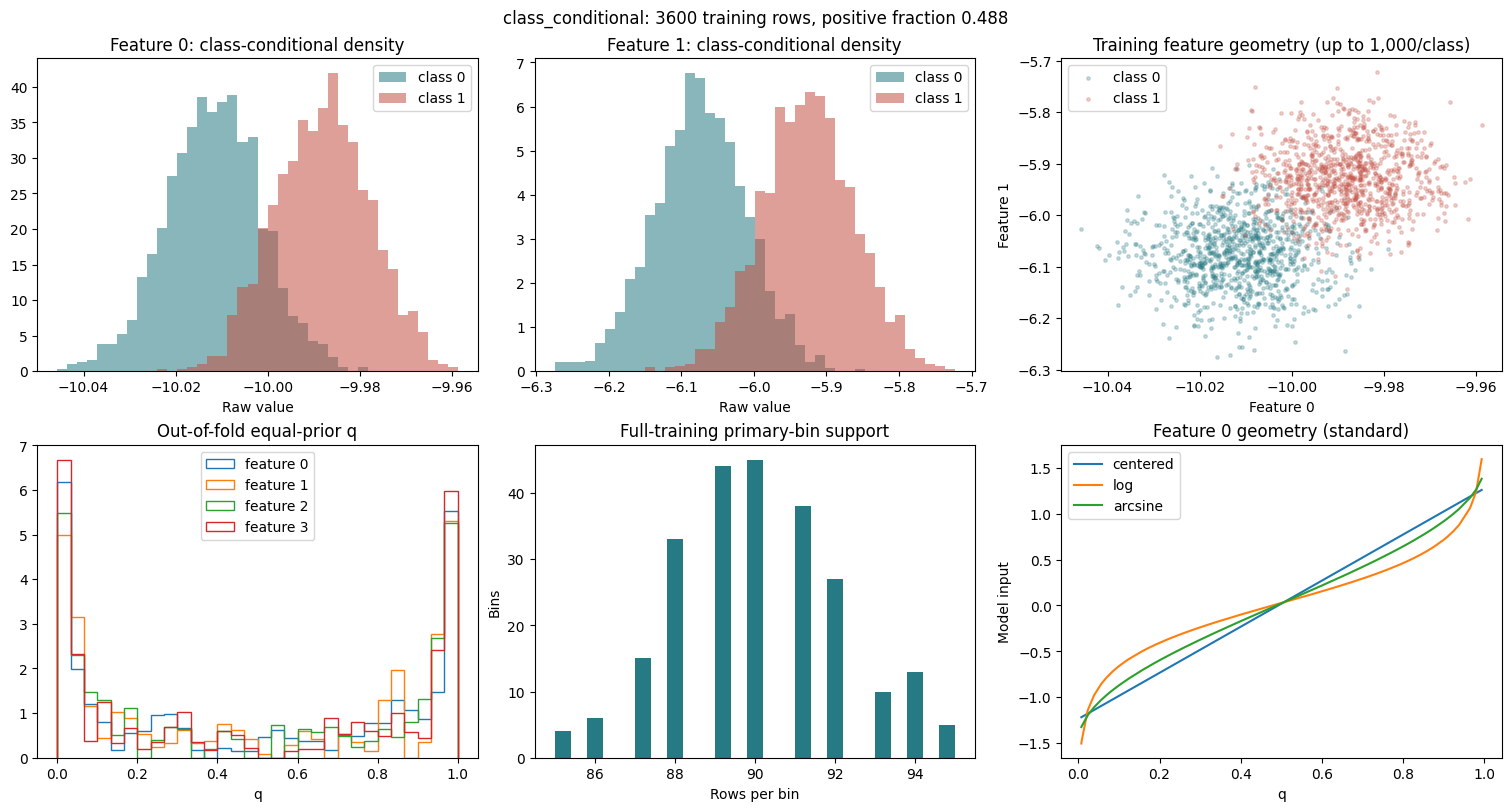

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.0075, 0.0075, 0.5124, 0.9933, 0.9933] 0.4356 0.96794 0.9483186250665925
1 [0.0073, 0.0074, 0.4539, 0.9933, 0.9935] 0.4689 0.96951 0.9502744771037454
2 [0.0074, 0.0074, 0.4593, 0.9934, 0.9934] 0.4953 0.97038 0.9520762204773046
3 [0.0075, 0.0075, 0.4332, 0.9935, 0.9935] 0.5086 0.97104 0.9562610891066174
4 [0.3233, 0.327, 0.4979, 0.6195, 0.6403] 0.0000 0.99992 0.4995223866768583
5 [0.3769, 0.3809, 0.5049, 0.6327, 0.6366] 0.0000 0.99997 0.49194805395347396
Reference bins with a class count below 5: 83 / 240 | Empty bins: 0

separated_classes | seed=42 | scaling=none
Constant historical-prior test loss: 0.692835
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     57   0.040360   0.032860   +0.000000  0.009438  0.999369  0.985000    0.021890  1119
mlp       centered     60   0.041930   0.033830   +0.000000  0.0095

In [9]:
SEPARATED_CONFIG = replace(CONFIG, scenario="class_conditional", distribution="normal", n_samples=6000,
                           n_features=6, n_informative=4, signal_strength=1.2,
                           class_prior=0.5, intercept=0.0, label_noise=0.0)
SEPARATED_ENCODER = replace(ENCODER_CONFIG, mode="fixed", num_bins=40, alpha=0.5)
separated_results = run_case("separated_classes", SEPARATED_CONFIG, SEPARATED_ENCODER)

### 6.3. Rare Class-Specific Regions

Generate 6,000 samples with four informative features and two nuisance features. Each informative feature independently comes from a shared N(0, 1) component with probability 94%, or a class-specific component shifted by -6 for class 0 and +6 for class 1 with probability 6%. Labels are balanced before 1% symmetric flips. Feature units are the same as in the baseline.

Most observations overlap, but small regions can carry strong evidence. Sixty bins and alpha = 0.5 let the diagnostics reveal whether those regions survive probability estimation. Compare whole-test loss with extreme-evidence slice loss; global AUC and accuracy can obscure behavior in a small slice.

Generating configuration: {'seed': 42, 'n_samples': 6000, 'n_features': 6, 'scenario': 'rare_mixture', 'distribution': 'normal', 'signal_strength': 6.0, 'intercept': 0.0, 'label_noise': 0.01, 'class_prior': 0.5, 'n_informative': 4, 'rare_fraction': 0.06, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'fixed', 

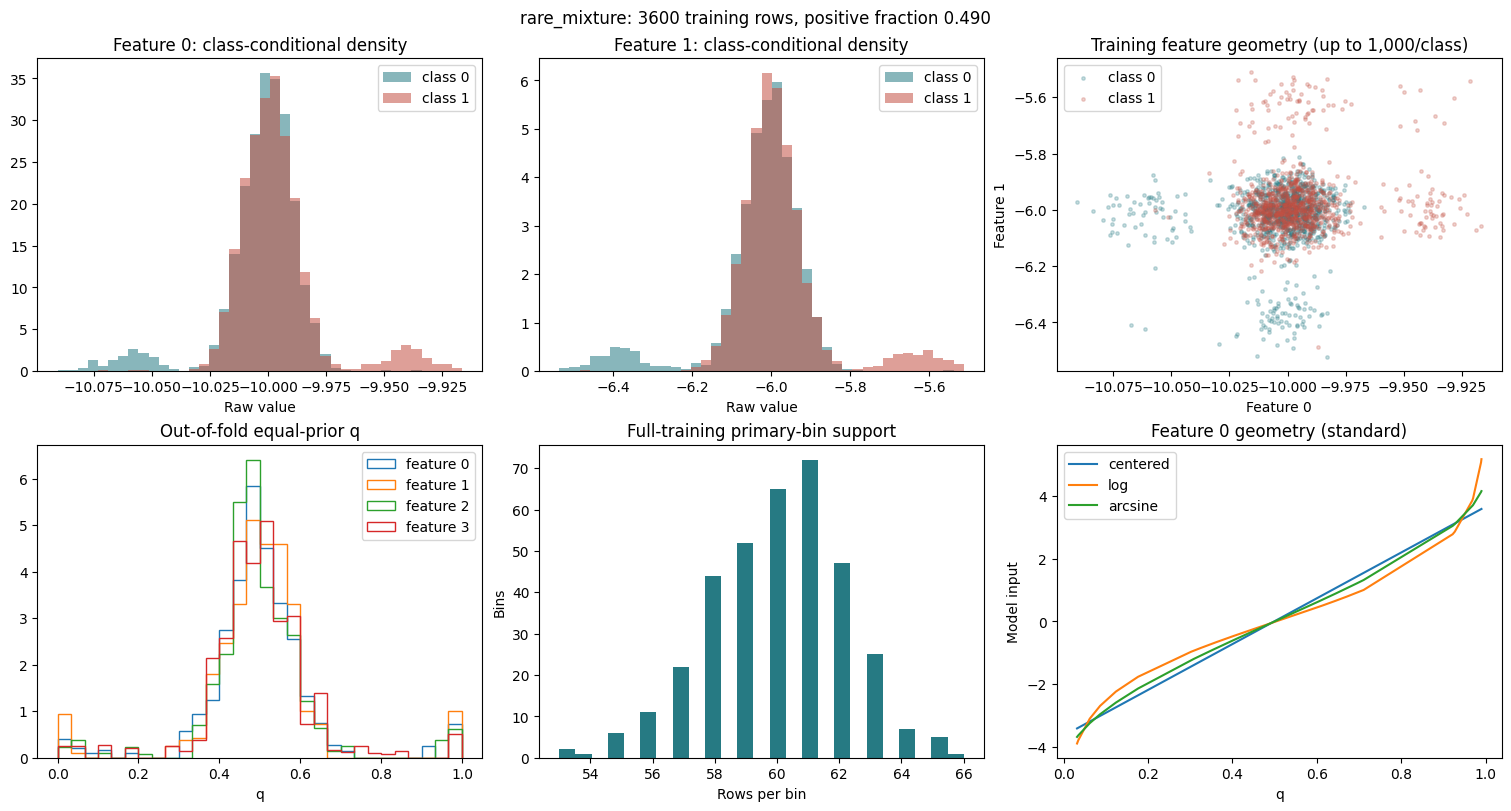

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.0318, 0.0332, 0.4993, 0.97, 0.9898] 0.0411 0.96422 0.5511629759611392
1 [0.0106, 0.0118, 0.5101, 0.9893, 0.9898] 0.0675 0.96437 0.5732284721538206
2 [0.0111, 0.0339, 0.4879, 0.9679, 0.9898] 0.0378 0.96380 0.5643410749789031
3 [0.0106, 0.0339, 0.4988, 0.9898, 0.99] 0.0342 0.94469 0.5636753615956865
4 [0.2044, 0.2737, 0.4993, 0.6655, 0.7146] 0.0000 0.99913 0.504904695842163
5 [0.302, 0.353, 0.4991, 0.6427, 0.6721] 0.0000 0.99992 0.47540488558282806
Reference bins with a class count below 5: 12 / 360 | Empty bins: 0

rare_regions | seed=42 | scaling=none
Constant historical-prior test loss: 0.692913
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     12   0.613644   0.608946   +0.000000  0.213836  0.690385  0.612500    0.201146   207
mlp       centered     60   0.603647   0.597087   +0.000000  0.209699  0.69136

In [10]:
RARE_CONFIG = replace(CONFIG, scenario="rare_mixture", distribution="normal", n_samples=6000,
                      n_features=6, n_informative=4, signal_strength=6.0,
                      rare_fraction=0.06, class_prior=0.5, intercept=0.0, label_noise=0.01)
RARE_ENCODER = replace(ENCODER_CONFIG, mode="fixed", num_bins=60, alpha=0.5)
rare_results = run_case("rare_regions", RARE_CONFIG, RARE_ENCODER)

### 6.4. Equal Means, Different Variances

Generate 6,000 samples with four conditionally independent informative features: class 0 has latent N(0, 1) features, class 1 has N(0, 9), and two nuisance features have the same distribution in both classes. The second normal-distribution parameter is variance. Pre-flip class prevalence is 50%; label flips occur at 1%. Means match, but both tails favor the broader class and the center favors the narrower class.

This changes class-conditional shape rather than simply stretching both classes. Before label flips, the Bayes log-likelihood ratio is additive in squared features, making log evidence a useful model-specification reference. Estimated bins and label noise make that reference approximate. Examine both raw tails and estimated q.

Generating configuration: {'seed': 42, 'n_samples': 6000, 'n_features': 6, 'scenario': 'variance', 'distribution': 'normal', 'signal_strength': 3.0, 'intercept': 0.0, 'label_noise': 0.01, 'class_prior': 0.5, 'n_informative': 4, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'fixed', 'num

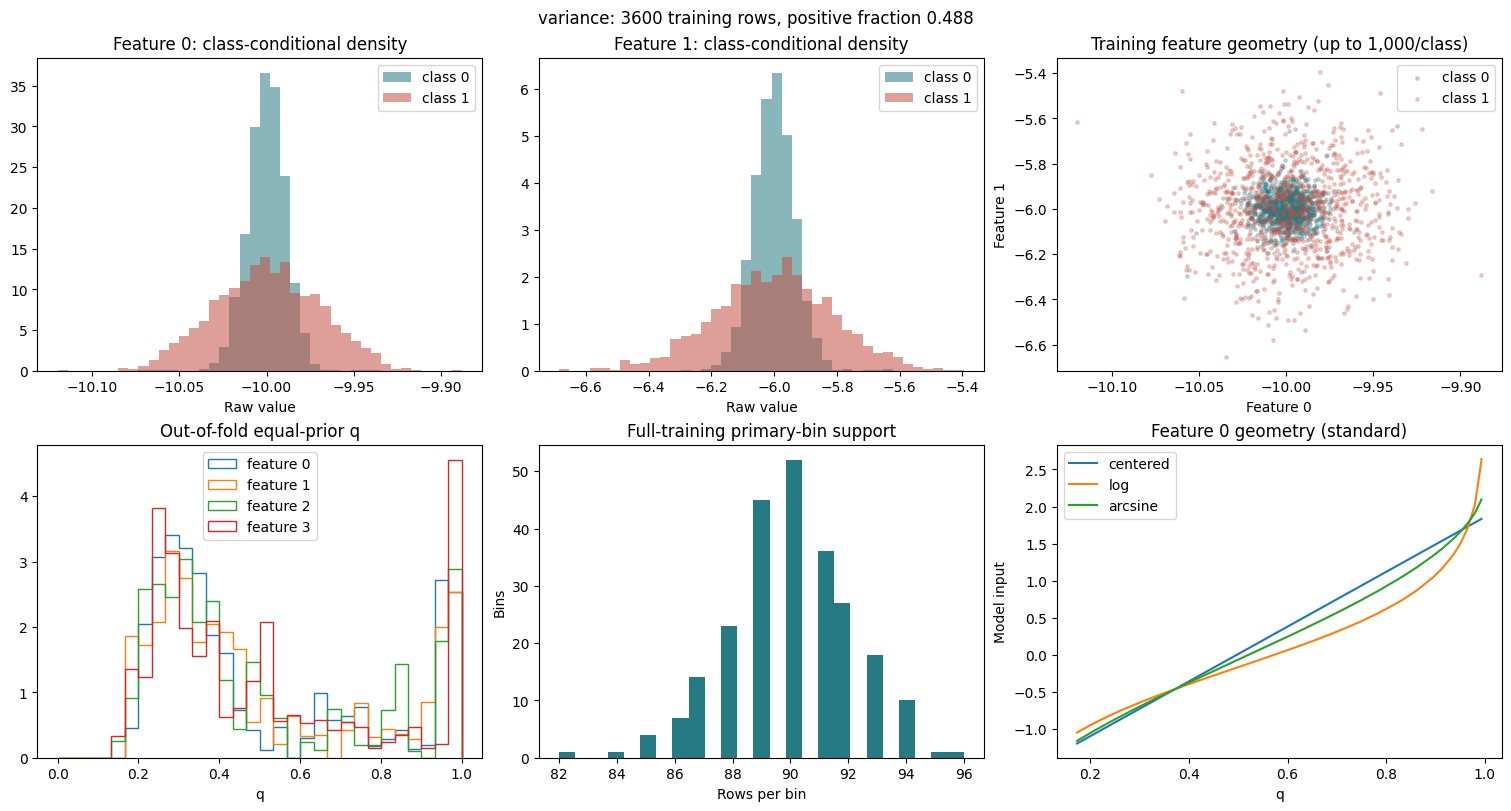

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.1735, 0.1786, 0.3662, 0.9931, 0.9931] 0.1558 0.96612 0.7731404434197169
1 [0.1756, 0.1758, 0.393, 0.9932, 0.9934] 0.1511 0.96823 0.7863260545910304
2 [0.1341, 0.1733, 0.3755, 0.993, 0.9933] 0.1525 0.96782 0.7843987201338047
3 [0.1435, 0.1606, 0.3896, 0.9932, 0.9932] 0.1589 0.96254 0.7880736568492327
4 [0.3117, 0.3607, 0.4976, 0.624, 0.624] 0.0000 0.99995 0.5071650457313448
5 [0.3562, 0.3896, 0.4976, 0.6098, 0.6362] 0.0000 0.99997 0.5020392810588512
Reference bins with a class count below 5: 24 / 240 | Empty bins: 0

variance_tails | seed=42 | scaling=none
Constant historical-prior test loss: 0.692875
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     43   0.245479   0.249891   +0.000000  0.069930  0.959292  0.909167    0.156787   451
mlp       centered     60   0.239679   0.242086   +0.000000  0.068465  0.9

In [11]:
VARIANCE_CONFIG = replace(CONFIG, scenario="variance", distribution="normal", n_samples=6000,
                          n_features=6, n_informative=4, signal_strength=3.0,
                          class_prior=0.5, intercept=0.0, label_noise=0.01)
VARIANCE_ENCODER = replace(ENCODER_CONFIG, mode="fixed", num_bins=40, alpha=0.5)
variance_results = run_case("variance_tails", VARIANCE_CONFIG, VARIANCE_ENCODER)

### 6.5. Sparse, Imbalanced Rare Evidence

Use the same rare-mixture mechanism as 6.3, but only 1,000 samples, 15% pre-flip positive prevalence, and 20 features (four informative, 16 nuisance). Sixty bins and alpha = 0.5 now operate with much less minority-class support. Each informative feature has an independent 6% chance of a class-directed six-standard-deviation shift; all observations remain continuous.

This combined stress probes noisy tail estimates, nuisance-feature fitting and smoothing under imbalance. Compare support diagnostics and extreme-slice loss with 6.3; differences cannot be attributed to sample size alone. Symmetric label flips also move observed prevalence toward 50%.

Generating configuration: {'seed': 42, 'n_samples': 1000, 'n_features': 20, 'scenario': 'rare_mixture', 'distribution': 'normal', 'signal_strength': 6.0, 'intercept': 0.0, 'label_noise': 0.01, 'class_prior': 0.15, 'n_informative': 4, 'rare_fraction': 0.06, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'fixed'

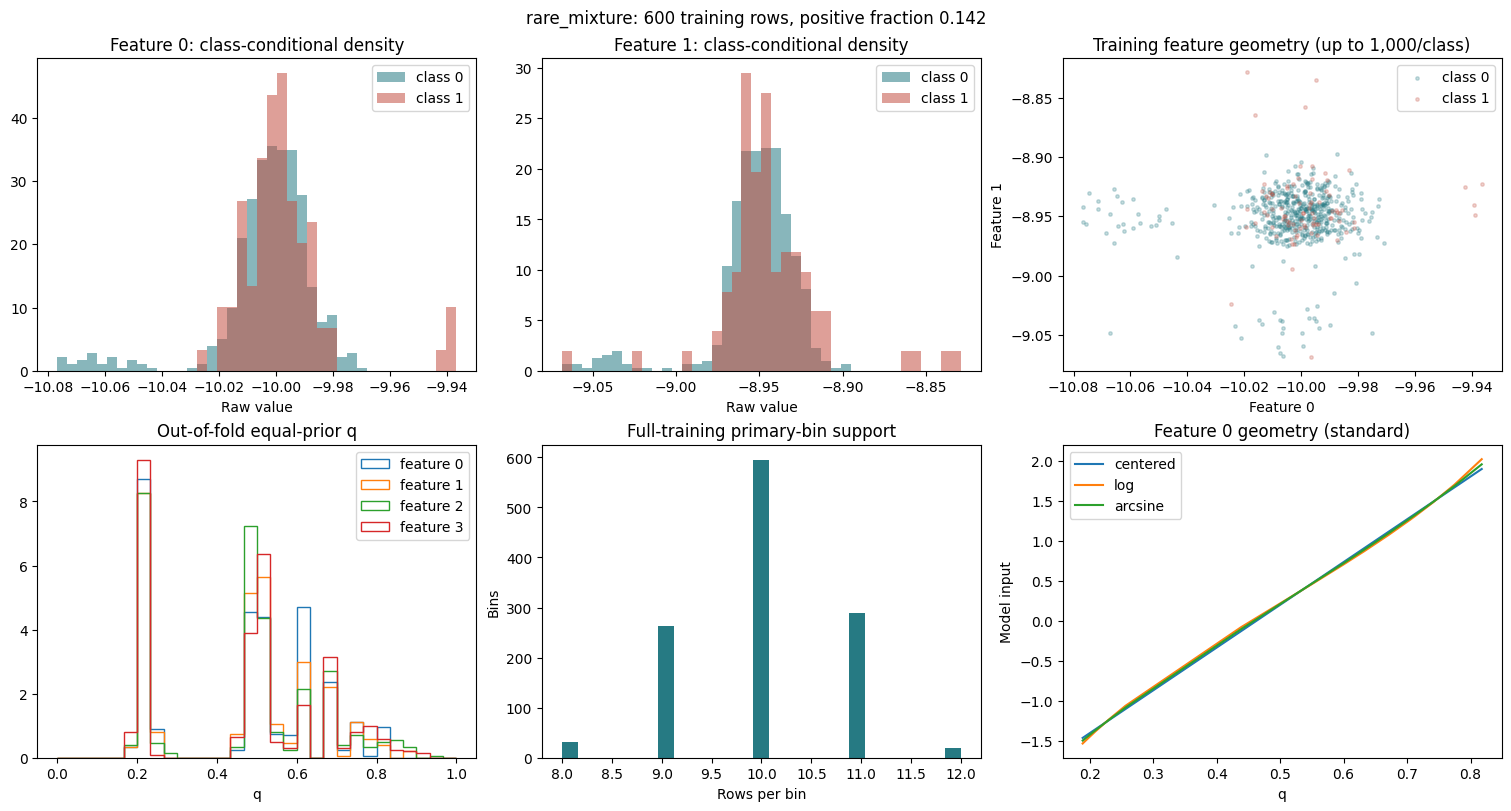

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.1889, 0.1909, 0.5053, 0.8157, 0.8176] 0.0000 0.99938 0.43039406053683604
1 [0.1889, 0.1909, 0.4728, 0.8176, 0.8928] 0.0000 0.99900 0.4557509994288978
2 [0.1889, 0.1909, 0.4695, 0.8743, 0.9568] 0.0017 0.99738 0.579565962307253
3 [0.1889, 0.1889, 0.5053, 0.8743, 0.908] 0.0000 0.99847 0.5751913192461451
4 [0.2066, 0.2066, 0.4728, 0.7772, 0.8176] 0.0000 0.99947 0.4662135922330096
5 [0.1889, 0.1889, 0.4728, 0.8157, 0.8522] 0.0000 0.99930 0.5158537978298114
6 [0.2066, 0.2066, 0.5053, 0.7749, 0.7858] 0.0000 0.99954 0.5256767561393489
7 [0.1889, 0.1889, 0.4695, 0.8744, 0.92] 0.0000 0.99781 0.5528612221587664
8 [0.1889, 0.2064, 0.5053, 0.8157, 0.8157] 0.0000 0.99949 0.49458595088520846
9 [0.1889, 0.2066, 0.5053, 0.8157, 0.8522] 0.0000 0.99947 0.44398629354654495
10 [0.1889, 0.2066, 0.5053, 0.8157, 0.8522] 0.0000 0.99930 0.5172815533980583
11 [0.1889, 0.1889, 0.5053, 0.8157, 0.8157] 0.0000 0.999

In [12]:
SPARSE_CONFIG = replace(CONFIG, scenario="rare_mixture", distribution="normal", n_samples=1000,
                        n_features=20, n_informative=4, signal_strength=6.0,
                        rare_fraction=0.06, class_prior=0.15, intercept=0.0, label_noise=0.01)
SPARSE_ENCODER = replace(ENCODER_CONFIG, mode="fixed", num_bins=60, alpha=0.5)
sparse_results = run_case("sparse_imbalanced", SPARSE_CONFIG, SPARSE_ENCODER)

### 6.6. Limited Predictability: Many Weak Correlated Indicators

Generate 4,000 observations of 32 continuous indicators. Twenty-four indicators weakly observe four shared Gaussian factors, with heterogeneous loadings from 0.2 to 1 and observation noise of standard deviation 3. Eight indicators are pure nuisance. Repeated observations of shared factors create redundancy rather than independent additive evidence.

The outcome probability is sigmoid(1.2 * sum(factors)/sqrt(4) + 3 * hidden_driver), followed by a Bernoulli draw. The independent hidden driver is unavailable to every model. This gives a weak-information task without constructing individual highly separated indicators. The exact individual predictive strengths are measured by out-of-fold q AUC, not assumed.

Compare the baseline with two single-control changes: reduce hidden-driver strength from 3 to 0.5 while preserving the observed feature matrix; or set observed-factor signal strength to zero as a null reference. The latter retains hidden outcome variation but makes observed indicators uninformative in the population. Each table includes a constant training-prior baseline.

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 32, 'scenario': 'weak_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 24, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'fixed',

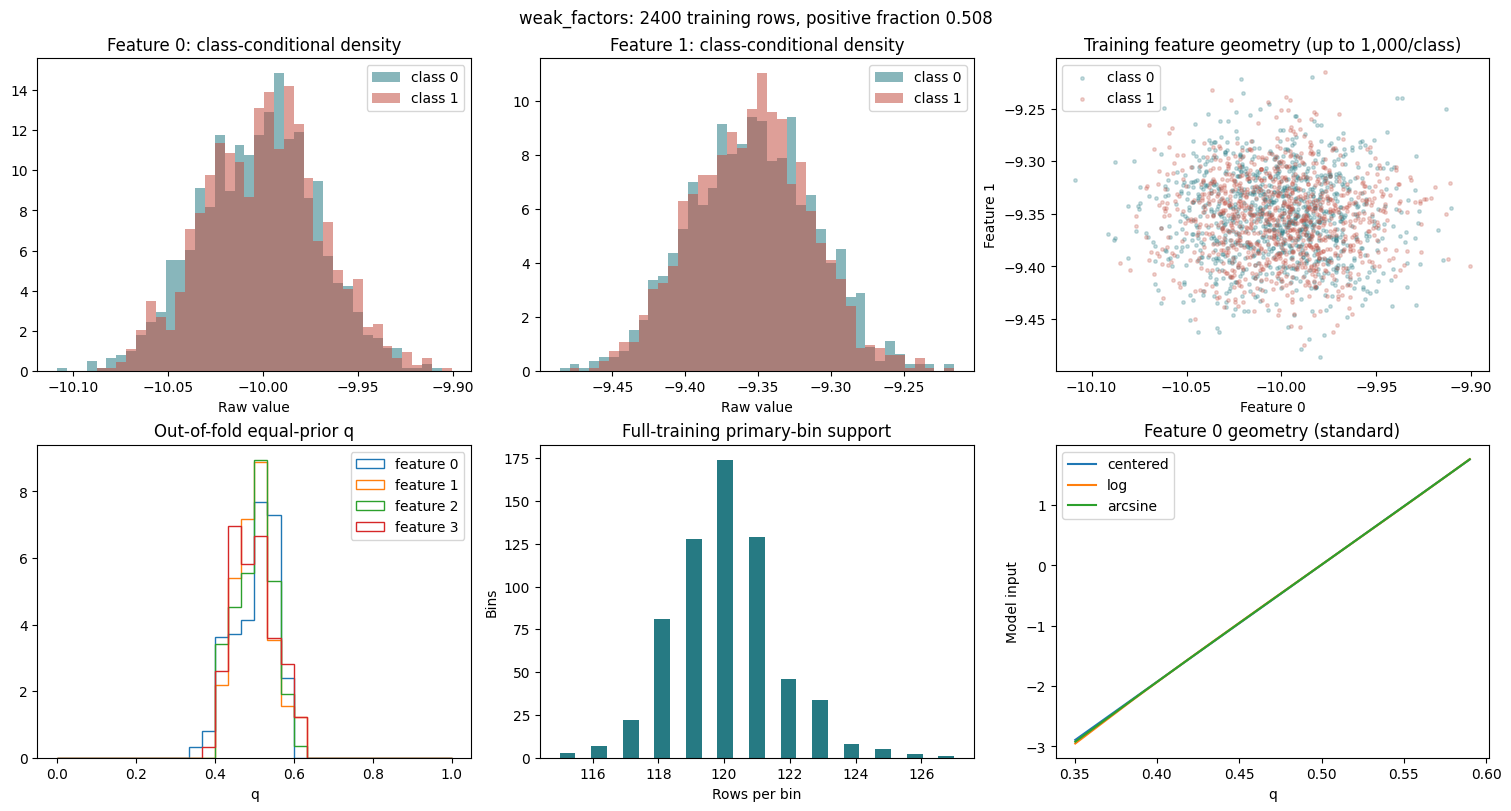

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3504, 0.3504, 0.508, 0.59, 0.59] 0.0000 0.99997 0.5056397610447346
1 [0.4007, 0.4007, 0.5025, 0.62, 0.62] 0.0000 0.99998 0.5058936510141707
2 [0.4032, 0.4032, 0.508, 0.616, 0.616] 0.0000 0.99999 0.5008936510141706
3 [0.3922, 0.3922, 0.4972, 0.6076, 0.6076] 0.0000 0.99999 0.49449916643512093
4 [0.4052, 0.4052, 0.4973, 0.6409, 0.6409] 0.0000 0.99997 0.4818189080300084
5 [0.3944, 0.3944, 0.5027, 0.5879, 0.5879] 0.0000 0.99999 0.47956654626285083
6 [0.3769, 0.3836, 0.5027, 0.616, 0.6173] 0.0000 0.99998 0.5143136982495138
7 [0.4052, 0.4052, 0.5027, 0.62, 0.62] 0.0000 0.99998 0.4732946651847735
8 [0.416, 0.416, 0.5025, 0.6009, 0.6009] 0.0000 0.99999 0.49850722422895244
9 [0.4176, 0.4176, 0.5027, 0.6033, 0.6033] 0.0000 0.99999 0.49926785218116143
10 [0.4097, 0.4097, 0.4918, 0.652, 0.652] 0.0000 0.99995 0.4963601000277855
11 [0.4052, 0.4052, 0.5027, 0.6187, 0.6187] 0.0000 0.99999 0.47281710197

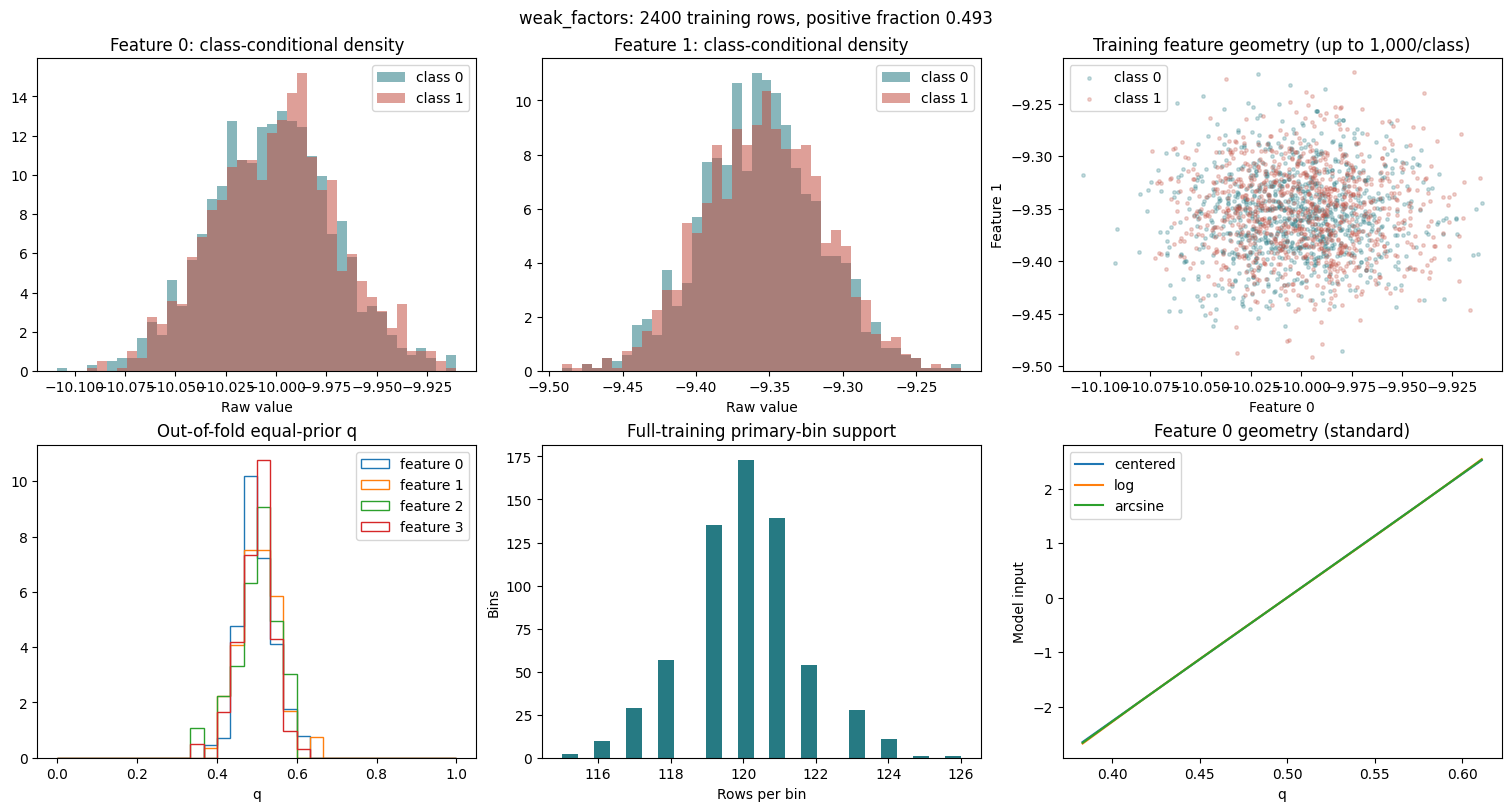

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.383, 0.383, 0.4909, 0.6111, 0.6111] 0.0000 0.99998 0.48691612413880286
1 [0.3798, 0.3798, 0.5017, 0.6548, 0.6548] 0.0000 0.99994 0.48454724594033105
2 [0.3505, 0.3505, 0.5071, 0.5911, 0.5911] 0.0000 0.99995 0.5091653811077361
3 [0.3616, 0.3616, 0.5016, 0.6046, 0.6046] 0.0000 0.99997 0.47526760579032873
4 [0.3938, 0.3938, 0.4954, 0.6399, 0.6399] 0.0000 0.99997 0.49979336130653995
5 [0.3733, 0.3733, 0.501, 0.687, 0.687] 0.0000 0.99989 0.5146366180434824
6 [0.3465, 0.3619, 0.5017, 0.5982, 0.5982] 0.0000 0.99996 0.4947725619933445
7 [0.3981, 0.4046, 0.5016, 0.587, 0.6025] 0.0000 0.99999 0.4953334384470216
8 [0.3733, 0.3733, 0.5017, 0.6046, 0.6046] 0.0000 0.99998 0.5217915262160253
9 [0.3717, 0.3717, 0.5124, 0.6303, 0.6409] 0.0000 0.99997 0.5182908236444675
10 [0.3762, 0.3762, 0.501, 0.6068, 0.6586] 0.0000 0.99996 0.5214150617728142
11 [0.3913, 0.3913, 0.5018, 0.6586, 0.6586] 0.0000 0.99994

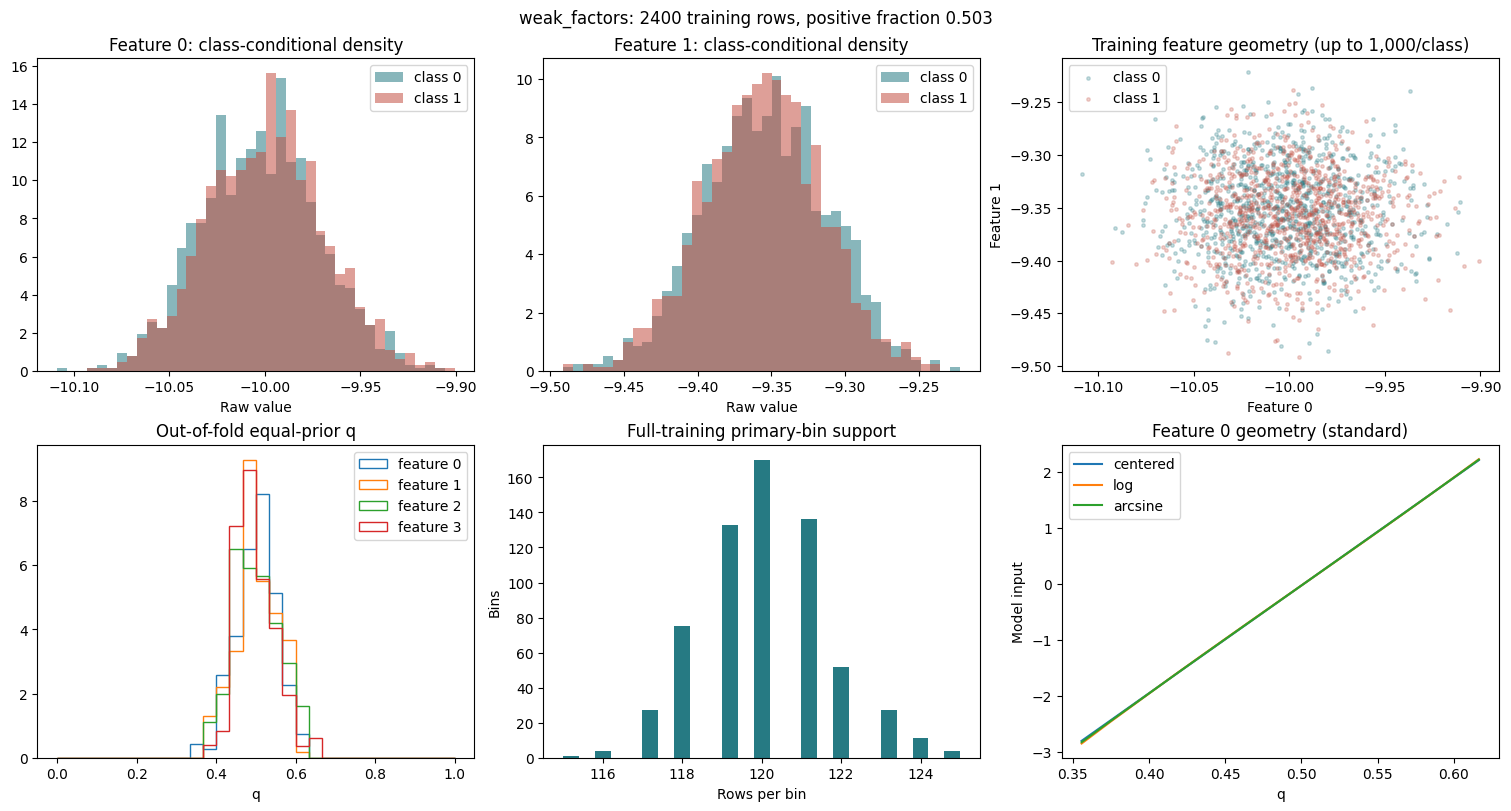

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3557, 0.3557, 0.5022, 0.6165, 0.6165] 0.0000 0.99997 0.49775406684741547
1 [0.3774, 0.3774, 0.4967, 0.5903, 0.6013] 0.0000 0.99998 0.5124502061202719
2 [0.3706, 0.3706, 0.4967, 0.6303, 0.6303] 0.0000 0.99997 0.5075718643050802
3 [0.3969, 0.3969, 0.4914, 0.6454, 0.6454] 0.0000 0.99996 0.4895800924485533
4 [0.3626, 0.3858, 0.4967, 0.6492, 0.6492] 0.0000 0.99996 0.5066704353526823
5 [0.3864, 0.3864, 0.5076, 0.5947, 0.5947] 0.0000 0.99999 0.4646442619671985
6 [0.3882, 0.3882, 0.5022, 0.6165, 0.6165] 0.0000 0.99998 0.4607291574069958
7 [0.4162, 0.4162, 0.5021, 0.6139, 0.6139] 0.0000 0.99999 0.4922760456020268
8 [0.3789, 0.3789, 0.4967, 0.6123, 0.6123] 0.0000 0.99998 0.4870209509311525
9 [0.3557, 0.3557, 0.5022, 0.6036, 0.6036] 0.0000 0.99996 0.4903405429130184
10 [0.3774, 0.3774, 0.4967, 0.6674, 0.6674] 0.0000 0.99995 0.5089948442152985
11 [0.3815, 0.3815, 0.502, 0.5775, 0.6013] 0.0000 0.99

In [13]:
WEAK_CONFIG = replace(CONFIG, scenario="weak_factors", distribution="normal", n_samples=4000,
                      n_features=32, n_informative=24, n_factors=4, signal_strength=1.2,
                      observation_noise=3.0, hidden_strength=3.0, intercept=0.0, label_noise=0.0)
WEAK_ENCODER = replace(ENCODER_CONFIG, mode="fixed", num_bins=20, alpha=1.0)
weak_results = run_case("weak_factors", WEAK_CONFIG, WEAK_ENCODER)
less_hidden = run_case("weak_less_hidden", replace(WEAK_CONFIG, hidden_strength=0.5), WEAK_ENCODER)
null_results = run_case("weak_null", replace(WEAK_CONFIG, signal_strength=0.0), WEAK_ENCODER)

### 6.7. Unstable Estimation: Independent Rare Contamination

Keep the weak-factor task, latent drivers, labels, splits, bin count and smoothing fixed. Contaminate 1% of individual feature observations with independent signed Pareto shocks (tail index 1.5), then increase shock scale from 20 to 100 without changing event locations or signs. These shocks have no additional outcome information.

Compare with the clean weak-factor case in 6.6. Unlike class-specific rare regions in 6.3, these extremes are unreliable observations rather than deliberately informative subpopulations. Percentile partitions may be relatively insensitive to further magnitude increases once ranks stabilize; Section 6.8 explicitly checks raw-width partitions.

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 32, 'scenario': 'weak_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 24, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.01, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'fixed'

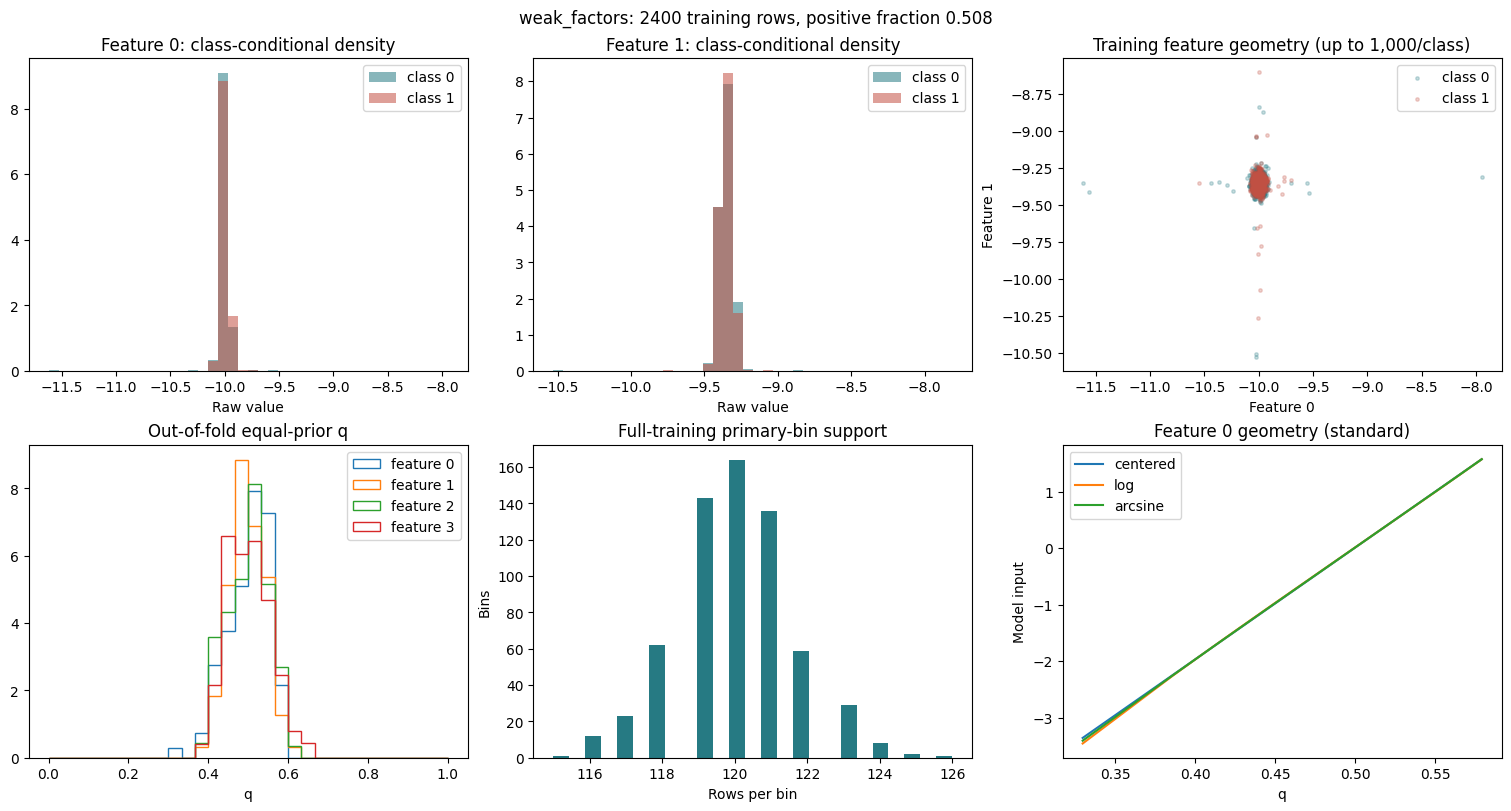

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3297, 0.3859, 0.503, 0.579, 0.579] 0.0000 0.99994 0.513238399555432
1 [0.3769, 0.3769, 0.4972, 0.6076, 0.6076] 0.0000 0.99998 0.505501875520978
2 [0.3987, 0.3987, 0.503, 0.6228, 0.6228] 0.0000 0.99999 0.5042216587941095
3 [0.3944, 0.3944, 0.4972, 0.6409, 0.6409] 0.0000 0.99997 0.4945255626562934
4 [0.4052, 0.4052, 0.4973, 0.6377, 0.6377] 0.0000 0.99998 0.486785565434843
5 [0.3836, 0.3836, 0.5083, 0.5772, 0.579] 0.0000 0.99999 0.4830671714365101
6 [0.3836, 0.3859, 0.4918, 0.6257, 0.6257] 0.0000 0.99998 0.5183446790775216
7 [0.4114, 0.416, 0.4973, 0.5986, 0.5986] 0.0000 0.99999 0.4702632675743262
8 [0.416, 0.419, 0.4971, 0.6009, 0.6009] 0.0000 0.99999 0.4907300639066407
9 [0.416, 0.416, 0.5027, 0.6027, 0.6027] 0.0000 0.99999 0.49586030841900536
10 [0.3855, 0.3855, 0.4918, 0.6298, 0.6298] 0.0000 0.99997 0.5031724090025007
11 [0.3769, 0.4093, 0.4972, 0.6187, 0.6187] 0.0000 0.99998 0.474951

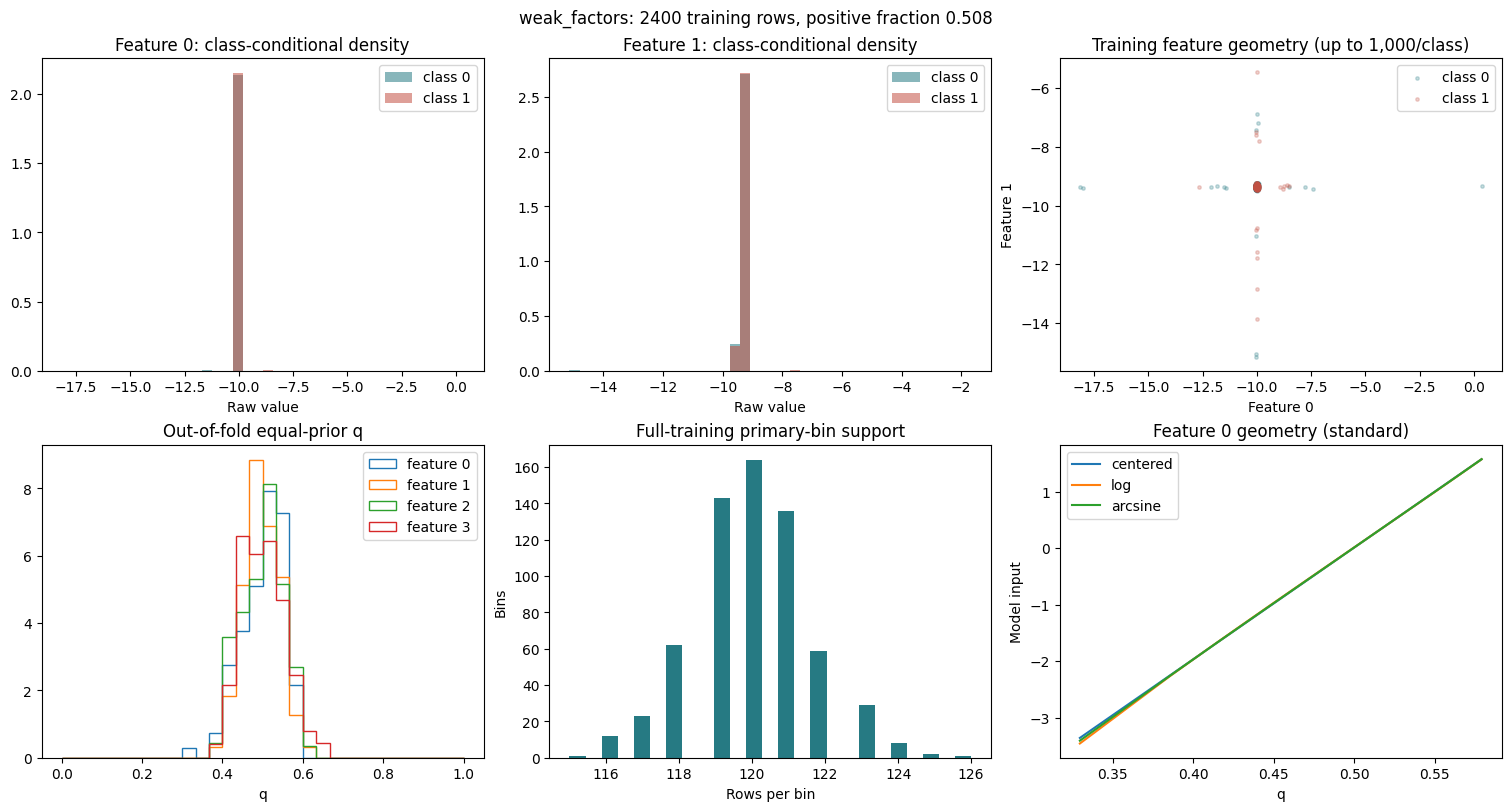

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3297, 0.3859, 0.503, 0.579, 0.579] 0.0000 0.99994 0.513238399555432
1 [0.3769, 0.3769, 0.4972, 0.6076, 0.6076] 0.0000 0.99998 0.505501875520978
2 [0.3987, 0.3987, 0.503, 0.6228, 0.6228] 0.0000 0.99999 0.5042216587941095
3 [0.3944, 0.3944, 0.4972, 0.6409, 0.6409] 0.0000 0.99997 0.4945255626562934
4 [0.4052, 0.4052, 0.4973, 0.6377, 0.6377] 0.0000 0.99998 0.486785565434843
5 [0.3836, 0.3836, 0.5083, 0.5772, 0.579] 0.0000 0.99999 0.4830671714365101
6 [0.3836, 0.3859, 0.4918, 0.6257, 0.6257] 0.0000 0.99998 0.5183446790775216
7 [0.4114, 0.416, 0.4973, 0.5986, 0.5986] 0.0000 0.99999 0.4702632675743262
8 [0.416, 0.419, 0.4971, 0.6009, 0.6009] 0.0000 0.99999 0.4907300639066407
9 [0.416, 0.416, 0.5027, 0.6027, 0.6027] 0.0000 0.99999 0.49586030841900536
10 [0.3855, 0.3855, 0.4918, 0.6298, 0.6298] 0.0000 0.99997 0.5031724090025007
11 [0.3769, 0.4093, 0.4972, 0.6187, 0.6187] 0.0000 0.99998 0.474951

In [14]:
CONTAMINATED_CONFIG = replace(WEAK_CONFIG, contamination_rate=0.01, contamination_scale=20.0)
contaminated = run_case("weak_contaminated", CONTAMINATED_CONFIG, WEAK_ENCODER)
large_tails = run_case("weak_larger_tails", replace(CONTAMINATED_CONFIG, contamination_scale=100.0), WEAK_ENCODER)

### 6.8. Estimator Geometry: Partitions, Resolution and Smoothing

Cross the clean/contaminated weak-factor pair with raw equal-width bins. This isolates whether tail magnitude stretches historical min/max partitions and concentrates ordinary observations into very few bins. Compare these two results with the percentile counterparts in 6.6 and 6.7, using the same rows and labels.

Two additional contrasts hold contaminated data fixed: increase percentile bins from 20 to 80 with alpha unchanged, or reduce alpha from 1 to 0.1 with bin count unchanged. Inspect empty bins, class counts, individual-feature q AUCs and probability ranges before the model results. These changes affect the estimator before any evidence transformation. Each representation within a condition still receives the exact same q estimates.

Both native and standardized inputs are evaluated. Differences that remain after standardization can reflect nonlinear geometry, estimation error, model specification or optimization, not merely overall input scale.

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 32, 'scenario': 'weak_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 24, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'raw_fix

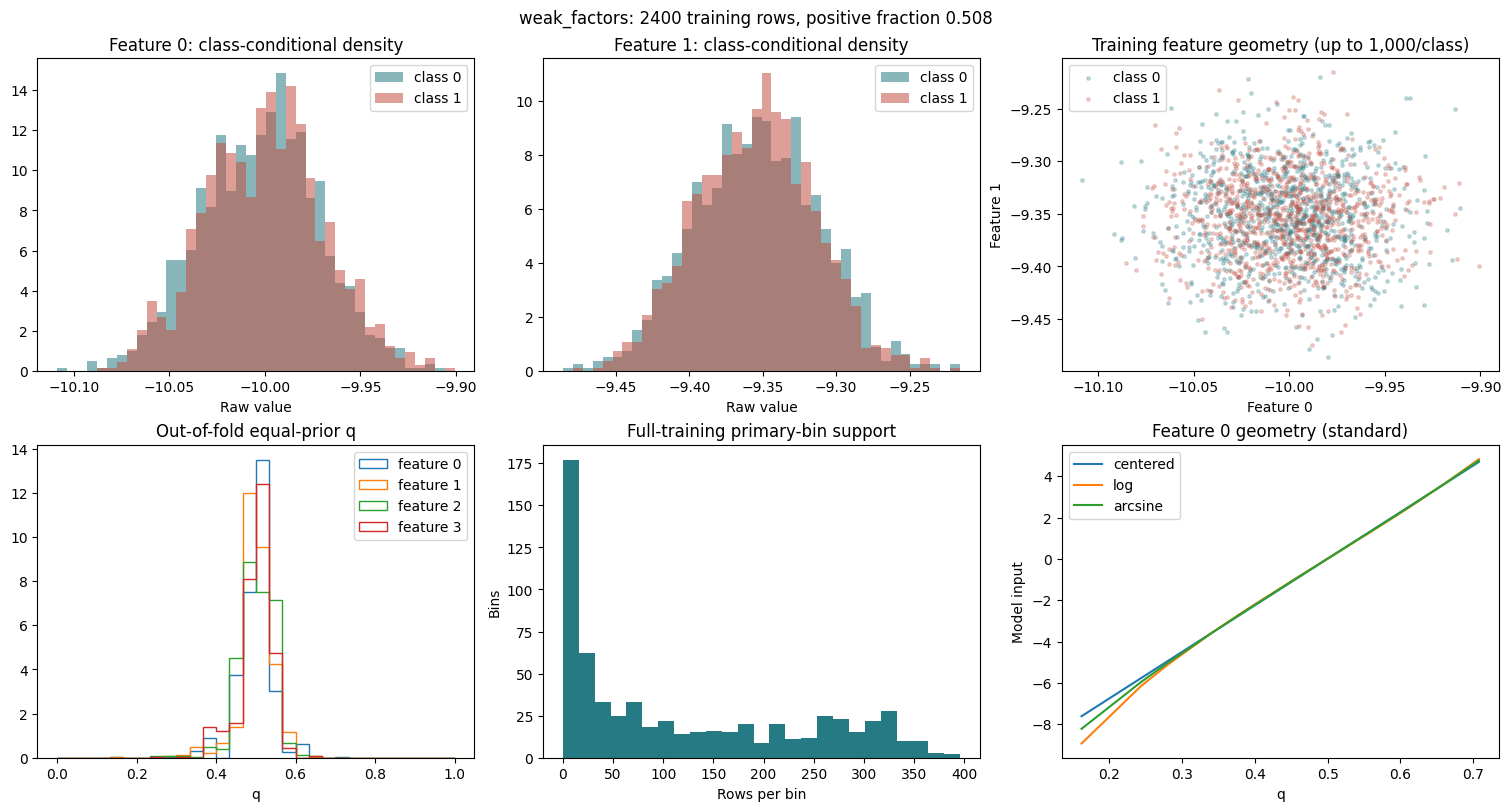

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.1622, 0.3418, 0.5038, 0.613, 0.7076] 0.0000 0.99860 0.515043414837455
1 [0.1622, 0.344, 0.5001, 0.5698, 0.6594] 0.0000 0.99926 0.48992741039177545
2 [0.2663, 0.3674, 0.5037, 0.5921, 0.6594] 0.0000 0.99969 0.5140160461239234
3 [0.2439, 0.3839, 0.507, 0.569, 0.6594] 0.0000 0.99974 0.491079813837177
4 [0.2439, 0.3674, 0.4983, 0.5624, 0.7438] 0.0000 0.99950 0.48498437065851624
5 [0.2791, 0.365, 0.5009, 0.5725, 0.6396] 0.0000 0.99988 0.4875347318699639
6 [0.2439, 0.3405, 0.5108, 0.6033, 0.6594] 0.0000 0.99974 0.5215521672686858
7 [0.2439, 0.4104, 0.4979, 0.6051, 0.7947] 0.0000 0.99970 0.47306890803000834
8 [0.1389, 0.225, 0.5072, 0.6173, 0.7721] 0.0000 0.99743 0.48242741039177545
9 [0.1389, 0.3674, 0.5004, 0.6366, 0.7947] 0.0000 0.99831 0.49127604890247295
10 [0.2439, 0.4088, 0.4994, 0.6433, 0.8288] 0.0000 0.99897 0.5035815504306752
11 [0.2791, 0.4012, 0.5013, 0.6113, 0.7076] 0.0000 0.99973

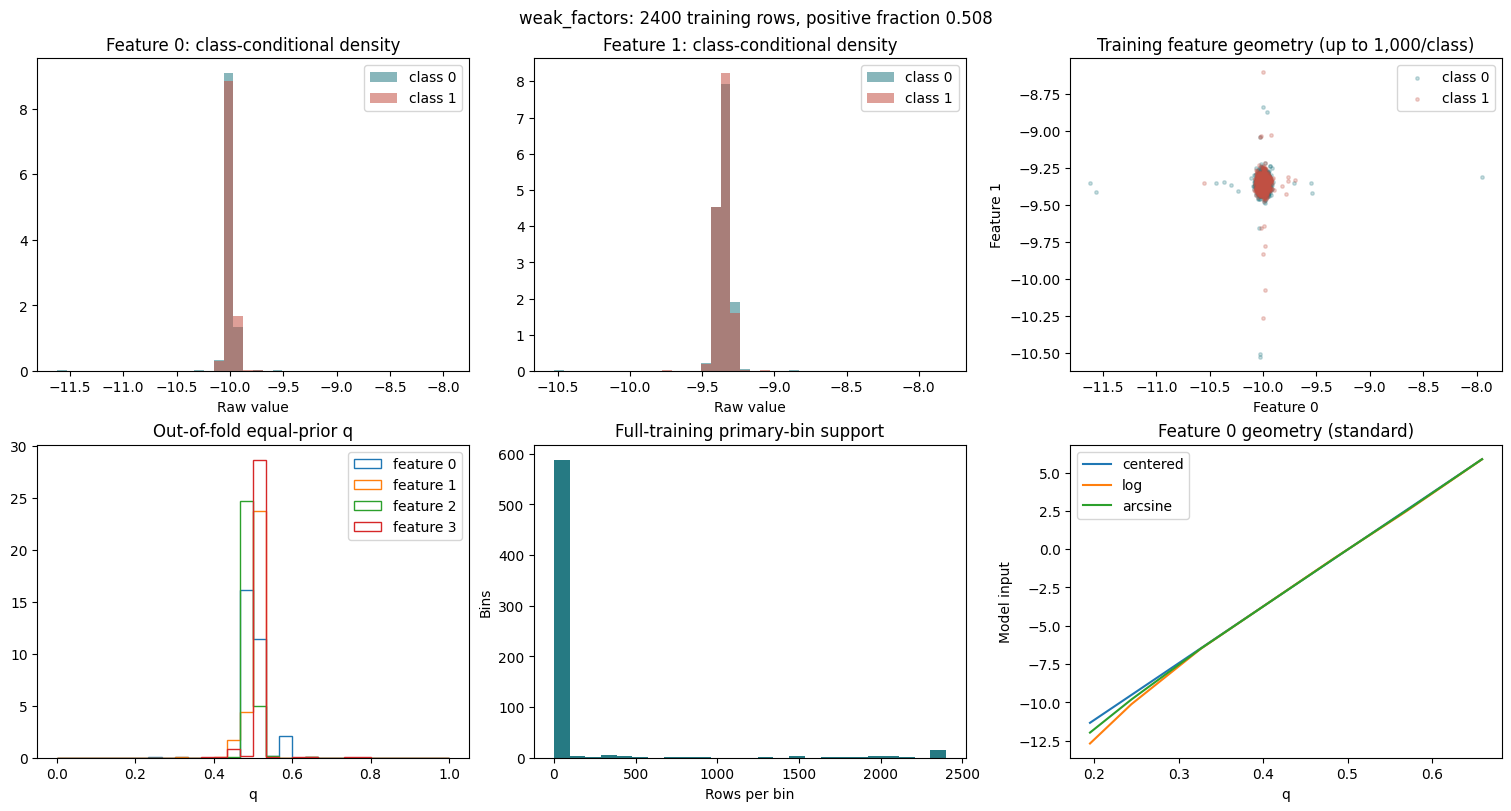

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.1948, 0.4817, 0.4909, 0.5702, 0.6594] 0.0000 0.99892 0.5078688524590165
1 [0.3261, 0.4349, 0.506, 0.5136, 0.7438] 0.0000 0.99973 0.49944429008057795
2 [0.4364, 0.469, 0.4995, 0.5157, 0.6594] 0.0000 0.99987 0.4981658099472076
3 [0.2439, 0.4392, 0.5011, 0.5049, 0.7947] 0.0000 0.99855 0.497404834676299
4 [0.3261, 0.4777, 0.498, 0.5079, 0.7947] 0.0000 0.99914 0.5044505418171714
5 [0.3261, 0.4711, 0.5026, 0.5126, 0.7438] 0.0000 0.99964 0.4980498055015282
6 [0.3922, 0.4553, 0.5001, 0.5303, 0.6594] 0.0000 0.99993 0.5177691719922201
7 [0.4918, 0.4953, 0.5002, 0.5007, 0.6594] 0.0000 0.99990 0.47852424284523476
8 [0.3261, 0.4915, 0.4999, 0.5166, 0.7076] 0.0000 0.99974 0.505385523756599
9 [0.2439, 0.4948, 0.5014, 0.5095, 0.6594] 0.0000 0.99926 0.4988708669074743
10 [0.1948, 0.4656, 0.4966, 0.5394, 0.6594] 0.0000 0.99831 0.5017661155876633
11 [0.2439, 0.4443, 0.5004, 0.5157, 0.6594] 0.0000 0.99935

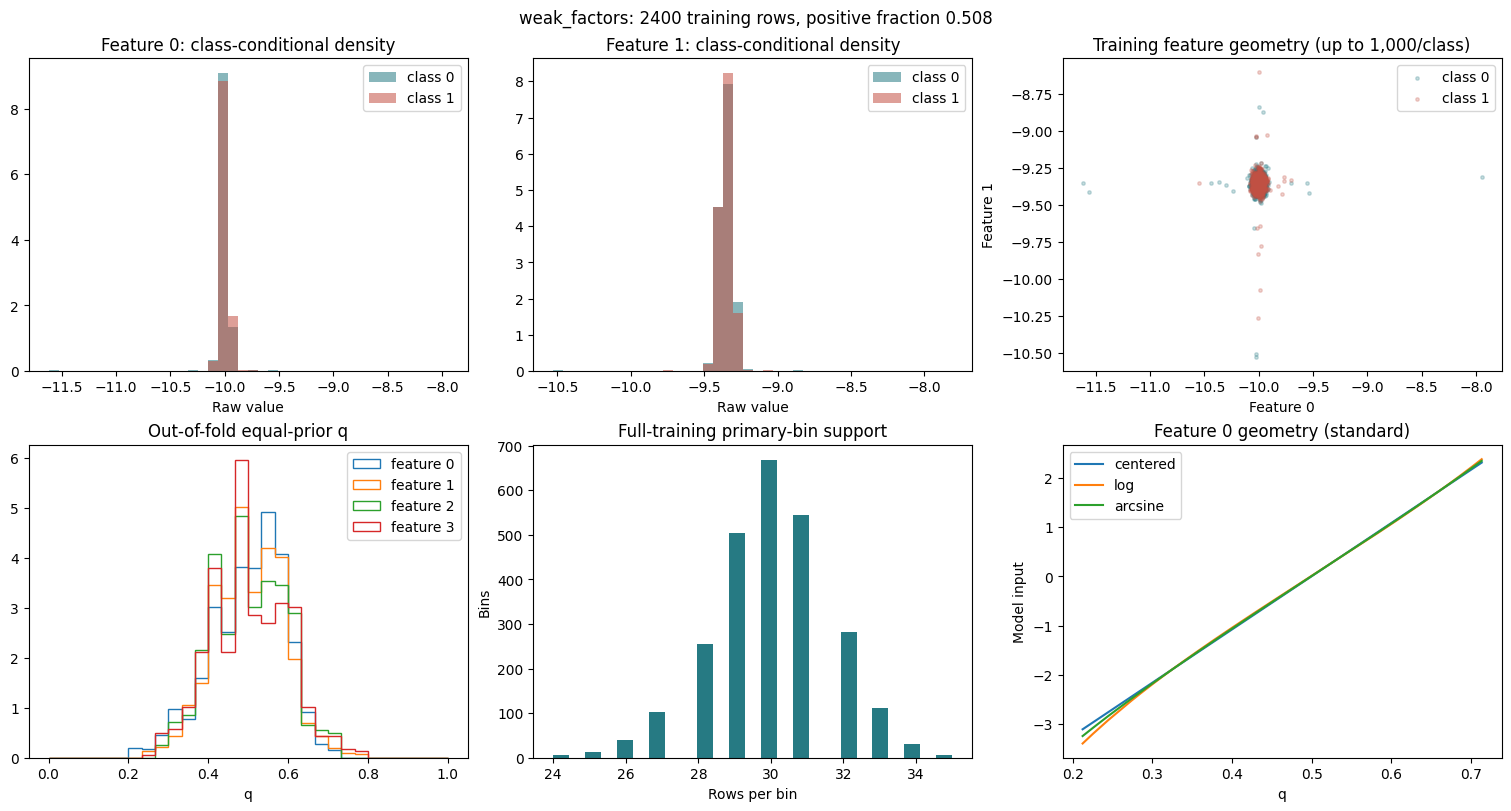

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.2122, 0.2443, 0.5124, 0.6751, 0.7138] 0.0000 0.99946 0.4909485273687135
1 [0.2443, 0.2979, 0.4923, 0.7212, 0.7866] 0.0000 0.99950 0.48838149485968324
2 [0.2854, 0.3012, 0.4923, 0.7138, 0.7138] 0.0000 0.99980 0.5125156293414838
3 [0.2443, 0.2739, 0.4923, 0.725, 0.7724] 0.0000 0.99954 0.49359579049736035
4 [0.2854, 0.3134, 0.4923, 0.702, 0.8029] 0.0000 0.99945 0.5024364406779661
5 [0.2443, 0.2979, 0.5124, 0.702, 0.7442] 0.0000 0.99971 0.4911777577104751
6 [0.2033, 0.2852, 0.5109, 0.6891, 0.7212] 0.0000 0.99949 0.5011339955543207
7 [0.2534, 0.3264, 0.4923, 0.7332, 0.7563] 0.0000 0.99963 0.4831154487357599
8 [0.2345, 0.2739, 0.4923, 0.702, 0.7951] 0.0000 0.99947 0.5056866490691858
9 [0.217, 0.255, 0.4923, 0.714, 0.7951] 0.0000 0.99934 0.4926160044456794
10 [0.2633, 0.29, 0.4923, 0.7544, 0.8136] 0.0000 0.99939 0.5192741039177549
11 [0.1559, 0.255, 0.5109, 0.7442, 0.829] 0.0000 0.99827 0.484

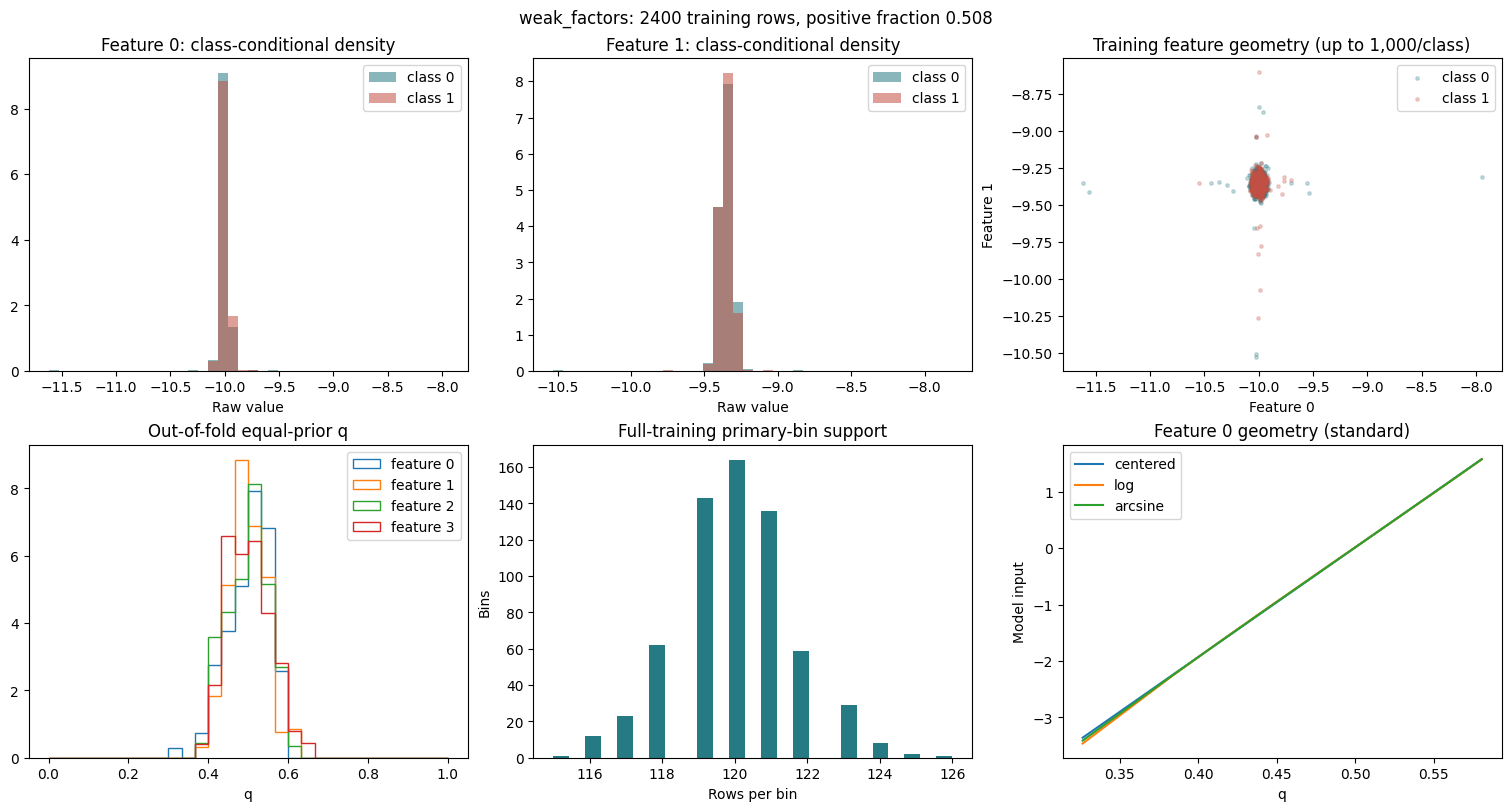

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3263, 0.3836, 0.503, 0.5806, 0.5806] 0.0000 0.99993 0.513238399555432
1 [0.3745, 0.3745, 0.4972, 0.6098, 0.6098] 0.0000 0.99998 0.505501875520978
2 [0.3967, 0.3967, 0.503, 0.6253, 0.6253] 0.0000 0.99999 0.5042216587941095
3 [0.3923, 0.3923, 0.4972, 0.6438, 0.6438] 0.0000 0.99997 0.4945255626562934
4 [0.4033, 0.4033, 0.4973, 0.6404, 0.6404] 0.0000 0.99997 0.486785565434843
5 [0.3813, 0.3813, 0.5085, 0.5787, 0.5806] 0.0000 0.99999 0.4830671714365101
6 [0.3813, 0.3836, 0.4917, 0.6283, 0.6283] 0.0000 0.99998 0.5183446790775216
7 [0.4097, 0.4143, 0.4973, 0.6005, 0.6005] 0.0000 0.99999 0.4702632675743262
8 [0.4143, 0.4173, 0.497, 0.6029, 0.6029] 0.0000 0.99999 0.4907300639066407
9 [0.4143, 0.4143, 0.5028, 0.6047, 0.6047] 0.0000 0.99999 0.49586030841900536
10 [0.3832, 0.3832, 0.4917, 0.6324, 0.6324] 0.0000 0.99997 0.5031724090025007
11 [0.3745, 0.4075, 0.4972, 0.6211, 0.6211] 0.0000 0.99998 0

In [15]:
RAW_ENCODER = replace(WEAK_ENCODER, mode="raw_fixed")
raw_clean = run_case("weak_raw_clean", WEAK_CONFIG, RAW_ENCODER)
raw_contaminated = run_case("weak_raw_contaminated", CONTAMINATED_CONFIG, RAW_ENCODER)
fine_bins = run_case("weak_fine_bins", CONTAMINATED_CONFIG, replace(WEAK_ENCODER, num_bins=80))
low_smoothing = run_case("weak_low_smoothing", CONTAMINATED_CONFIG, replace(WEAK_ENCODER, alpha=0.1))

### 6.9. Temporal Controls: Stable, Covariate and Concept Shift

Generate four persistent Gaussian factors and weak, noisy indicators of them. The target is sampled from sigmoid(1.2 * mean future factor signal + 3 * future hidden innovation + intercept), using the next five observations. Hidden innovations are summed and normalized by sqrt(5); factor signals are averaged over the horizon. Labels therefore overlap in their future drivers and become available only after five steps.

Chronological 60/20/20 boundaries replace stratified splitting. The first 20% of the full path is encoder warm-up and is not used as downstream model-training rows. Five rows are purged before each split boundary so training and checkpoint-selection outcomes are available before the next period. Training encodings always come from earlier historical blocks. These controls freeze a trailing 1,000-row reference encoder before validation, for both validation and test.

The stable control has no shift. Covariate-only shift changes observed feature location/scale at 65% and 85% of the path but preserves paired labels. Concept-only shift reverses the factor/outcome relationship between those points while preserving the observed feature path. The training period precedes both changes. Shape and temporal plots accompany each condition.

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 24, 'scenario': 'temporal_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 16, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.2, 'encoding_block_size': 200, 'history_window': 1000, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 'f

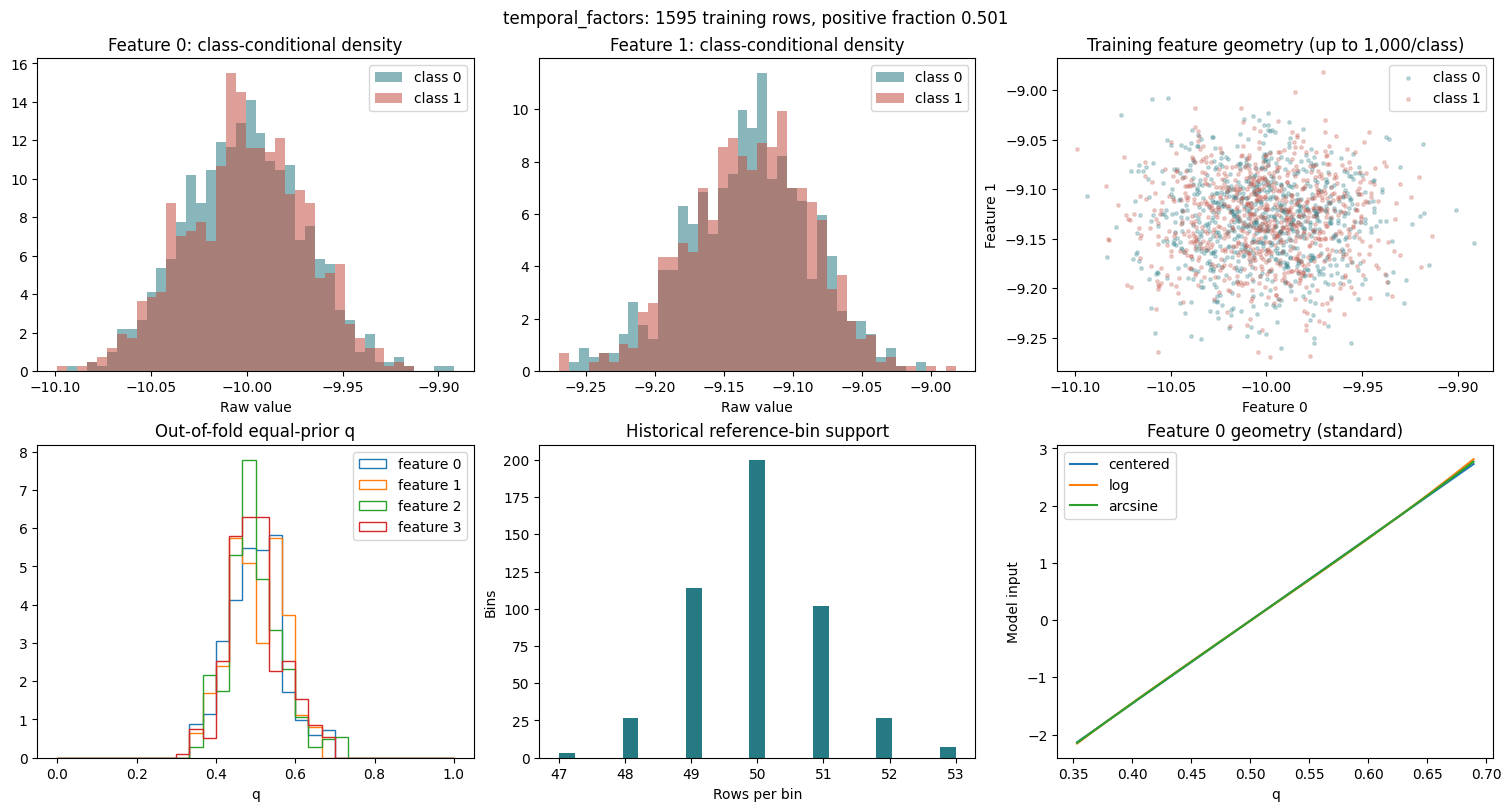

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3532, 0.356, 0.5038, 0.6754, 0.6892] 0.0000 0.99990 0.48816909956541155
1 [0.3414, 0.3472, 0.4955, 0.6427, 0.66] 0.0000 0.99995 0.5144889025855184
2 [0.3577, 0.3682, 0.4894, 0.7255, 0.7255] 0.0000 0.99973 0.5050612889227112
3 [0.3275, 0.3509, 0.4902, 0.6798, 0.6953] 0.0000 0.99990 0.506305777951082
4 [0.3752, 0.3832, 0.4994, 0.6382, 0.6899] 0.0000 0.99993 0.4791785900717605
5 [0.3105, 0.326, 0.4979, 0.6777, 0.7307] 0.0000 0.99983 0.486424613681675
6 [0.3402, 0.3451, 0.4985, 0.6231, 0.6427] 0.0000 0.99995 0.4981808290513896
7 [0.36, 0.3657, 0.4985, 0.6346, 0.6427] 0.0000 0.99996 0.49941981496971716
8 [0.3499, 0.3589, 0.4957, 0.6633, 0.6633] 0.0000 0.99995 0.4930542889667361
9 [0.3012, 0.3225, 0.5077, 0.6293, 0.631] 0.0000 0.99988 0.4883074634750724
10 [0.3181, 0.3647, 0.4957, 0.6677, 0.6754] 0.0000 0.99991 0.5103898717618127
11 [0.3414, 0.3439, 0.4994, 0.616, 0.6191] 0.0000 0.99995 0.49

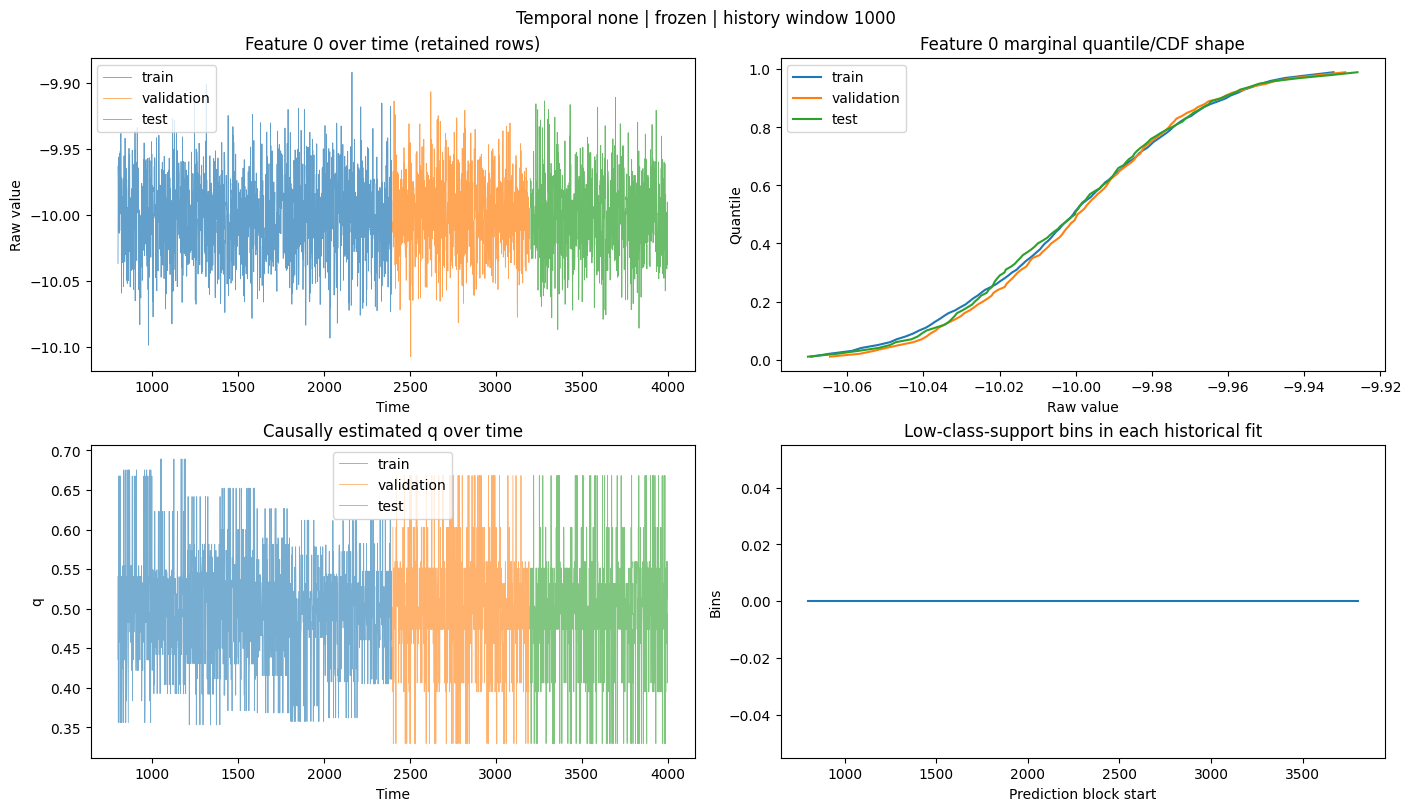


time_stable | seed=42 | scaling=none
Constant historical-prior test loss: 0.693661
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered      3   0.693134   0.693775   +0.000000  0.250310  0.509137  0.521250         n/a     0
mlp       centered     16   0.692832   0.693324   +0.000000  0.250088  0.506705  0.513750         n/a     0
tree      centered      -   0.730380   0.710780   +0.000000  0.255259  0.545076  0.532500         n/a     0
logistic  log           3   0.695239   0.696573   +0.002799  0.251688  0.504314  0.496250         n/a     0
mlp       log          14   0.693384   0.694178   +0.000854  0.250515  0.498478  0.502500         n/a     0
tree      log           -   0.730380   0.710780   +0.000000  0.255259  0.545076  0.532500         n/a     0
logistic  arcsine       3   0.692305   0.693146   -0.000628  0.249999  0.509662  0.498750         n/a     0
mlp       arcsine      16   0.692738   0.693012   -0

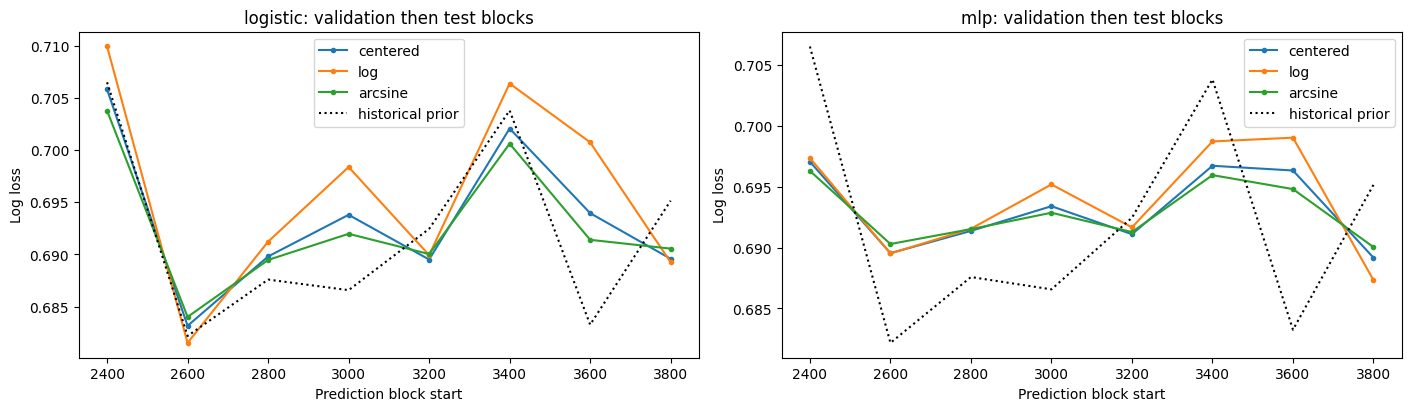


time_stable | seed=42 | scaling=standard
Constant historical-prior test loss: 0.693661
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     27   0.694455   0.697425   +0.000000  0.252105  0.511300  0.501250         n/a     0
mlp       centered      9   0.695976   0.698746   +0.000000  0.252784  0.484980  0.487500         n/a     0
tree      centered      -   0.730380   0.710780   +0.000000  0.255259  0.545076  0.532500         n/a     0
logistic  log          27   0.694402   0.697481   +0.000056  0.252134  0.510944  0.500000         n/a     0
mlp       log           9   0.695946   0.698727   -0.000019  0.252775  0.484442  0.486250         n/a     0
tree      log           -   0.730380   0.710780   +0.000000  0.255259  0.545076  0.532500         n/a     0
logistic  arcsine      27   0.694429   0.697453   +0.000028  0.252119  0.511282  0.502500         n/a     0
mlp       arcsine       9   0.695954   0.698757 

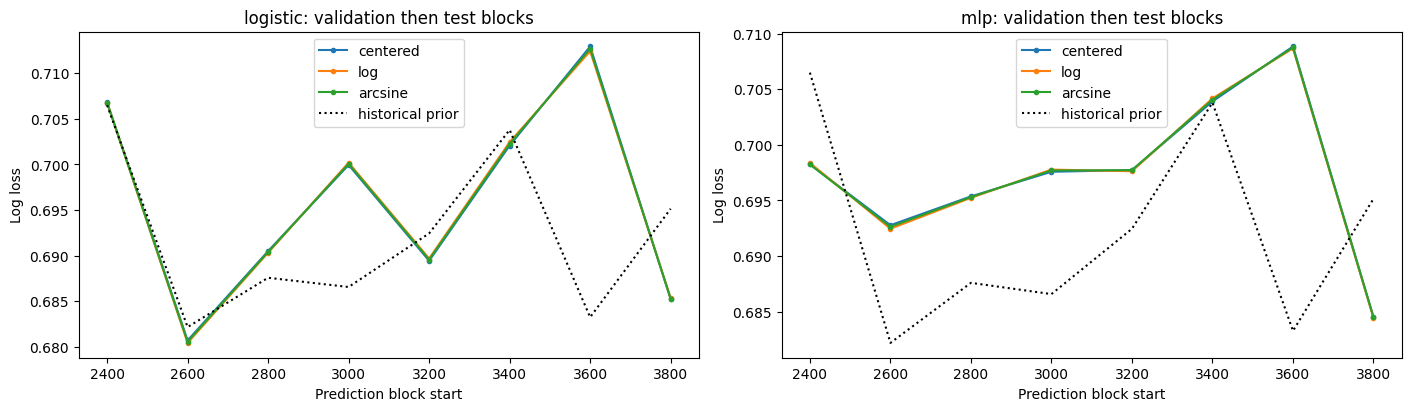

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 24, 'scenario': 'temporal_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 16, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'covariate', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.2, 'encoding_block_size': 200, 'history_window': 1000, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode

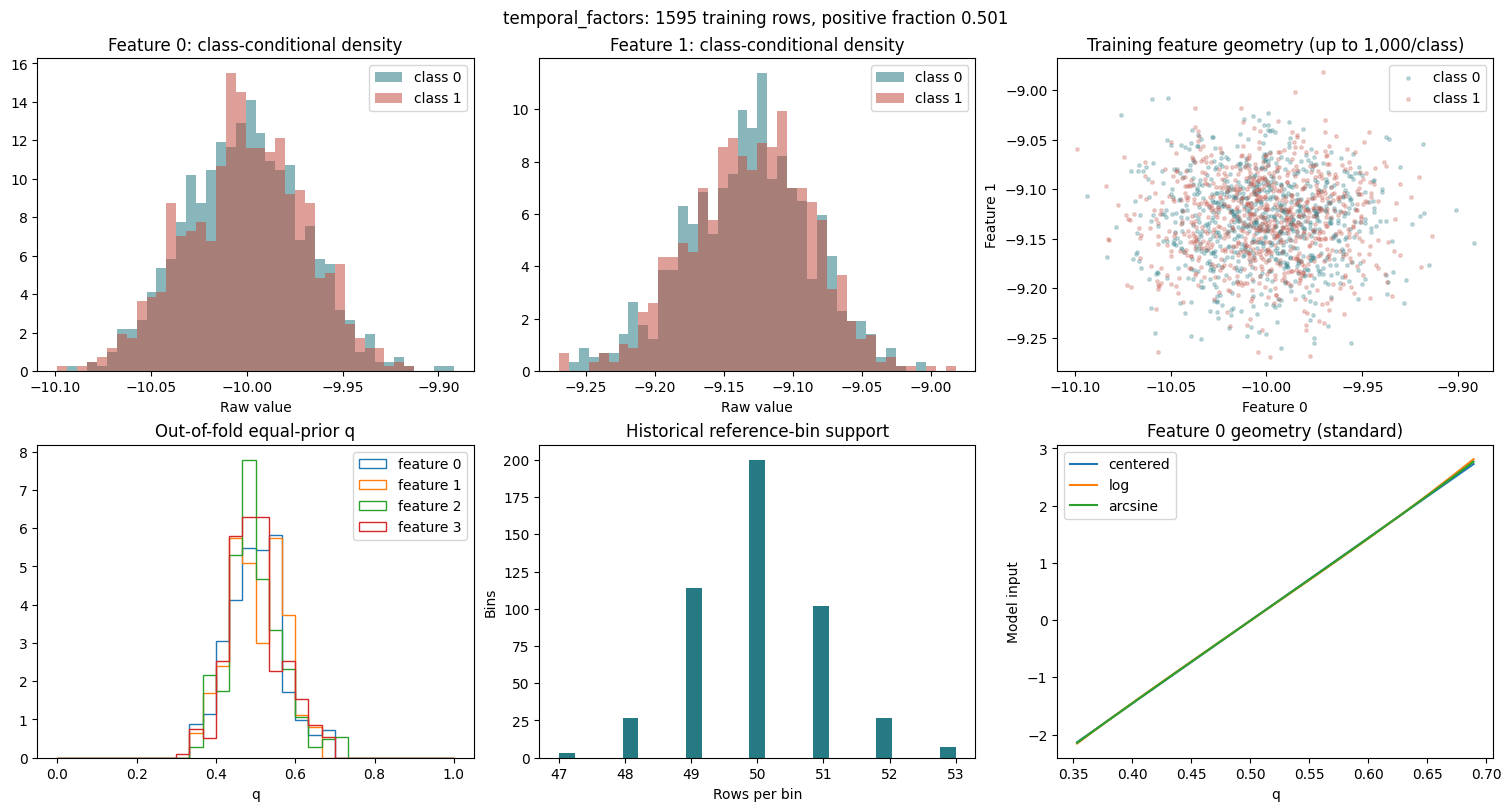

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3532, 0.356, 0.5038, 0.6754, 0.6892] 0.0000 0.99990 0.48816909956541155
1 [0.3414, 0.3472, 0.4955, 0.6427, 0.66] 0.0000 0.99995 0.5144889025855184
2 [0.3577, 0.3682, 0.4894, 0.7255, 0.7255] 0.0000 0.99973 0.5050612889227112
3 [0.3275, 0.3509, 0.4902, 0.6798, 0.6953] 0.0000 0.99990 0.506305777951082
4 [0.3752, 0.3832, 0.4994, 0.6382, 0.6899] 0.0000 0.99993 0.4791785900717605
5 [0.3105, 0.326, 0.4979, 0.6777, 0.7307] 0.0000 0.99983 0.486424613681675
6 [0.3402, 0.3451, 0.4985, 0.6231, 0.6427] 0.0000 0.99995 0.4981808290513896
7 [0.36, 0.3657, 0.4985, 0.6346, 0.6427] 0.0000 0.99996 0.49941981496971716
8 [0.3499, 0.3589, 0.4957, 0.6633, 0.6633] 0.0000 0.99995 0.4930542889667361
9 [0.3012, 0.3225, 0.5077, 0.6293, 0.631] 0.0000 0.99988 0.4883074634750724
10 [0.3181, 0.3647, 0.4957, 0.6677, 0.6754] 0.0000 0.99991 0.5103898717618127
11 [0.3414, 0.3439, 0.4994, 0.616, 0.6191] 0.0000 0.99995 0.49

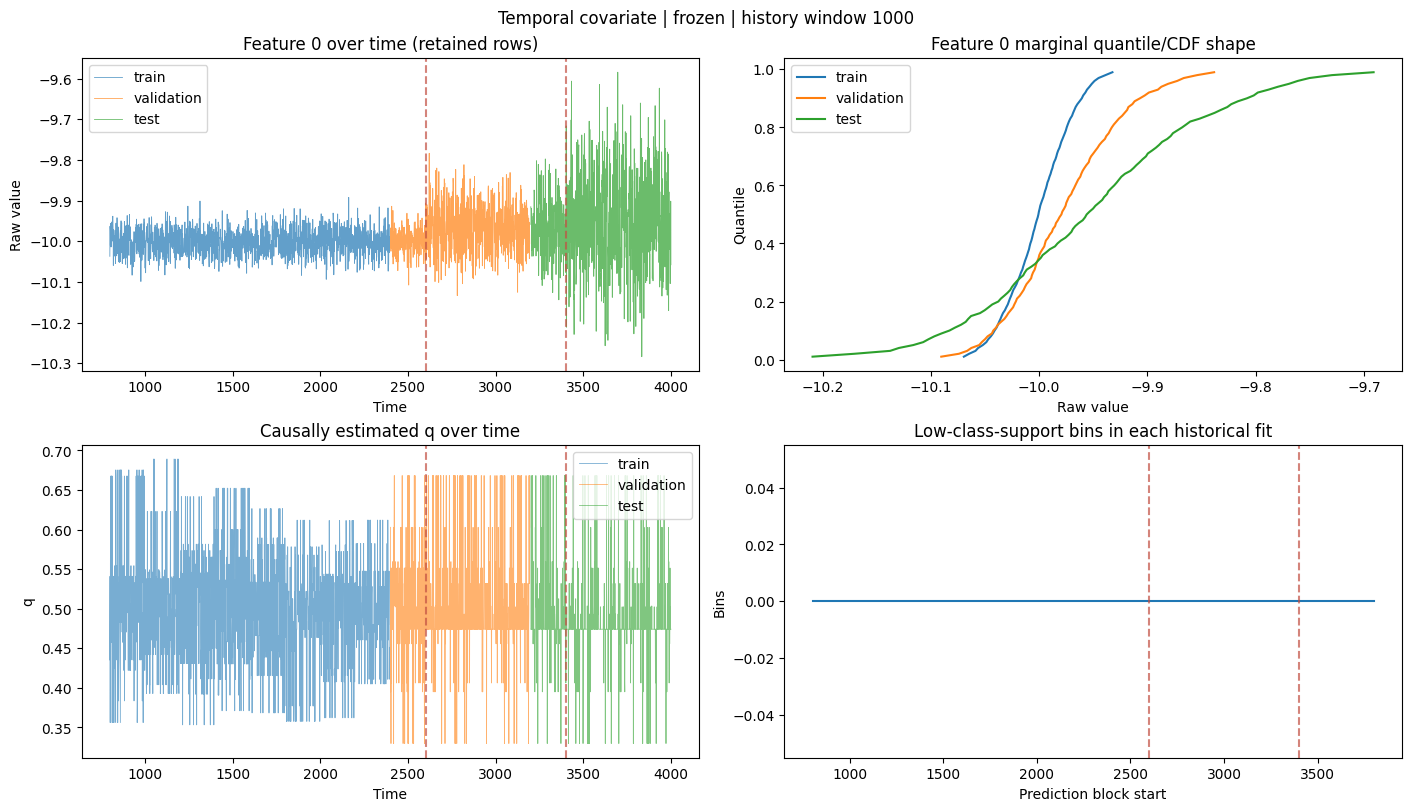


time_covariate | seed=42 | scaling=none
Constant historical-prior test loss: 0.693661
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered      2   0.693736   0.694586   +0.000000  0.250717  0.483404  0.512500         n/a     0
mlp       centered     14   0.693582   0.693627   +0.000000  0.250240  0.490450  0.490000         n/a     0
tree      centered      -   0.727183   0.709265   +0.000000  0.256802  0.474345  0.497500         n/a     0
logistic  log           1   0.695931   0.695390   +0.000803  0.251117  0.483967  0.496250         n/a     0
mlp       log           9   0.695121   0.694292   +0.000664  0.250572  0.485786  0.472500         n/a     0
tree      log           -   0.727183   0.709265   +0.000000  0.256802  0.474345  0.497500         n/a     0
logistic  arcsine       3   0.692960   0.694461   -0.000125  0.250655  0.481854  0.498750         n/a     0
mlp       arcsine      14   0.693316   0.693390  

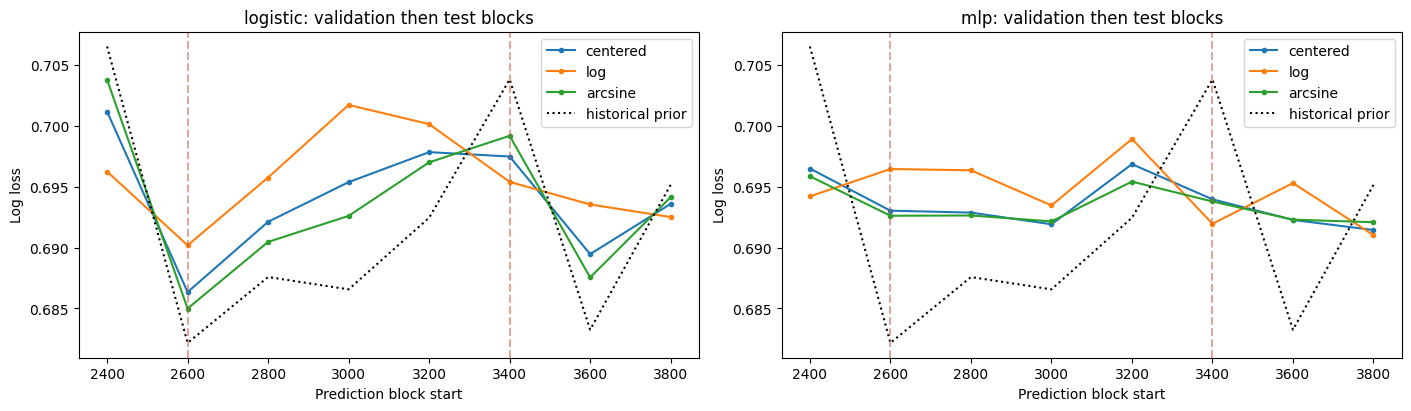


time_covariate | seed=42 | scaling=standard
Constant historical-prior test loss: 0.693661
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     14   0.700442   0.696255   +0.000000  0.251530  0.501872  0.506250         n/a     0
mlp       centered      4   0.699607   0.696002   +0.000000  0.251421  0.499603  0.490000         n/a     0
tree      centered      -   0.727183   0.709265   +0.000000  0.256802  0.474345  0.497500         n/a     0
logistic  log          14   0.700291   0.696235   -0.000020  0.251520  0.501860  0.508750         n/a     0
mlp       log           4   0.699603   0.696005   +0.000003  0.251423  0.499334  0.486250         n/a     0
tree      log           -   0.727183   0.709265   +0.000000  0.256802  0.474345  0.497500         n/a     0
logistic  arcsine      14   0.700369   0.696245   -0.000011  0.251525  0.502079  0.506250         n/a     0
mlp       arcsine       4   0.699596   0.6960

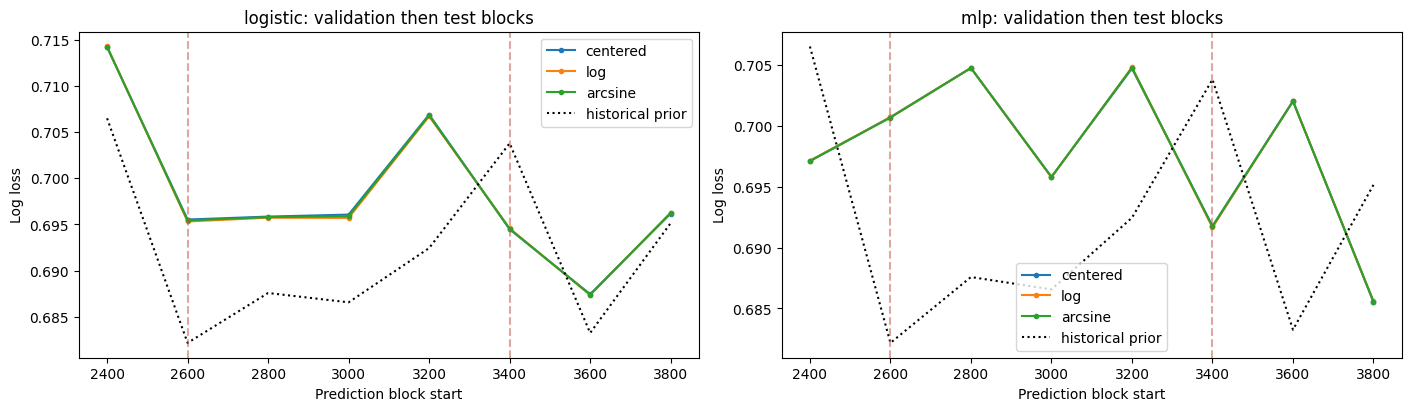

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 24, 'scenario': 'temporal_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 16, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'concept', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.2, 'encoding_block_size': 200, 'history_window': 1000, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode':

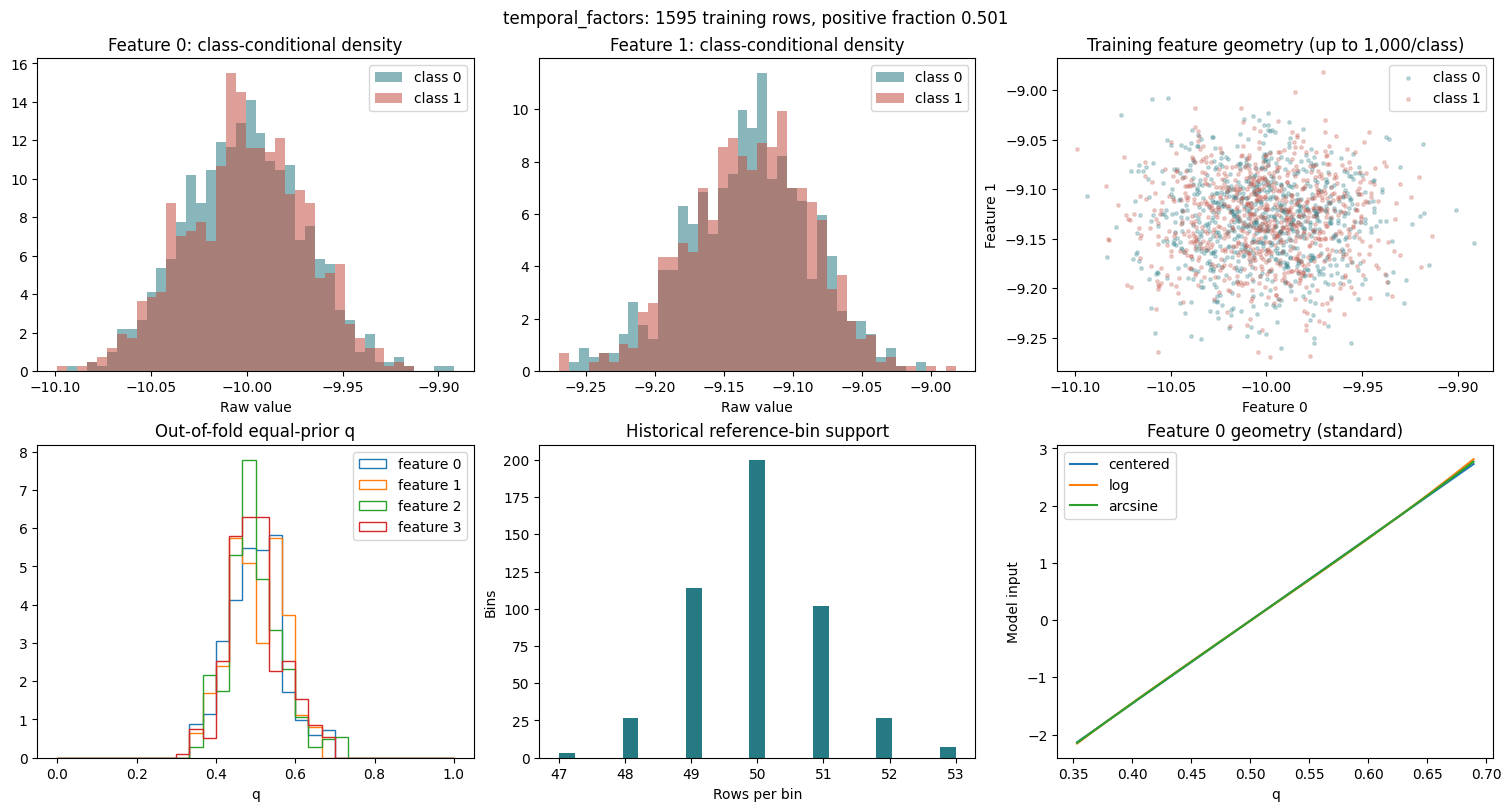

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3532, 0.356, 0.5038, 0.6754, 0.6892] 0.0000 0.99990 0.48816909956541155
1 [0.3414, 0.3472, 0.4955, 0.6427, 0.66] 0.0000 0.99995 0.5144889025855184
2 [0.3577, 0.3682, 0.4894, 0.7255, 0.7255] 0.0000 0.99973 0.5050612889227112
3 [0.3275, 0.3509, 0.4902, 0.6798, 0.6953] 0.0000 0.99990 0.506305777951082
4 [0.3752, 0.3832, 0.4994, 0.6382, 0.6899] 0.0000 0.99993 0.4791785900717605
5 [0.3105, 0.326, 0.4979, 0.6777, 0.7307] 0.0000 0.99983 0.486424613681675
6 [0.3402, 0.3451, 0.4985, 0.6231, 0.6427] 0.0000 0.99995 0.4981808290513896
7 [0.36, 0.3657, 0.4985, 0.6346, 0.6427] 0.0000 0.99996 0.49941981496971716
8 [0.3499, 0.3589, 0.4957, 0.6633, 0.6633] 0.0000 0.99995 0.4930542889667361
9 [0.3012, 0.3225, 0.5077, 0.6293, 0.631] 0.0000 0.99988 0.4883074634750724
10 [0.3181, 0.3647, 0.4957, 0.6677, 0.6754] 0.0000 0.99991 0.5103898717618127
11 [0.3414, 0.3439, 0.4994, 0.616, 0.6191] 0.0000 0.99995 0.49

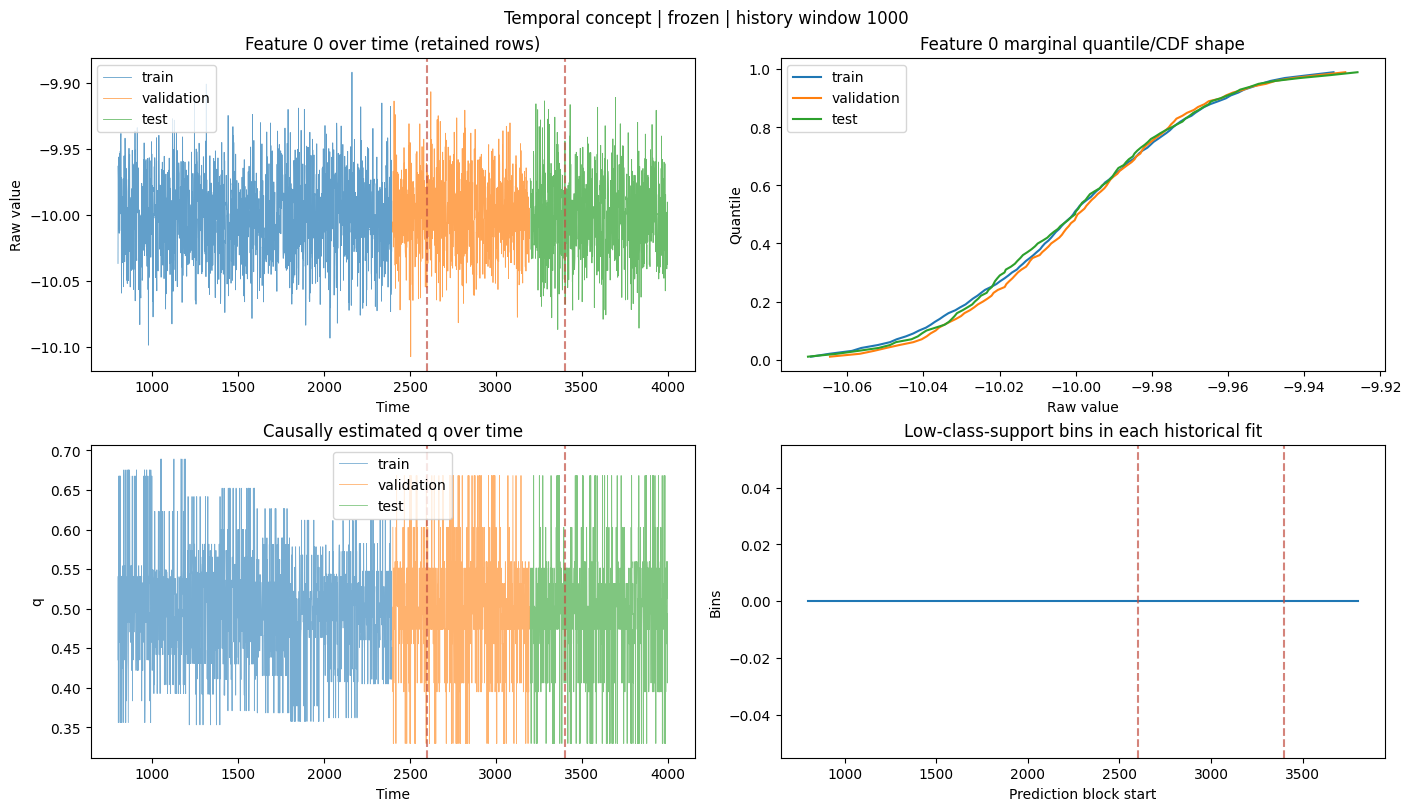


time_concept | seed=42 | scaling=none
Constant historical-prior test loss: 0.692580
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered      4   0.694698   0.694493   +0.000000  0.250669  0.500222  0.511250         n/a     0
mlp       centered     11   0.693100   0.693793   +0.000000  0.250323  0.494896  0.503750         n/a     0
tree      centered      -   0.736204   0.726895   +0.000000  0.261370  0.524494  0.525000         n/a     0
logistic  log           3   0.696400   0.696710   +0.002217  0.251762  0.499449  0.498750         n/a     0
mlp       log           7   0.693066   0.694920   +0.001126  0.250885  0.485821  0.488750         n/a     0
tree      log           -   0.736204   0.726895   +0.000000  0.261370  0.524494  0.525000         n/a     0
logistic  arcsine       4   0.693910   0.693386   -0.001106  0.250119  0.500748  0.511250         n/a     0
mlp       arcsine      16   0.693066   0.693123   -

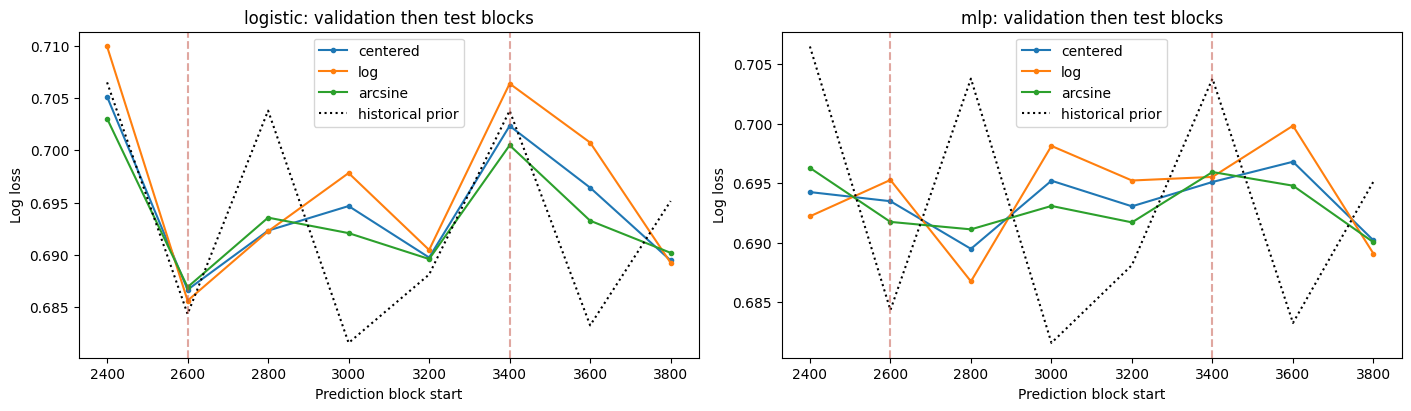


time_concept | seed=42 | scaling=standard
Constant historical-prior test loss: 0.692580
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     33   0.694726   0.703358   +0.000000  0.255020  0.484988  0.486250         n/a     0
mlp       centered      5   0.694960   0.699126   +0.000000  0.252974  0.479599  0.480000         n/a     0
tree      centered      -   0.736204   0.726895   +0.000000  0.261370  0.524494  0.525000         n/a     0
logistic  log          33   0.694599   0.703358   -0.000000  0.255020  0.484951  0.486250         n/a     0
mlp       log           5   0.694921   0.699117   -0.000009  0.252970  0.479193  0.475000         n/a     0
tree      log           -   0.736204   0.726895   +0.000000  0.261370  0.524494  0.525000         n/a     0
logistic  arcsine      33   0.694663   0.703359   +0.000000  0.255020  0.484941  0.487500         n/a     0
mlp       arcsine       5   0.694938   0.699123

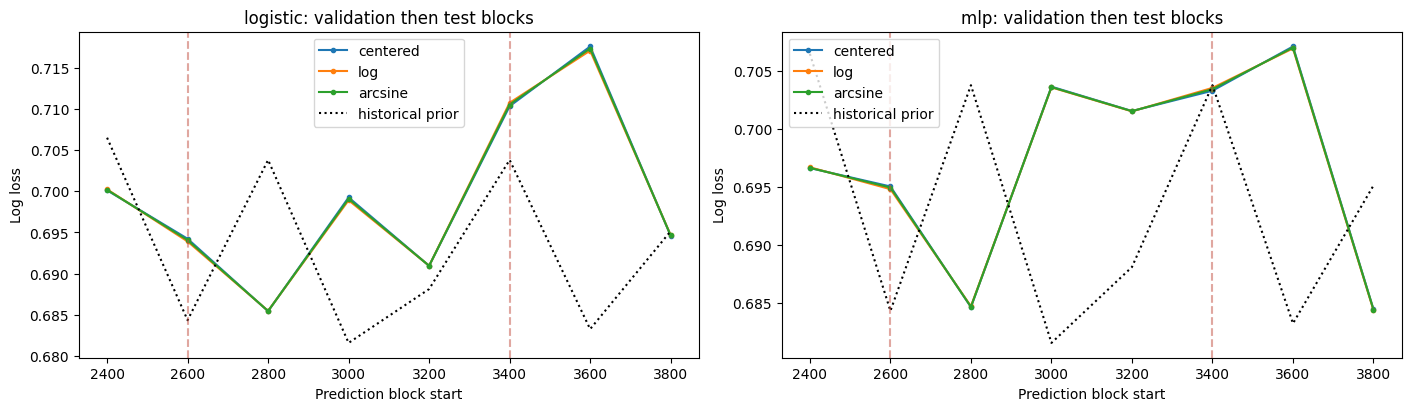

In [16]:
TIME_CONFIG = replace(WEAK_CONFIG, scenario="temporal_factors", n_features=24, n_informative=16,
                      factor_persistence=0.8, forecast_horizon=5, warmup_fraction=0.2,
                      encoding_block_size=200, history_window=1000, temporal_update="frozen",
                      shift_fraction=0.65, recovery_fraction=0.85, drift_location=3.0, drift_scale=2.0)
time_stable = run_case("time_stable", TIME_CONFIG, WEAK_ENCODER)
time_covariate = run_case("time_covariate", replace(TIME_CONFIG, drift="covariate"), WEAK_ENCODER)
time_concept = run_case("time_concept", replace(TIME_CONFIG, drift="concept"), WEAK_ENCODER)

### 6.10. Combined Shift: Frozen, Rolling and Expanding Evidence

Combine the weak temporal task, covariate drift, concept reversal and 1% independent heavy-tail contamination. Compare three policies on the identical generated path: a frozen 1,000-row historical fit; causal updates using a rolling 1,000-row window; and causal updates using all available history. Prediction blocks contain 200 rows. Each encoder stays fixed inside a block and only uses labels with row + horizon < block start.

Causal updates may use earlier validation/test labels after their outcome windows finish. Frozen fits never use those labels. Downstream model weights and training-derived scaling remain fixed in every policy; this isolates encoder adaptation, not full model retraining. The sign reverses at 65% of the path and returns at 85%; feature location/scale shift at both boundaries. This is a synthetic forward-outcome stress, not a price simulator or a universal reversal rule.

Plots show historical-CDF mismatch, estimated q and low-support bins over time. Loss traces compare all representations against a constant prior estimated before validation. Drift locations are diagnostic metadata only; learners do not receive regime identifiers or future change points.

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 24, 'scenario': 'temporal_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 16, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.01, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'combined', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.2, 'encoding_block_size': 200, 'history_window': 1000, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode

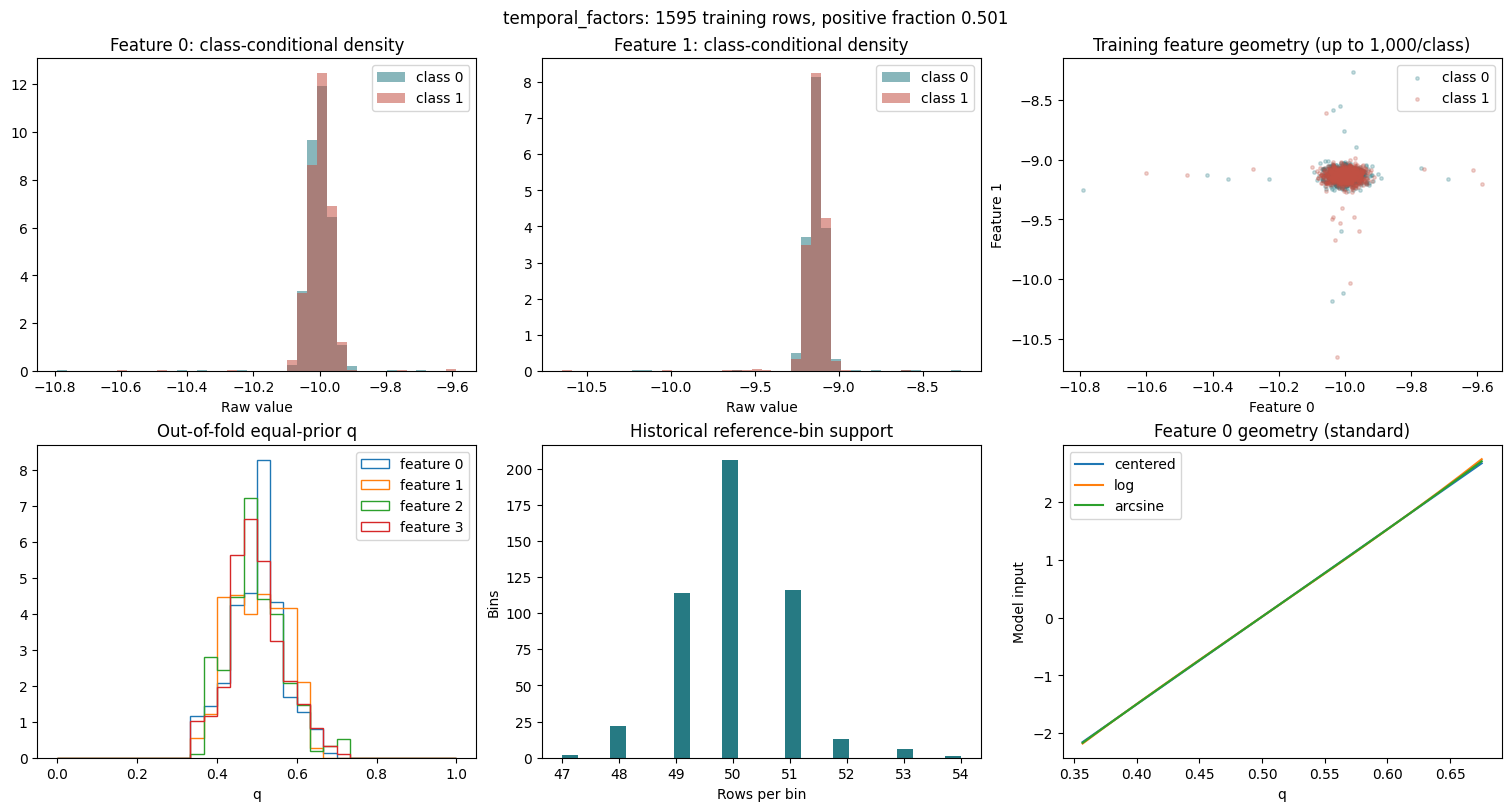

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3568, 0.3576, 0.5077, 0.659, 0.6752] 0.0000 0.99994 0.48741989044094064
1 [0.3647, 0.3656, 0.5038, 0.631, 0.6535] 0.0000 0.99997 0.5076909893648467
2 [0.3466, 0.3709, 0.4948, 0.7096, 0.7255] 0.0000 0.99974 0.5064763743624254
3 [0.3368, 0.346, 0.4933, 0.6715, 0.7011] 0.0000 0.99990 0.5093576455493991
4 [0.3568, 0.3739, 0.4996, 0.6263, 0.6267] 0.0000 0.99998 0.48178234728083474
5 [0.3022, 0.3284, 0.4996, 0.6864, 0.7431] 0.0000 0.99976 0.4826864296450966
6 [0.3466, 0.3491, 0.4985, 0.6544, 0.6566] 0.0000 0.99994 0.5022586335934994
7 [0.3181, 0.36, 0.4986, 0.6288, 0.6331] 0.0000 0.99995 0.4910173520921252
8 [0.3647, 0.3752, 0.4944, 0.718, 0.718] 0.0000 0.99978 0.4943506644612297
9 [0.2862, 0.3353, 0.5065, 0.6379, 0.6382] 0.0000 0.99989 0.4927382532185332
10 [0.3414, 0.3507, 0.4986, 0.6554, 0.6596] 0.0000 0.99994 0.5144228652649984
11 [0.3197, 0.3551, 0.4948, 0.6424, 0.6511] 0.0000 0.99994 0

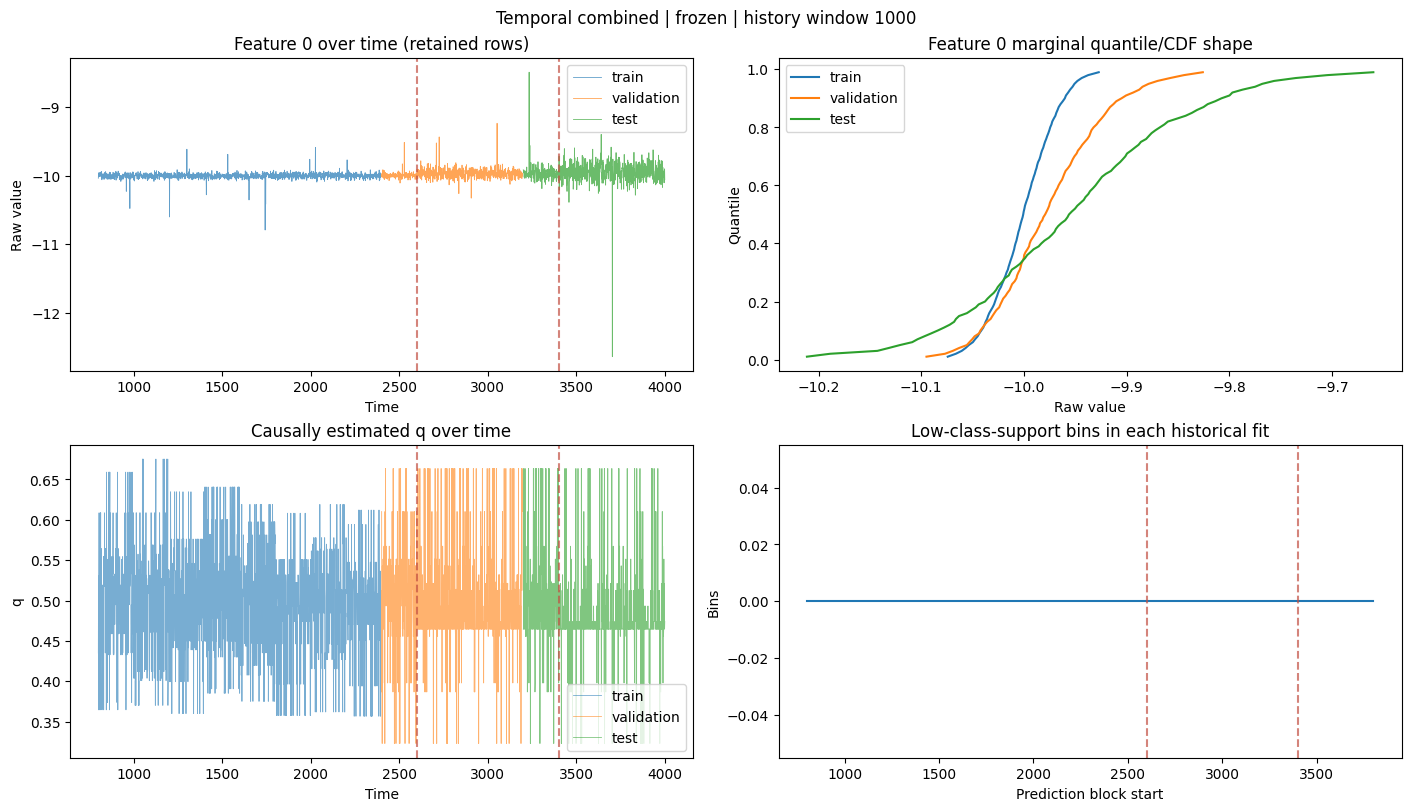


shift_frozen | seed=42 | scaling=none
Constant historical-prior test loss: 0.692580
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered      1   0.693721   0.693880   +0.000000  0.250366  0.486684  0.486250         n/a     0
mlp       centered      9   0.692727   0.693479   +0.000000  0.250166  0.493910  0.491250         n/a     0
tree      centered      -   0.739360   0.769358   +0.000000  0.280562  0.486422  0.510000         n/a     0
logistic  log           1   0.694700   0.694985   +0.001105  0.250916  0.484253  0.495000         n/a     0
mlp       log           9   0.692751   0.694130   +0.000651  0.250491  0.490058  0.491250         n/a     0
tree      log           -   0.739360   0.769358   +0.000000  0.280562  0.486422  0.510000         n/a     0
logistic  arcsine       2   0.693482   0.693301   -0.000578  0.250077  0.484118  0.520000         n/a     0
mlp       arcsine       9   0.692901   0.693330   -

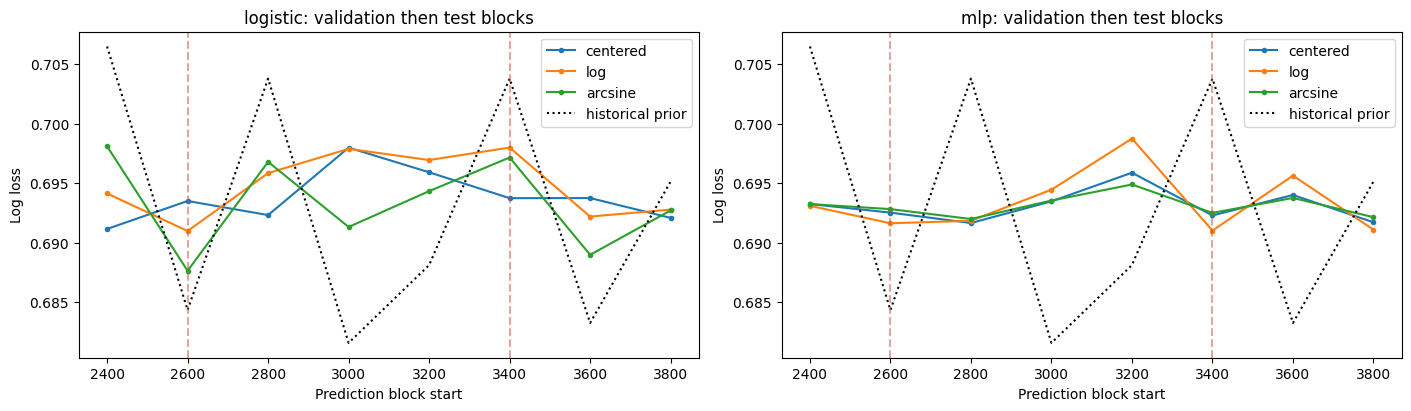


shift_frozen | seed=42 | scaling=standard
Constant historical-prior test loss: 0.692580
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     12   0.697516   0.700282   +0.000000  0.253539  0.468584  0.495000         n/a     0
mlp       centered      5   0.693270   0.696872   +0.000000  0.251853  0.494477  0.488750         n/a     0
tree      centered      -   0.739360   0.769358   +0.000000  0.280562  0.486422  0.510000         n/a     0
logistic  log          12   0.697356   0.700264   -0.000017  0.253532  0.468102  0.490000         n/a     0
mlp       log           5   0.693202   0.696802   -0.000070  0.251819  0.494126  0.492500         n/a     0
tree      log           -   0.739360   0.769358   +0.000000  0.280562  0.486422  0.510000         n/a     0
logistic  arcsine      12   0.697437   0.700273   -0.000009  0.253536  0.468571  0.493750         n/a     0
mlp       arcsine       5   0.693219   0.696835

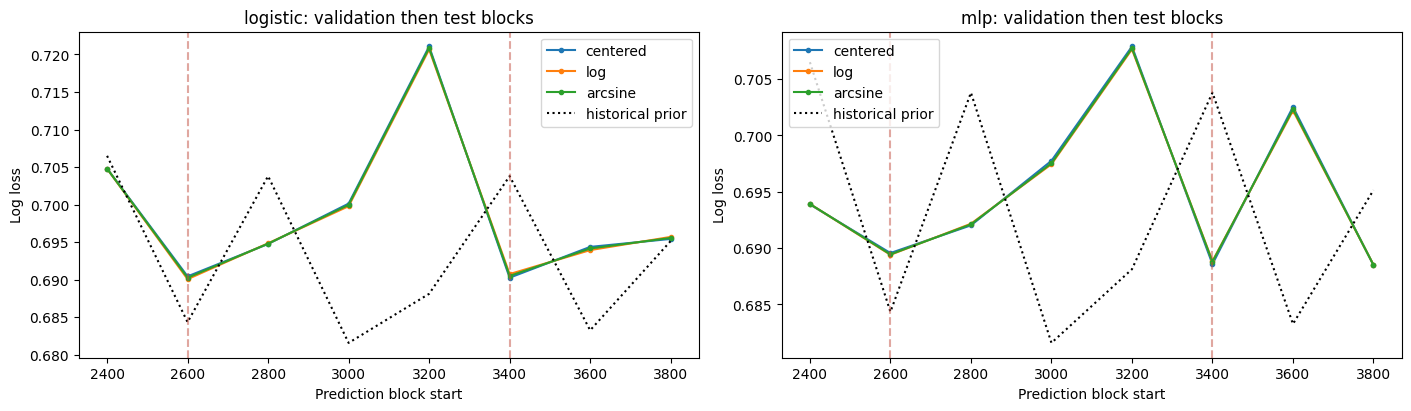

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 24, 'scenario': 'temporal_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 16, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.01, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'combined', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.2, 'encoding_block_size': 200, 'history_window': 1000, 'temporal_update': 'causal', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode

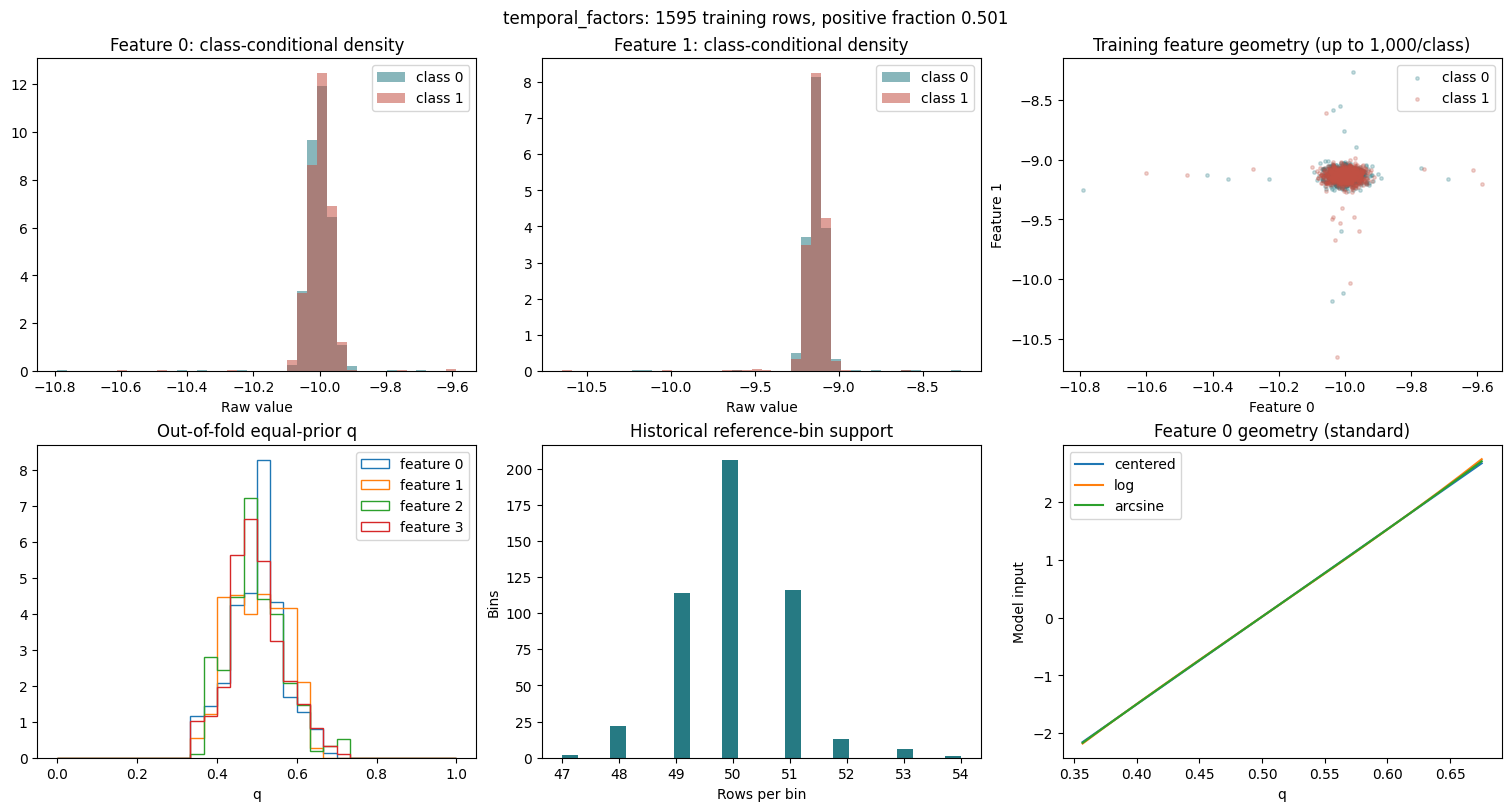

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3568, 0.3576, 0.5077, 0.659, 0.6752] 0.0000 0.99994 0.48741989044094064
1 [0.3647, 0.3656, 0.5038, 0.631, 0.6535] 0.0000 0.99997 0.5076909893648467
2 [0.3466, 0.3709, 0.4948, 0.7096, 0.7255] 0.0000 0.99974 0.5064763743624254
3 [0.3368, 0.346, 0.4933, 0.6715, 0.7011] 0.0000 0.99990 0.5093576455493991
4 [0.3568, 0.3739, 0.4996, 0.6263, 0.6267] 0.0000 0.99998 0.48178234728083474
5 [0.3022, 0.3284, 0.4996, 0.6864, 0.7431] 0.0000 0.99976 0.4826864296450966
6 [0.3466, 0.3491, 0.4985, 0.6544, 0.6566] 0.0000 0.99994 0.5022586335934994
7 [0.3181, 0.36, 0.4986, 0.6288, 0.6331] 0.0000 0.99995 0.4910173520921252
8 [0.3647, 0.3752, 0.4944, 0.718, 0.718] 0.0000 0.99978 0.4943506644612297
9 [0.2862, 0.3353, 0.5065, 0.6379, 0.6382] 0.0000 0.99989 0.4927382532185332
10 [0.3414, 0.3507, 0.4986, 0.6554, 0.6596] 0.0000 0.99994 0.5144228652649984
11 [0.3197, 0.3551, 0.4948, 0.6424, 0.6511] 0.0000 0.99994 0

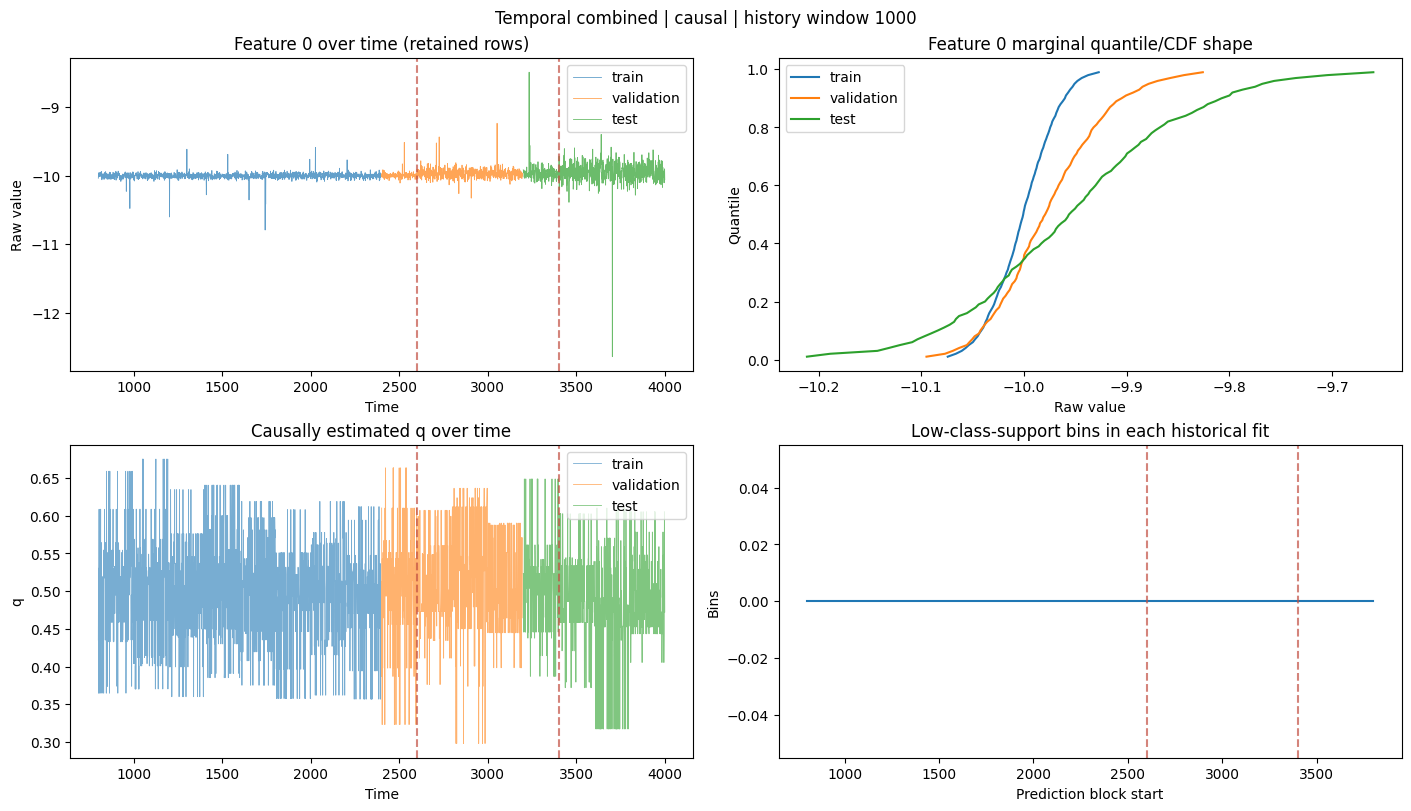


shift_causal_rolling | seed=42 | scaling=none
Constant historical-prior test loss: 0.692580
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered      1   0.696614   0.695315   +0.000000  0.251080  0.500072  0.497500         n/a     0
mlp       centered      8   0.694200   0.692215   +0.000000  0.249534  0.539728  0.528750         n/a     0
tree      centered      -   0.789015   0.797245   +0.000000  0.289131  0.463126  0.511250         n/a     0
logistic  log           1   0.699733   0.696712   +0.001397  0.251769  0.499521  0.507500         n/a     0
mlp       log           5   0.695536   0.692017   -0.000198  0.249434  0.537678  0.532500         n/a     0
tree      log           -   0.789015   0.797245   +0.000000  0.289131  0.463126  0.511250         n/a     0
logistic  arcsine       1   0.695433   0.694918   -0.000397  0.250883  0.500138  0.503750         n/a     0
mlp       arcsine       9   0.693810   0.69

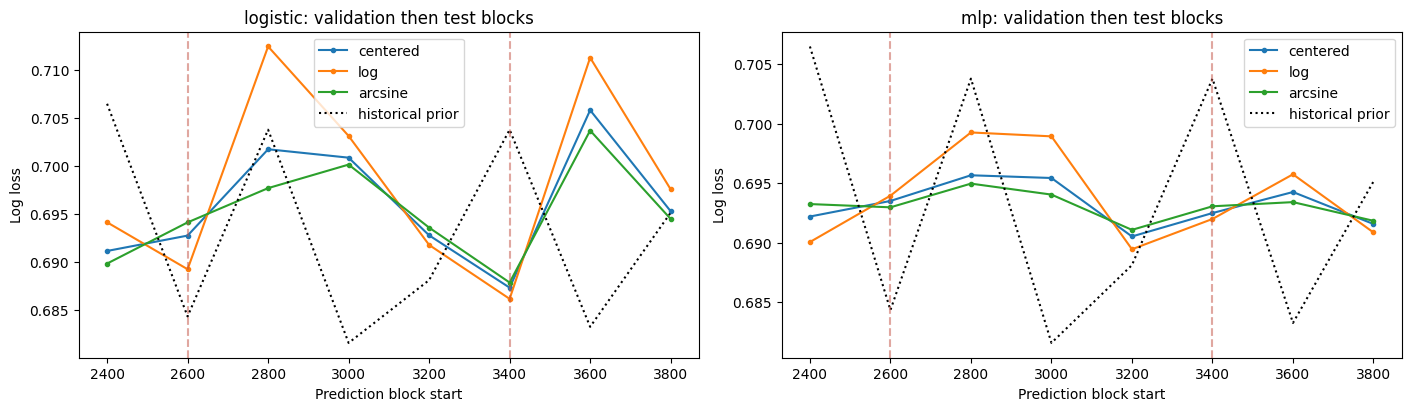


shift_causal_rolling | seed=42 | scaling=standard
Constant historical-prior test loss: 0.692580
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     11   0.703205   0.699569   +0.000000  0.253087  0.512120  0.502500         n/a     0
mlp       centered      5   0.701506   0.690068   +0.000000  0.248432  0.546021  0.543750         n/a     0
tree      centered      -   0.789015   0.797245   +0.000000  0.289131  0.463126  0.511250         n/a     0
logistic  log          11   0.702982   0.699519   -0.000050  0.253063  0.512414  0.502500         n/a     0
mlp       log           5   0.701592   0.690078   +0.000010  0.248438  0.545818  0.543750         n/a     0
tree      log           -   0.789015   0.797245   +0.000000  0.289131  0.463126  0.511250         n/a     0
logistic  arcsine      11   0.703095   0.699542   -0.000027  0.253074  0.512245  0.502500         n/a     0
mlp       arcsine       5   0.701556   

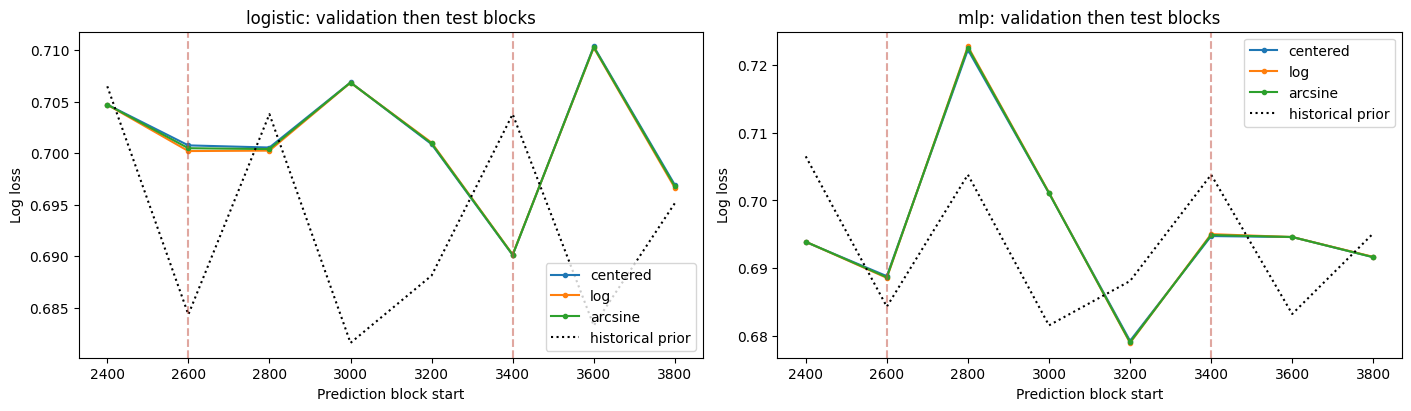

Generating configuration: {'seed': 42, 'n_samples': 4000, 'n_features': 24, 'scenario': 'temporal_factors', 'distribution': 'normal', 'signal_strength': 1.2, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 16, 'rare_fraction': 0.05, 'n_factors': 4, 'observation_noise': 3.0, 'hidden_strength': 3.0, 'contamination_rate': 0.01, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'combined', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.2, 'encoding_block_size': 200, 'history_window': 0, 'temporal_update': 'causal', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 60, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 12, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': False}
Encoder configuration: {'mode': 

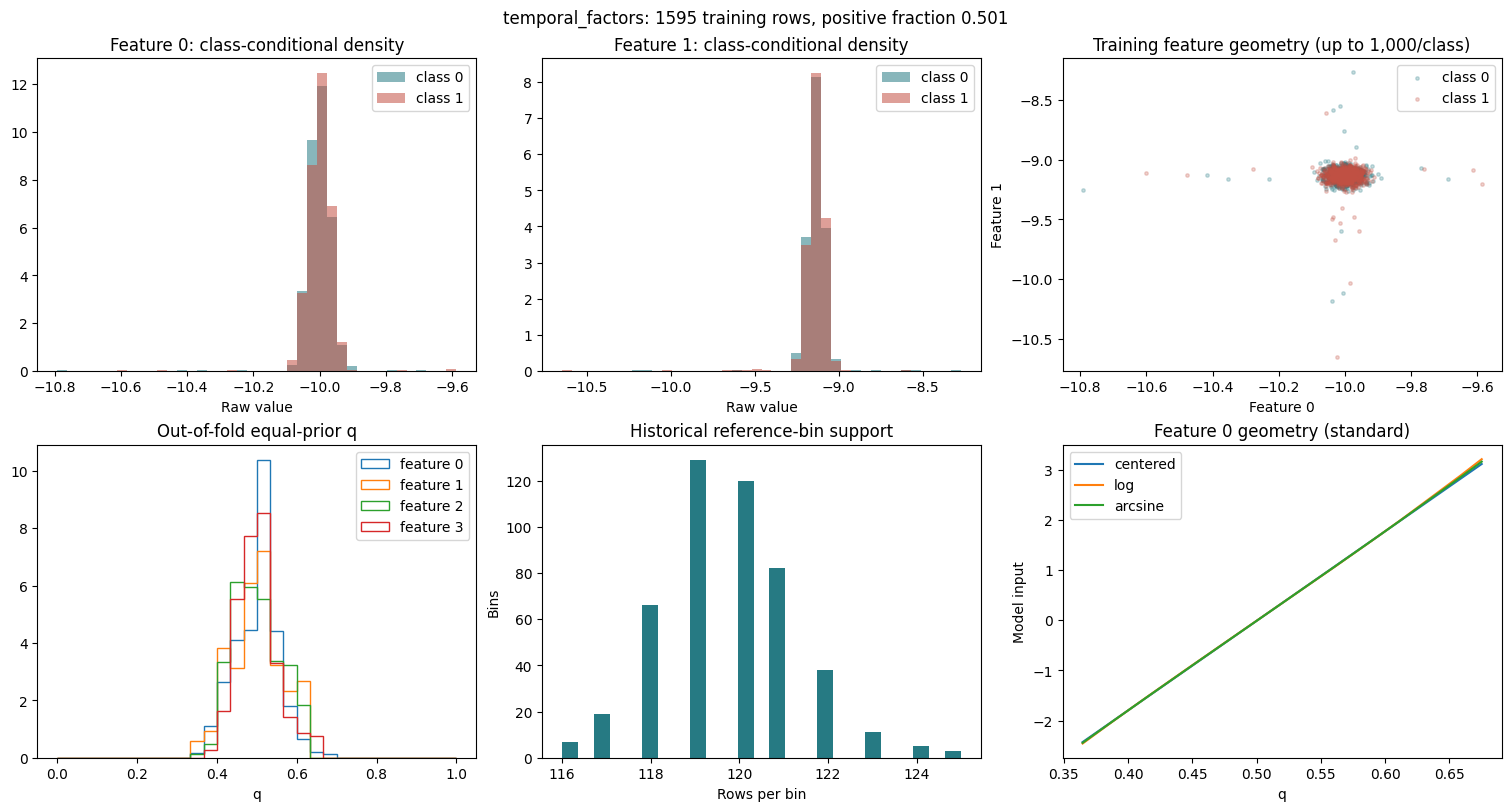

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.3647, 0.3702, 0.5085, 0.659, 0.6752] 0.0000 0.99994 0.4933640354463179
1 [0.3647, 0.365, 0.5044, 0.6149, 0.6186] 0.0000 0.99998 0.5148866988257935
2 [0.3588, 0.3814, 0.4934, 0.6212, 0.6215] 0.0000 0.99998 0.49629562078225925
3 [0.3951, 0.407, 0.4997, 0.6548, 0.6591] 0.0000 0.99993 0.5046752850611002
4 [0.3789, 0.3849, 0.4994, 0.6098, 0.6267] 0.0000 0.99998 0.46804029534405434
5 [0.3022, 0.3284, 0.4996, 0.6811, 0.7431] 0.0000 0.99975 0.47000962258099005
6 [0.3491, 0.3631, 0.4948, 0.6179, 0.6357] 0.0000 0.99996 0.49964072553002803
7 [0.3181, 0.366, 0.5051, 0.6179, 0.6288] 0.0000 0.99995 0.4845417638882774
8 [0.3647, 0.3774, 0.5047, 0.616, 0.6267] 0.0000 0.99997 0.5072389481827158
9 [0.3609, 0.3807, 0.5036, 0.5931, 0.5931] 0.0000 0.99998 0.4985982792561053
10 [0.3414, 0.3649, 0.5053, 0.6554, 0.6596] 0.0000 0.99994 0.5164299281136596
11 [0.3414, 0.356, 0.4949, 0.6444, 0.6511] 0.0000 0.9999

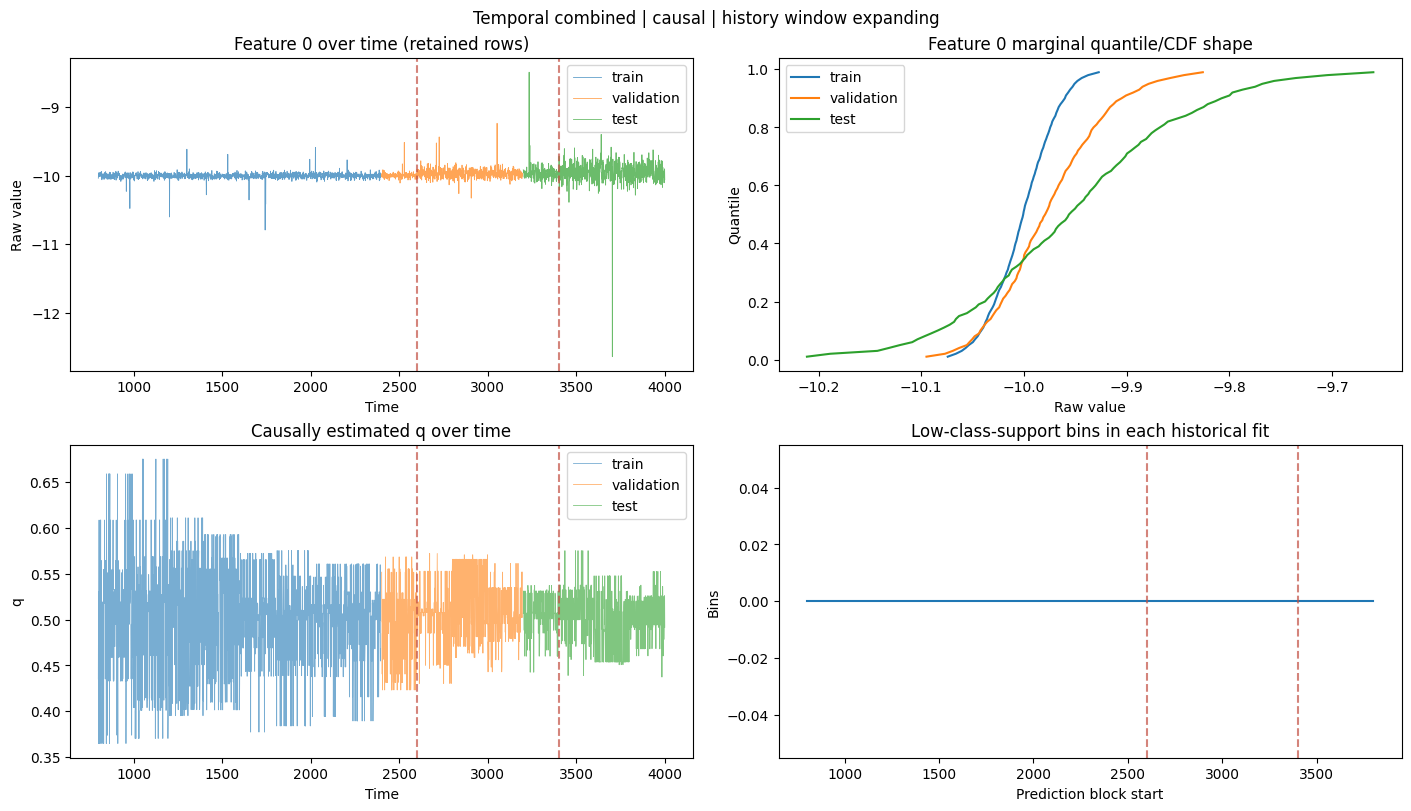


shift_causal_expanding | seed=42 | scaling=none
Constant historical-prior test loss: 0.692725
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered      1   0.693835   0.695083   +0.000000  0.250967  0.483805  0.472500         n/a     0
mlp       centered     11   0.693579   0.692395   +0.000000  0.249624  0.534739  0.541250         n/a     0
tree      centered      -   0.711072   0.720842   +0.000000  0.261641  0.481414  0.495000         n/a     0
logistic  log           1   0.694382   0.695892   +0.000809  0.251370  0.483586  0.486250         n/a     0
mlp       log          11   0.694454   0.691831   -0.000564  0.249342  0.540460  0.528750         n/a     0
tree      log           -   0.711072   0.720842   +0.000000  0.261641  0.481414  0.495000         n/a     0
logistic  arcsine       2   0.693552   0.693318   -0.001765  0.250085  0.482428  0.512500         n/a     0
mlp       arcsine      11   0.693402   0.

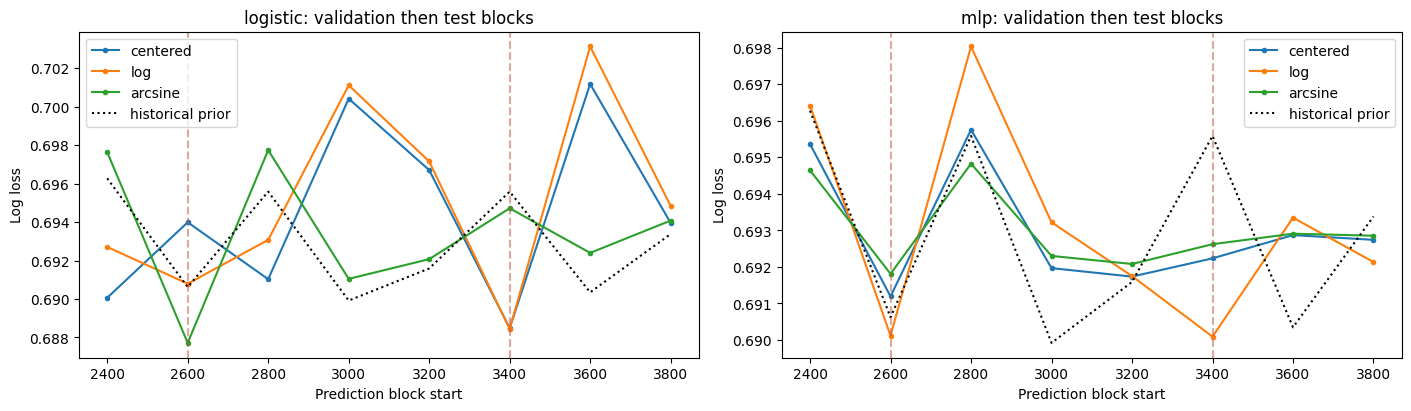


shift_causal_expanding | seed=42 | scaling=standard
Constant historical-prior test loss: 0.692725
Model     Evidence  Epoch     Val LL    Test LL    Delta LL     Brier       AUC  Accuracy  Extreme LL     N
logistic  centered     11   0.695325   0.695376   +0.000000  0.251103  0.509704  0.511250         n/a     0
mlp       centered     11   0.700085   0.690185   +0.000000  0.248524  0.548161  0.531250         n/a     0
tree      centered      -   0.711072   0.720842   +0.000000  0.261641  0.481414  0.495000         n/a     0
logistic  log          11   0.695269   0.695329   -0.000047  0.251080  0.509535  0.512500         n/a     0
mlp       log          11   0.699998   0.690176   -0.000009  0.248520  0.548083  0.536250         n/a     0
tree      log           -   0.711072   0.720842   +0.000000  0.261641  0.481414  0.495000         n/a     0
logistic  arcsine      11   0.695297   0.695352   -0.000023  0.251091  0.509542  0.508750         n/a     0
mlp       arcsine      11   0.700025 

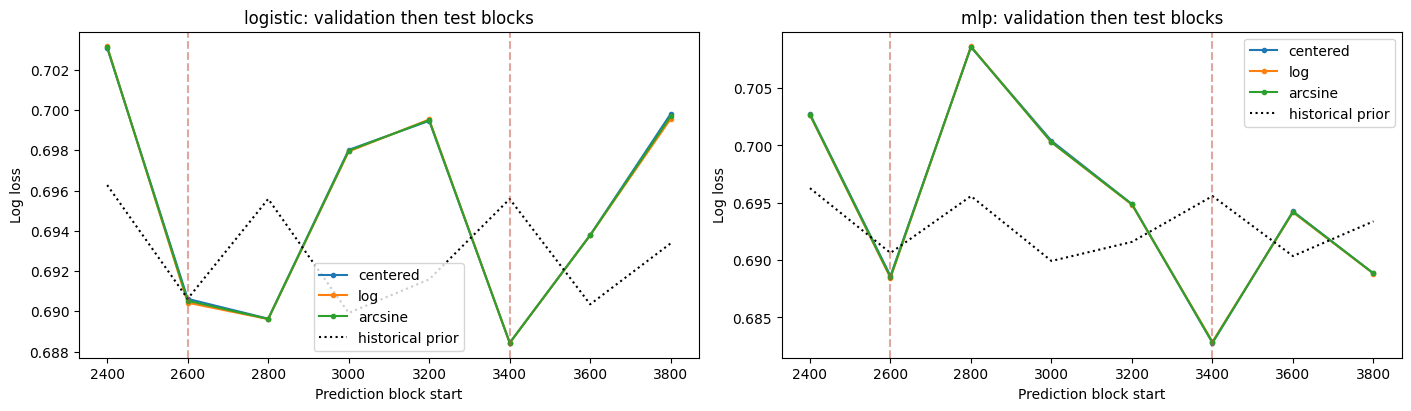

In [17]:
SHIFT_CONFIG = replace(TIME_CONFIG, drift="combined", contamination_rate=0.01,
                       contamination_scale=20.0)
shift_frozen = run_case("shift_frozen", SHIFT_CONFIG, WEAK_ENCODER)
shift_rolling = run_case("shift_causal_rolling", replace(SHIFT_CONFIG, temporal_update="causal"), WEAK_ENCODER)
shift_expanding = run_case("shift_causal_expanding", replace(SHIFT_CONFIG, temporal_update="causal", history_window=0), WEAK_ENCODER)

### 6.11. Targeted Weak Signal and Unreliable Extreme Estimates

Twelve indicators include eight noisy observations of two shared Gaussian factors and four nuisance variables. Signal strength and observation-noise standard deviation are 1.5; hidden-driver strength is 1, with no additional label flips. This is a separate family from 6.6; controlled comparisons are within this family.

The reference uses 12,000 rows, 20 percentile bins and alpha=1. The small-sample control uses 1,200 rows; on those same data, the fine-bin case increases bins to 120 and the extreme-estimate case then lowers alpha to 0.01. The null removes observed-factor signal with the sparse estimator, while support recovery retains 120 bins and alpha=0.01 at 12,000 rows. Different sample counts are separately generated, not nested. Changing null labels also changes stratified split membership.

`TARGET_SEEDS` defaults to 42, 43 and 44. Each case includes raw-feature logistic, MLP and tree fits on matched rows and learner settings. Raw inputs bypass encoding, but their extreme test slices use the evidence-based mask.

Run the validation-audit cell after training. The reference signal check requires standardized raw logistic AUC >= 0.58 and prior-relative log-loss gain >= 0.005. Sparse extreme/null cases target at least 2% extreme informative-feature validation cells; direction accuracy checks whether that estimated certainty is supported. Equal-prior q is not a deployment posterior. Failed checks stay reported and exported; test results do not select cases or tune audit thresholds.

Generating configuration: {'seed': 42, 'n_samples': 12000, 'n_features': 12, 'scenario': 'weak_factors', 'distribution': 'normal', 'signal_strength': 1.5, 'intercept': 0.0, 'label_noise': 0.0, 'class_prior': 0.5, 'n_informative': 8, 'rare_fraction': 0.05, 'n_factors': 2, 'observation_noise': 1.5, 'hidden_strength': 1.0, 'contamination_rate': 0.0, 'contamination_scale': 20.0, 'tail_index': 1.5, 'factor_persistence': 0.8, 'drift': 'none', 'shift_fraction': 0.65, 'recovery_fraction': 0.85, 'drift_location': 3.0, 'drift_scale': 2.0, 'forecast_horizon': 5, 'warmup_fraction': 0.15, 'encoding_block_size': 100, 'history_window': 0, 'temporal_update': 'frozen', 'validation_fraction': 0.2, 'test_fraction': 0.2, 'n_folds': 4, 'scaling': 'standard', 'epochs': 120, 'batch_size': 256, 'hidden_units': 32, 'logistic_lr': 0.02, 'mlp_lr': 0.001, 'weight_decay': 0.0001, 'patience': 20, 'tree_max_depth': 5, 'tree_min_samples_leaf': 20, 'include_raw_baseline': True}
Encoder configuration: {'mode': 'fixed',

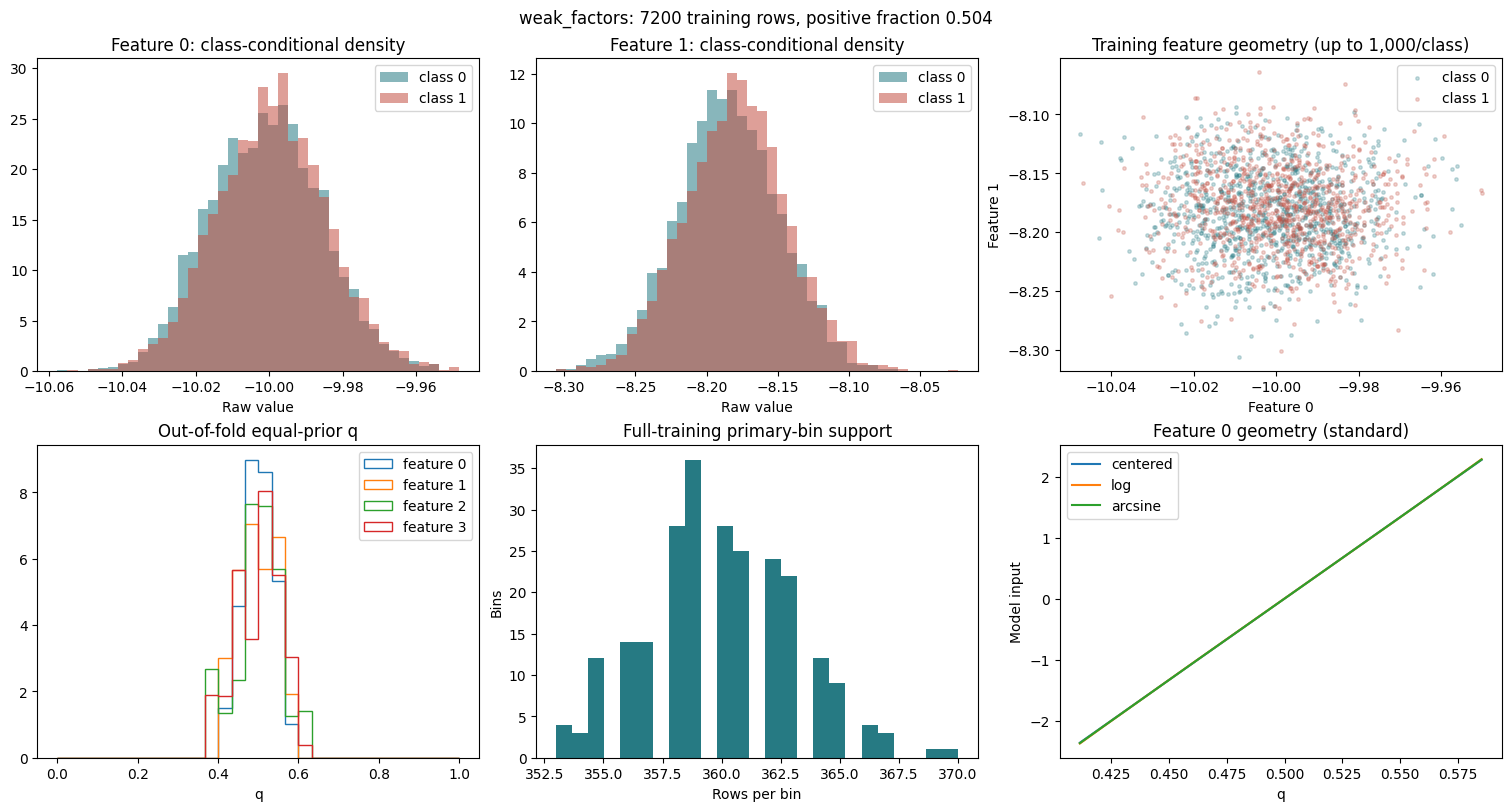

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.4115, 0.4115, 0.4993, 0.5853, 0.5853] 0.0000 0.99999 0.5232218579616166
1 [0.4045, 0.4045, 0.4937, 0.5965, 0.5965] 0.0000 0.99999 0.5308209151710752
2 [0.3676, 0.3676, 0.5029, 0.6098, 0.6098] 0.0000 0.99998 0.5368476259235297
3 [0.3855, 0.3855, 0.5084, 0.6112, 0.6112] 0.0000 0.99999 0.5451711230887379
4 [0.292, 0.292, 0.4956, 0.6469, 0.6469] 0.0000 0.99987 0.5712532764934514
5 [0.3028, 0.3028, 0.5118, 0.6714, 0.6714] 0.0000 0.99983 0.5702062030209795
6 [0.3306, 0.3306, 0.5124, 0.7274, 0.7274] 0.0000 0.99971 0.5926683173114913
7 [0.3003, 0.3003, 0.5048, 0.7228, 0.7228] 0.0000 0.99974 0.5983914546951856
8 [0.4373, 0.4373, 0.4974, 0.5713, 0.5713] 0.0000 1.00000 0.47995015192558427
9 [0.4306, 0.4306, 0.4956, 0.5713, 0.5713] 0.0000 1.00000 0.5013317410264514
10 [0.4191, 0.4191, 0.5029, 0.5796, 0.5796] 0.0000 1.00000 0.49872242992038884
11 [0.4376, 0.4376, 0.4992, 0.5624, 0.5624] 0.0000 1.00

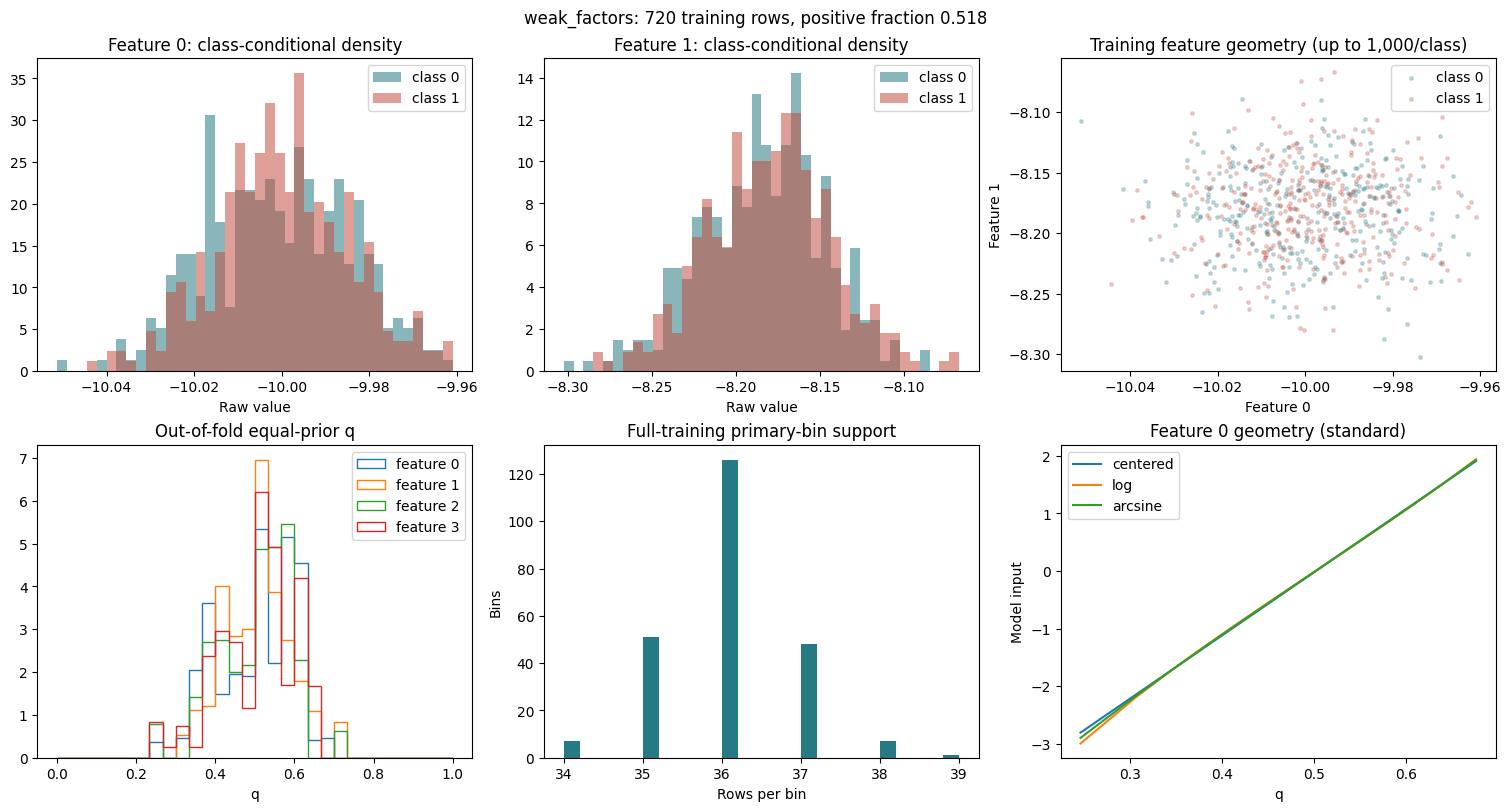

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.2462, 0.2462, 0.5017, 0.6747, 0.6762] 0.0000 0.99967 0.5399904196058132
1 [0.3066, 0.3091, 0.5, 0.7, 0.7] 0.0000 0.99981 0.4927799368003028
2 [0.2623, 0.2623, 0.5017, 0.7101, 0.7196] 0.0000 0.99954 0.5258091183719511
3 [0.2623, 0.2623, 0.5161, 0.6512, 0.6512] 0.0000 0.99964 0.5205205862583152
4 [0.2373, 0.2373, 0.5017, 0.7037, 0.7101] 0.0000 0.99950 0.4931971475148921
5 [0.2636, 0.274, 0.5179, 0.7101, 0.7101] 0.0000 0.99976 0.48773477760351075
6 [0.2029, 0.2029, 0.5, 0.8185, 0.8185] 0.0000 0.99874 0.6300886186462284
7 [0.2534, 0.2534, 0.5089, 0.7471, 0.7471] 0.0000 0.99951 0.5476779133283372
8 [0.3294, 0.3294, 0.5, 0.6747, 0.6747] 0.0000 0.99988 0.4890559448663766
9 [0.3197, 0.3197, 0.5, 0.7656, 0.7656] 0.0000 0.99951 0.5176773724996331
10 [0.2958, 0.2958, 0.5161, 0.7101, 0.7116] 0.0000 0.99982 0.529621960735836
11 [0.229, 0.229, 0.4828, 0.6853, 0.6853] 0.0000 0.99945 0.497156786241317

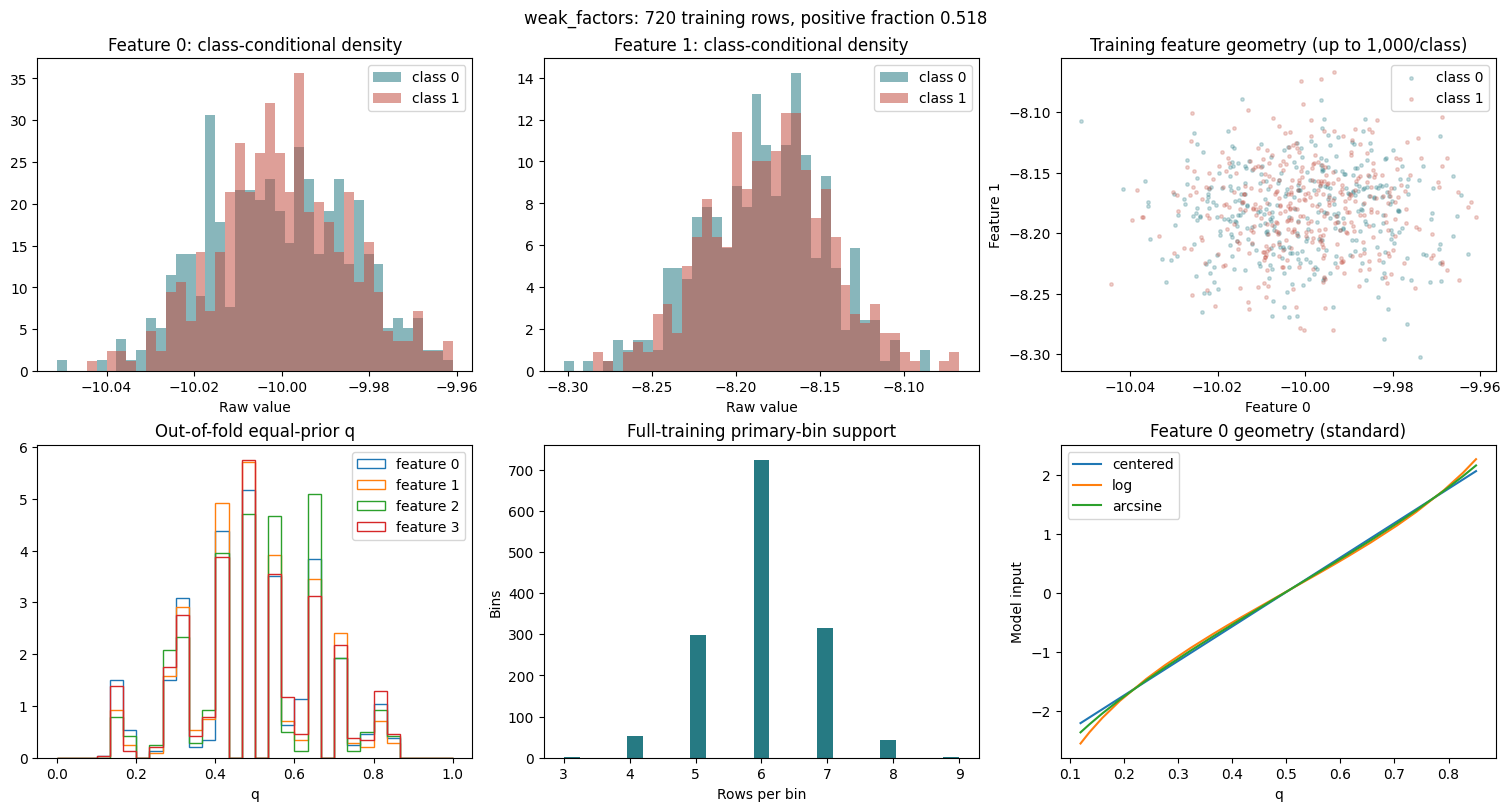

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.12, 0.1367, 0.4872, 0.8507, 0.8507] 0.0000 0.99710 0.563369671871499
1 [0.1367, 0.1597, 0.4872, 0.8268, 0.8507] 0.0000 0.99725 0.4527122559510473
2 [0.1367, 0.1597, 0.4885, 0.8507, 0.8514] 0.0000 0.99739 0.5400522286005671
3 [0.1195, 0.1373, 0.4872, 0.8507, 0.8507] 0.0000 0.99708 0.5318239061739459
4 [0.1195, 0.1367, 0.4872, 0.8507, 0.8693] 0.0000 0.99670 0.49852817331242133
5 [0.1367, 0.1597, 0.4872, 0.8507, 0.8514] 0.0000 0.99721 0.5113844442212453
6 [0.1367, 0.1373, 0.4872, 0.8514, 0.8514] 0.0000 0.99717 0.5846744597507552
7 [0.1195, 0.1367, 0.4872, 0.8507, 0.8699] 0.0000 0.99691 0.53541655399402
8 [0.1367, 0.1597, 0.4872, 0.8507, 0.8693] 0.0000 0.99695 0.4837210560066753
9 [0.1367, 0.1373, 0.4885, 0.8462, 0.8514] 0.0000 0.99717 0.5283123826594867
10 [0.1195, 0.1367, 0.4872, 0.8507, 0.8514] 0.0000 0.99698 0.5347173397408658
11 [0.1367, 0.1597, 0.4872, 0.8507, 0.8514] 0.0000 0.99733 

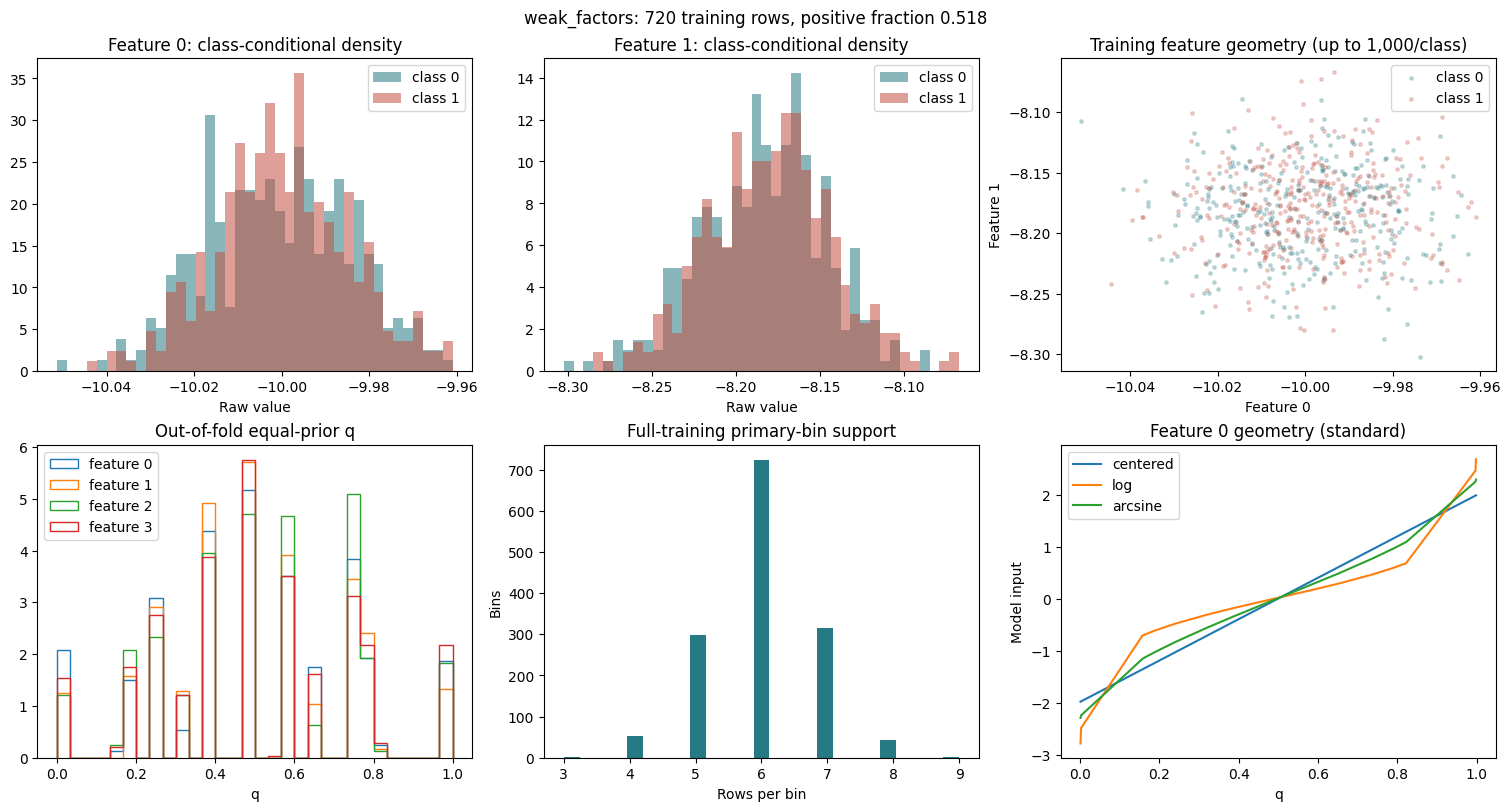

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.0016, 0.0019, 0.4816, 0.9979, 0.9979] 0.1319 0.91076 0.5630683530220735
1 [0.0019, 0.0023, 0.4816, 0.9973, 0.9979] 0.0861 0.89681 0.4527508865727685
2 [0.0019, 0.0023, 0.4834, 0.9979, 0.9979] 0.1014 0.89983 0.539920884486715
3 [0.0015, 0.0019, 0.4816, 0.9979, 0.9979] 0.1236 0.90807 0.5319475241634539
4 [0.0015, 0.0019, 0.4816, 0.9979, 0.9982] 0.1014 0.89829 0.4985204471880771
5 [0.0019, 0.0023, 0.4816, 0.9979, 0.9979] 0.1042 0.90332 0.5112260586721882
6 [0.0019, 0.0019, 0.4816, 0.9979, 0.9979] 0.1611 0.91401 0.5846010615694848
7 [0.0015, 0.0019, 0.4816, 0.9979, 0.9982] 0.1306 0.90983 0.5352929360045121
8 [0.0019, 0.0023, 0.4816, 0.9979, 0.9982] 0.0917 0.89674 0.4837442343797081
9 [0.0019, 0.0019, 0.4834, 0.9978, 0.9979] 0.1028 0.90050 0.5283123826594867
10 [0.0015, 0.0019, 0.4816, 0.9979, 0.9979] 0.1278 0.90962 0.5347482442382429
11 [0.0019, 0.0023, 0.4816, 0.9979, 0.9979] 0.1014 0.898

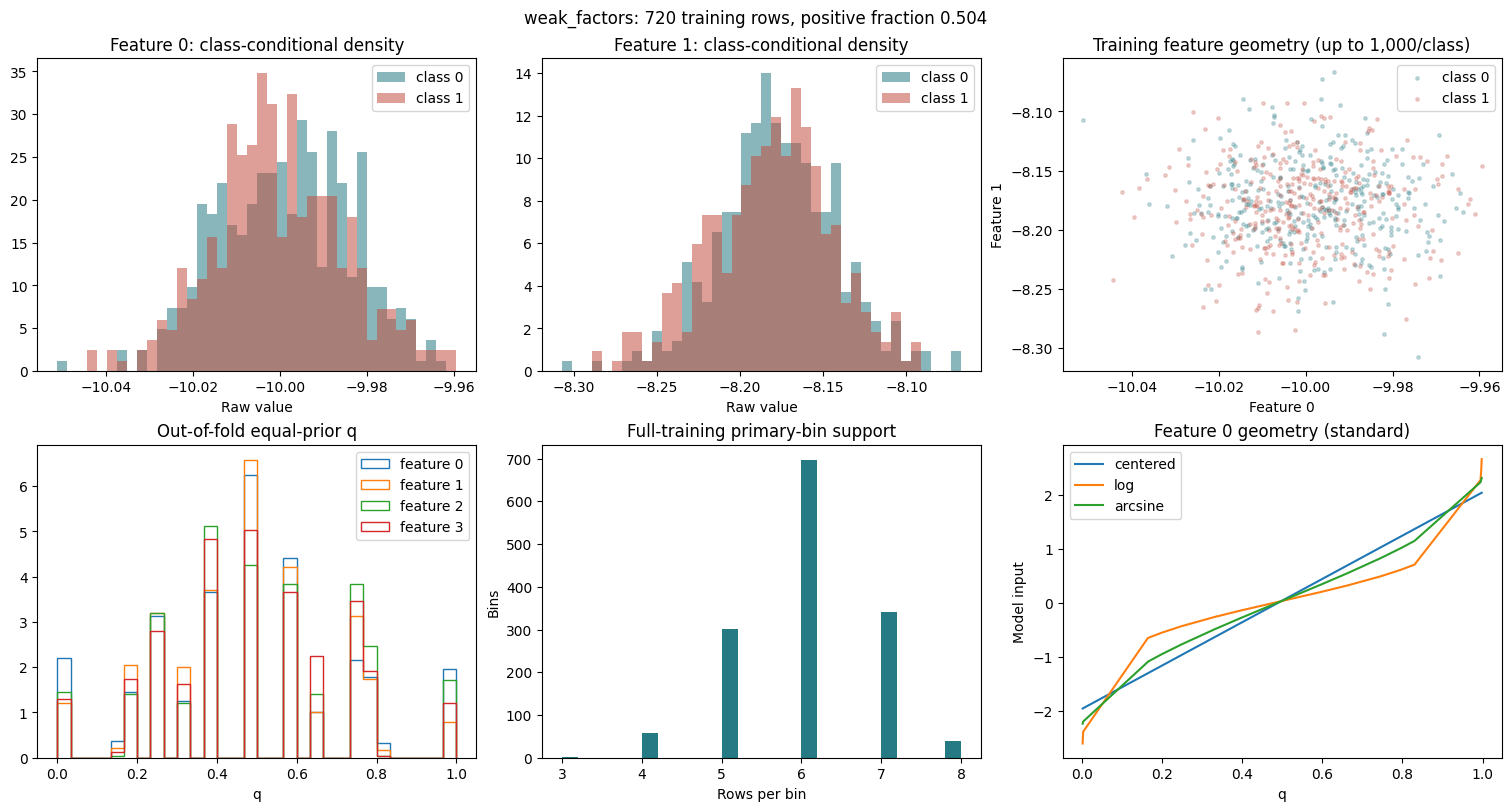

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.0019, 0.0019, 0.4963, 0.998, 0.998] 0.1389 0.91522 0.5452230478968447
1 [0.0016, 0.002, 0.4963, 0.9979, 0.9983] 0.0667 0.88778 0.4629372410121073
2 [0.0019, 0.0024, 0.4963, 0.998, 0.998] 0.1056 0.89969 0.49356822618854707
3 [0.0016, 0.0024, 0.4963, 0.9975, 0.998] 0.0833 0.89449 0.45046338094466437
4 [0.0019, 0.002, 0.4963, 0.998, 0.998] 0.1292 0.90747 0.5386562338433997
5 [0.002, 0.0024, 0.4963, 0.998, 0.998] 0.1111 0.90188 0.47797686567740044
6 [0.0016, 0.002, 0.4963, 0.998, 0.9983] 0.0861 0.89438 0.48205122269293393
7 [0.0019, 0.002, 0.4963, 0.998, 0.998] 0.1056 0.90078 0.4803304241806915
8 [0.0016, 0.002, 0.4963, 0.998, 0.998] 0.1250 0.90443 0.5104829810712164
9 [0.0016, 0.0024, 0.4963, 0.9975, 0.998] 0.0917 0.89415 0.5585071494162404
10 [0.0019, 0.0021, 0.4963, 0.9975, 0.998] 0.1069 0.90234 0.5240410213672246
11 [0.0019, 0.002, 0.4963, 0.998, 0.9983] 0.1250 0.90694 0.51730830073076

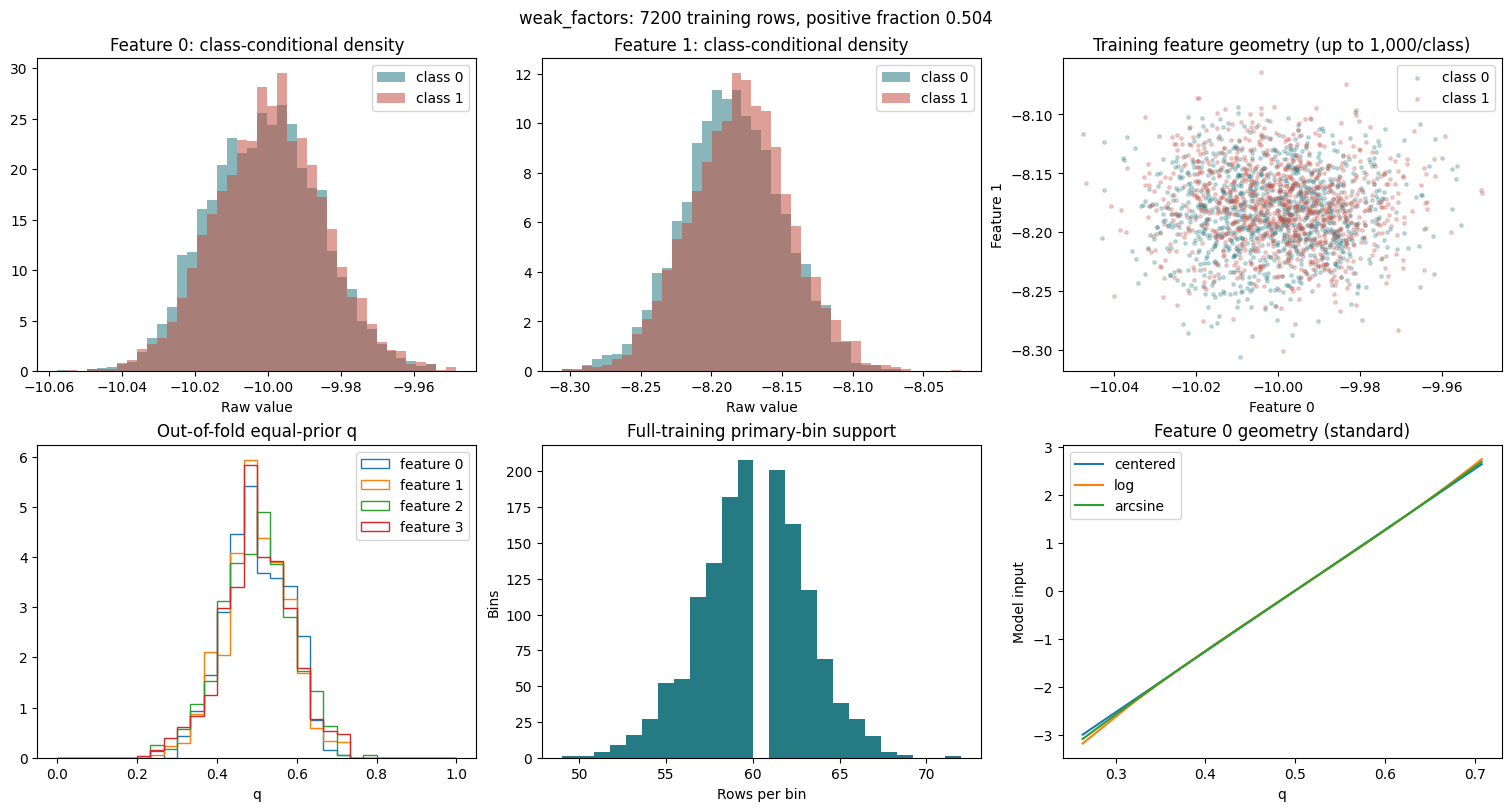

OOF evidence: feature, q[min,p01,median,p99,max], extreme share, centered/WoE correlation, q AUC
0 [0.2633, 0.3295, 0.4956, 0.6626, 0.7074] 0.0000 0.99983 0.5086037662235041
1 [0.2633, 0.3058, 0.4956, 0.7007, 0.7236] 0.0000 0.99975 0.5154581658303867
2 [0.236, 0.2985, 0.5062, 0.685, 0.7695] 0.0000 0.99962 0.5256496346624919
3 [0.2018, 0.2791, 0.4956, 0.7236, 0.7297] 0.0000 0.99956 0.5208416158807609
4 [0.1889, 0.2576, 0.4956, 0.7407, 0.7695] 0.0000 0.99942 0.549744594017305
5 [0.1973, 0.2576, 0.5062, 0.7356, 0.7794] 0.0000 0.99940 0.5511314705729835
6 [0.2413, 0.2693, 0.5058, 0.7465, 0.8066] 0.0000 0.99945 0.5715529529493689
7 [0.1569, 0.2468, 0.4956, 0.7841, 0.8154] 0.0000 0.99902 0.5754230889848088
8 [0.2065, 0.3074, 0.5067, 0.6695, 0.685] 0.0000 0.99957 0.4983986774880978
9 [0.3007, 0.3365, 0.5062, 0.6556, 0.6704] 0.0000 0.99992 0.4884986282866794
10 [0.2919, 0.343, 0.5054, 0.6626, 0.7074] 0.0000 0.99990 0.49079147920329513
11 [0.3074, 0.3295, 0.5062, 0.6538, 0.6699] 0.0000 0.99992 

In [18]:
TARGET_SEEDS = (CONFIG.seed, CONFIG.seed + 1, CONFIG.seed + 2)
TARGET_CONFIG = replace(WEAK_CONFIG, n_samples=12000, n_features=12, n_informative=8,
                        n_factors=2, signal_strength=1.5, observation_noise=1.5,
                        hidden_strength=1.0, label_noise=0.0, contamination_rate=0.0,
                        n_folds=4, include_raw_baseline=True, epochs=120, patience=20)
TARGET_ENCODER = replace(WEAK_ENCODER, mode="fixed", num_bins=20, alpha=1.0)
SMALL_TARGET_CONFIG = replace(TARGET_CONFIG, n_samples=1200)
FINE_TARGET_ENCODER = replace(TARGET_ENCODER, num_bins=120)
EXTREME_TARGET_ENCODER = replace(FINE_TARGET_ENCODER, alpha=0.01)
TARGET_CASES = {
    "target_weak_reference": (TARGET_CONFIG, TARGET_ENCODER),
    "target_weak_small": (SMALL_TARGET_CONFIG, TARGET_ENCODER),
    "target_weak_fine": (SMALL_TARGET_CONFIG, FINE_TARGET_ENCODER),
    "target_weak_extreme": (SMALL_TARGET_CONFIG, EXTREME_TARGET_ENCODER),
    "target_weak_null": (replace(SMALL_TARGET_CONFIG, signal_strength=0.0), EXTREME_TARGET_ENCODER),
    "target_weak_supported": (TARGET_CONFIG, EXTREME_TARGET_ENCODER),
}
TARGET_RESULTS = {
    name: run_case(name, case_config, encoder_config, seeds=TARGET_SEEDS)
    for name, (case_config, encoder_config) in TARGET_CASES.items()
}

In [19]:
TARGET_AUDIT_RULES = {
    "raw_validation_min_auc": 0.58,
    "raw_validation_min_log_loss_gain": 0.005,
    "min_validation_extreme_cell_fraction": 0.02,
}
print("Validation audit; raw signal check applies to standardized inputs; null is expected to lack signal")
for name, results in TARGET_RESULTS.items():
    for result in results:
        raw = next(row for row in result["summary"]
                   if row["model"] == "logistic" and row["representation"] == "raw")
        records = result["diagnostics"]["splits"]["validation"][:result["config"]["n_informative"]]
        extreme_count = sum(record["extreme_count"] for record in records)
        agreement = sum(record["extreme_count"] * record["extreme_direction_accuracy"]
                        for record in records if record["extreme_count"])
        extreme_fraction = statistics.fmean(record["extreme_fraction"] for record in records)
        gain = result["baselines"]["validation"]["log_loss"] - raw["validation_log_loss"]
        signal_pass = (raw["validation_roc_auc"] is not None
                       and raw["validation_roc_auc"] >= TARGET_AUDIT_RULES["raw_validation_min_auc"]
                       and gain >= TARGET_AUDIT_RULES["raw_validation_min_log_loss_gain"])
        audit = {
            "raw_validation_auc": raw["validation_roc_auc"],
            "raw_validation_log_loss_gain": gain,
            "raw_validation_signal_pass": signal_pass if result["config"]["scaling"] == "standard" else None,
            "validation_extreme_cell_fraction": extreme_fraction,
            "validation_extreme_cell_count": extreme_count,
            "validation_extreme_direction_accuracy": agreement / extreme_count if extreme_count else None,
            "extreme_estimates_present": extreme_fraction >= TARGET_AUDIT_RULES["min_validation_extreme_cell_fraction"],
            "reference_signal_required": name == "target_weak_reference",
            "extreme_estimates_required": name in {"target_weak_extreme", "target_weak_null"},
        }
        result["target_audit"] = audit
        if result["config"]["scaling"] == "standard":
            print(name, "seed", result["config"]["seed"], audit)
            if audit["reference_signal_required"] and not signal_pass:
                print("Reference learnability check NOT MET; retain this run and do not assume observed signal was learned.")
            if audit["extreme_estimates_required"] and not audit["extreme_estimates_present"]:
                print("Extreme-estimate target NOT MET; retain this run and do not infer an extreme-tail comparison.")

Validation audit; raw signal check applies to standardized inputs; null is expected to lack signal
target_weak_reference seed 42 {'raw_validation_auc': 0.6934207666060828, 'raw_validation_log_loss_gain': 0.060419568640705856, 'raw_validation_signal_pass': True, 'validation_extreme_cell_fraction': 0.0, 'validation_extreme_cell_count': 0, 'validation_extreme_direction_accuracy': None, 'extreme_estimates_present': False, 'reference_signal_required': True, 'extreme_estimates_required': False}
target_weak_reference seed 43 {'raw_validation_auc': 0.6864421140356969, 'raw_validation_log_loss_gain': 0.05632723527751726, 'raw_validation_signal_pass': True, 'validation_extreme_cell_fraction': 0.0, 'validation_extreme_cell_count': 0, 'validation_extreme_direction_accuracy': None, 'extreme_estimates_present': False, 'reference_signal_required': True, 'extreme_estimates_required': False}
target_weak_reference seed 44 {'raw_validation_auc': 0.6918234211186043, 'raw_validation_log_loss_gain': 0.05848

### 6.12. Compare Regimes and Mechanisms

Summaries preserve condition, seed, scaling and model family. Mean deltas are paired against centered evidence within each run, including raw-feature controls where enabled. Seed standard deviation is shown only with repeated seeds; it is not a confidence interval. Only executed subsections are included. There are 26 named conditions: the original 20 plus six targeted signal/support controls. The original conditions default to one seed; the targeted family defaults to three seeds and includes three raw-feature controls per scaling. A complete default run fits 792 models.

Compare weak-factor controls to separate limited information from lack of signal; compare matched estimation settings to study unstable q; compare frozen and causal temporal policies to study stale evidence. Check the targeted validation audits before interpreting that family as learned weak signal or unreliable extreme evidence. Failed checks remain included. Averages across these conditions are not estimates over independent replications. Temporal uncertainty requires repeated paths or time-aware resampling, not an IID row bootstrap.

Model dependence is itself a finding. A native-scale representation ranking can reverse between logistic regression and MLP, and can change after standardization. Selected epochs can also differ. Report these interactions alongside losses relative to the historical-prior baseline rather than requiring a common representation ranking.

In [20]:
comparison_rows = []
for case, case_results in RESULTS_BY_CASE.items():
    for result in case_results:
        baselines = {row["model"]: row["test_log_loss"] for row in result["summary"]
                     if row["representation"] == "centered"}
        for row in result["summary"]:
            comparison_rows.append({"case": case, "seed": result["config"]["seed"], **row,
                                    "delta_test_log_loss": row["test_log_loss"] - baselines[row["model"]]})

groups = {}
for row in comparison_rows:
    key = (row["case"], row["scaling"], row["model"], row["representation"])
    groups.setdefault(key, []).append(row)
print(f"{'Case':<24} {'Scaling':<8} {'Model':<9} {'Evidence':<9} {'Seeds':>5} {'Mean LL':>10} {'SD LL':>10} {'Mean delta':>11}")
for (case, scaling, model, representation), rows in groups.items():
    losses = [row["test_log_loss"] for row in rows]
    deviation = f"{statistics.stdev(losses):.6f}" if len(losses) > 1 else "n/a"
    print(f"{case:<24} {scaling:<8} {model:<9} {representation:<9} {len(rows):>5} "
          f"{statistics.fmean(losses):>10.6f} {deviation:>10} "
          f"{statistics.fmean(row['delta_test_log_loss'] for row in rows):>+11.6f}")

Case                     Scaling  Model     Evidence  Seeds    Mean LL      SD LL  Mean delta
moderate_additive        none     logistic  centered      1   0.535085        n/a   +0.000000
moderate_additive        none     mlp       centered      1   0.538562        n/a   +0.000000
moderate_additive        none     tree      centered      1   0.682118        n/a   +0.000000
moderate_additive        none     logistic  log           1   0.534550        n/a   -0.000535
moderate_additive        none     mlp       log           1   0.539683        n/a   +0.001121
moderate_additive        none     tree      log           1   0.682118        n/a   +0.000000
moderate_additive        none     logistic  arcsine       1   0.534713        n/a   -0.000372
moderate_additive        none     mlp       arcsine       1   0.537537        n/a   -0.001025
moderate_additive        none     tree      arcsine       1   0.682118        n/a   +0.000000
moderate_additive        standard logistic  centered      1 

## 7. Export the Case Suite

The version-2 JSON bundle stores each executed condition's configurations, versions, split IDs, labels, predictions, training histories, evidence/support diagnostics, constant-prior baselines and test-slice metrics. Temporal runs include historical fit ranges, label-maturity audits, CDF drift and per-block losses. Targeted runs include optional raw-feature fits and the validation audits from 6.11, including failed checks. The bundle records actual seeds by condition and the targeted audit thresholds. CSV contains condition/seed/scaling identifiers, source metrics and paired log-loss deltas. `run_experiment` still returns a single run; the notebook bundles runs under `cases`.

Each export creates a fresh directory and includes only conditions executed in the current kernel. Rerun the targeted audit and cross-case summary after changing a targeted condition. The complete default suite has 26 conditions and 792 fits: 20 original conditions at one seed (360 fits) plus six targeted conditions at three seeds with raw controls (432 fits). Altered seeds or scaling modes change that budget. Displayed plots and fitted models are not saved. Model- and scale-dependent rankings are findings; a universal ordering of representations is not assumed.

In [21]:
import csv
from datetime import datetime, timezone
import json

if not comparison_rows:
    raise RuntimeError("Run the case subsections and cross-case summary before exporting")
case_seeds = {
    case: sorted({result["config"]["seed"] for result in results})
    for case, results in RESULTS_BY_CASE.items()
}
bundle = {
    "schema_version": 2,
    "base_config": asdict(CONFIG),
    "base_encoder_config": asdict(ENCODER_CONFIG),
    "seeds": sorted({seed for seeds in case_seeds.values() for seed in seeds}),
    "case_seeds": case_seeds,
    "scalings": list(SCALINGS),
    "target_audit_rules": globals().get("TARGET_AUDIT_RULES", {}),
    "cases": RESULTS_BY_CASE,
    "summary": comparison_rows,
}
run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output_directory = STUDY_ROOT / "results" / run_name
output_directory.mkdir(parents=True, exist_ok=False)
with (output_directory / "results.json").open("w", encoding="utf-8") as handle:
    json.dump(bundle, handle, indent=2, allow_nan=False)
with (output_directory / "summary.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(comparison_rows[0]))
    writer.writeheader()
    writer.writerows(comparison_rows)
print("Exported cases:", list(RESULTS_BY_CASE))
print("Fitted models:", sum(len(result["summary"]) for results in RESULTS_BY_CASE.values() for result in results))
print("Results:", output_directory)

Exported cases: ['moderate_additive', 'separated_classes', 'rare_regions', 'variance_tails', 'sparse_imbalanced', 'weak_factors', 'weak_less_hidden', 'weak_null', 'weak_contaminated', 'weak_larger_tails', 'weak_raw_clean', 'weak_raw_contaminated', 'weak_fine_bins', 'weak_low_smoothing', 'time_stable', 'time_covariate', 'time_concept', 'shift_frozen', 'shift_causal_rolling', 'shift_causal_expanding', 'target_weak_reference', 'target_weak_small', 'target_weak_fine', 'target_weak_extreme', 'target_weak_null', 'target_weak_supported']
Fitted models: 792
Results: /content/evidence_representation_study/results/20261016T152546370593Z
